# ML5: DecisionTrees

**Автор: [howardeb]**
**Дата: 2026-10-23 - 2026-10-24**

## 1. Предобработка данных
Download data from Don’tGetKicked competition.Design train/validation/test split.

Use the "PurchDate" field to split, test must be later in time than validation, same goes for validation and train: train.PurchDate < valid.PurchDate < test.PurchDate.

Use the first 33% of the data for the training, the last 33% of the data for the test, and the middle 33% for the validation set. Don't use the test dataset until the end!

Use LabelEncoder or OneHotEncoder from sklearn to preprocess categorical variables. Be careful with data leakage (fit Encoder to training and apply to validation & test). Consider another coding approach if you encounter new categorical values in validation & test (not seen in training), for example: https://contrib.scikit-learn.org/category_encoders/count.html

In [1]:
import signal
from contextlib import contextmanager

class TimeoutError(Exception):
    pass

@contextmanager
def timeout(seconds=120):
    def _handler(signum, frame):
        raise TimeoutError(f"Блок превысил {seconds} с — прерываю")
    old_handler = signal.signal(signal.SIGALRM, _handler)
    signal.alarm(seconds)
    try:
        yield
    finally:
        signal.alarm(0)
        signal.signal(signal.SIGALRM, old_handler)

print("timeout(120) готов")

timeout(120) готов


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


from category_encoders import CountEncoder
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

df = pd.read_csv('data/training.csv')
print(f"Размер данных: {df.shape}")
print(f"Первые строки: {df.head(10)}")
df.info()
df.describe()

df['IsBadBuy'].value_counts(normalize=True)

Размер данных: (72983, 34)
Первые строки:    RefId  IsBadBuy  PurchDate Auction  VehYear  VehicleAge        Make  \
0      1         0  12/7/2009   ADESA     2006           3       MAZDA   
1      2         0  12/7/2009   ADESA     2004           5       DODGE   
2      3         0  12/7/2009   ADESA     2005           4       DODGE   
3      4         0  12/7/2009   ADESA     2004           5       DODGE   
4      5         0  12/7/2009   ADESA     2005           4        FORD   
5      6         0  12/7/2009   ADESA     2004           5  MITSUBISHI   
6      7         0  12/7/2009   ADESA     2004           5         KIA   
7      8         0  12/7/2009   ADESA     2005           4        FORD   
8      9         0  12/7/2009   ADESA     2007           2         KIA   
9     10         0  12/7/2009   ADESA     2007           2        FORD   

                 Model Trim           SubModel   Color Transmission  \
0               MAZDA3    i         4D SEDAN I     RED         AUTO   
1

IsBadBuy
0    0.877012
1    0.122988
Name: proportion, dtype: float64

In [3]:
missing = df.isnull().sum()
missing[missing>0].sort_values(ascending=False)

AUCGUART                             69564
PRIMEUNIT                            69564
WheelType                             3174
WheelTypeID                           3169
Trim                                  2360
MMRCurrentAuctionAveragePrice          315
MMRCurrentAuctionCleanPrice            315
MMRCurrentRetailAveragePrice           315
MMRCurrentRetailCleanPrice             315
MMRAcquisitionAuctionCleanPrice         18
MMRAcquisitionAuctionAveragePrice       18
MMRAcquisitionRetailAveragePrice        18
MMRAcquisitonRetailCleanPrice           18
Transmission                             9
SubModel                                 8
Color                                    8
Size                                     5
Nationality                              5
TopThreeAmericanName                     5
dtype: int64

In [4]:
df['PurchDate'] = pd.to_datetime(df['PurchDate'])
df = df.sort_values('PurchDate', kind='mergesort').reset_index(drop=True)

n = len(df)
i_train_end = int(n * 0.33)
i_valid_end = int(n * 0.66)

train = df.iloc[:i_train_end].copy()
valid = df.iloc[i_train_end:i_valid_end].copy()
test  = df.iloc[i_valid_end:].copy()

print(f"n_total = {n}")
print(f"train: {len(train):>6} ({len(train)/n:.2%})  {train['PurchDate'].min().date()} — {train['PurchDate'].max().date()}")
print(f"valid: {len(valid):>6} ({len(valid)/n:.2%})  {valid['PurchDate'].min().date()} — {valid['PurchDate'].max().date()}")
print(f"test : {len(test):>6} ({len(test)/n:.2%})  {test['PurchDate'].min().date()} — {test['PurchDate'].max().date()}")

assert len(train) > 0 and len(valid) > 0 and len(test) > 0, "Пустой сплит"
assert train['PurchDate'].max() <= valid['PurchDate'].min(), "train залезает в valid"
assert valid['PurchDate'].max() <= test['PurchDate'].min(),  "valid залезает в test"
assert len(train) + len(valid) + len(test) == n

n_total = 72983
train:  24084 (33.00%)  2009-01-05 — 2009-09-11
valid:  24084 (33.00%)  2009-09-11 — 2010-05-11
test :  24815 (34.00%)  2010-05-11 — 2010-12-30


In [5]:
print(f"Train: {train['IsBadBuy'].mean() * 100:.2f}% плохих машин")
print(f"Valid: {valid['IsBadBuy'].mean() * 100:.2f}% плохих машин")
print(f"Test:  {test['IsBadBuy'].mean() * 100:.2f}% плохих машин")

Train: 11.44% плохих машин
Valid: 13.12% плохих машин
Test:  12.34% плохих машин


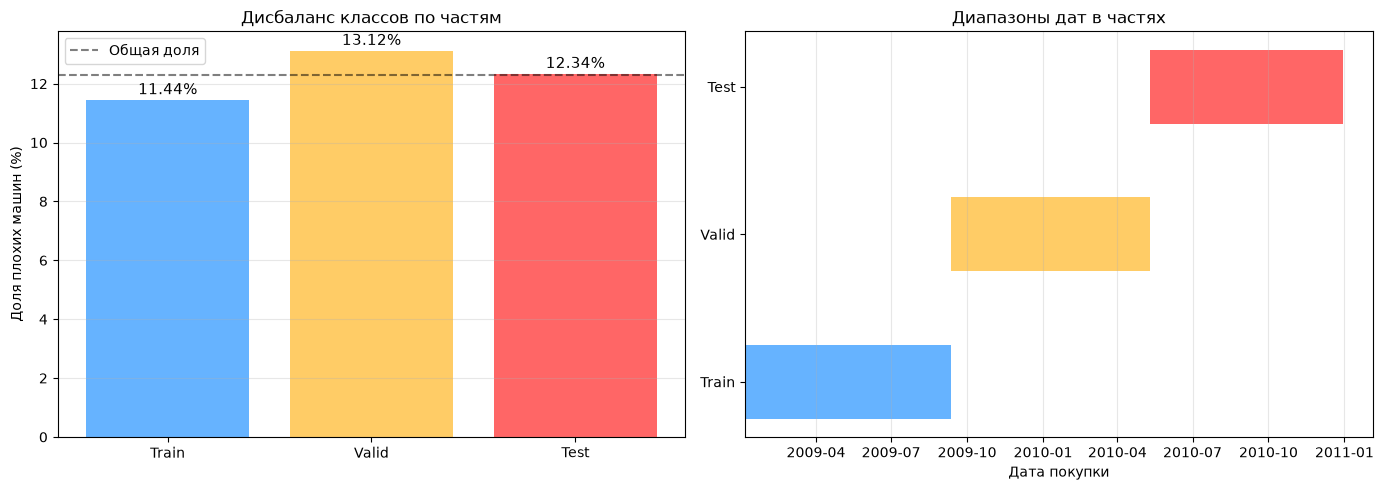

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

parts = ['Train', 'Valid', 'Test']
bad_rates = [
    train['IsBadBuy'].mean() * 100,
    valid['IsBadBuy'].mean() * 100,
    test['IsBadBuy'].mean() * 100
]

colors = ['#66b3ff', '#ffcc66', '#ff6666']
bars = axes[0].bar(parts, bad_rates, color=colors)

for bar, val in zip(bars, bad_rates):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.2,
        f'{val:.2f}%',
        ha='center', fontsize=11
    )

axes[0].axhline(y=df['IsBadBuy'].mean() * 100, color='black',
                linestyle='--', alpha=0.5, label='Общая доля')
axes[0].set_ylabel('Доля плохих машин (%)')
axes[0].set_title('Дисбаланс классов по частям')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

for i, (name, part) in enumerate([('Train', train), ('Valid', valid), ('Test', test)]):
    axes[1].barh(name, (part['PurchDate'].max() - part['PurchDate'].min()).days,
                 left=part['PurchDate'].min(), color=colors[i], height=0.5)

axes[1].set_xlabel('Дата покупки')
axes[1].set_title('Диапазоны дат в частях')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
BINARY_FLAG_COLS = ['AUCGUART', 'PRIMEUNIT']
NAN_FLAG_COLS    = ['WheelType', 'WheelTypeID', 'Trim']
MMR_COLS = [
    'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice',
    'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice',
    'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionAuctionAveragePrice',
    'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice'
]
SMALL_CAT_COLS = [
    'Transmission', 'SubModel', 'Color',
    'Size', 'Nationality', 'TopThreeAmericanName'
]


def fit_fillna_stats(train_df: pd.DataFrame) -> dict:
    stats = {}
    for col in MMR_COLS:
        stats[f'median__{col}'] = train_df[col].median()
    for col in SMALL_CAT_COLS:
        stats[f'mode__{col}'] = train_df[col].mode().iloc[0]
    stats['median__WheelTypeID'] = train_df['WheelTypeID'].median()
    return stats


def apply_fillna(df_part, stats):
    out = df_part.copy()

    for col in BINARY_FLAG_COLS:
        out[f'{col}_is_present'] = out[col].notnull().astype(int)
        out = out.drop(columns=[col])

    for col in NAN_FLAG_COLS:
        out[f'{col}_is_nan'] = out[col].isnull().astype(int)

    out['WheelType'] = out['WheelType'].fillna('unknown')
    out['Trim']      = out['Trim'].fillna('unknown')

    out['WheelTypeID'] = out['WheelTypeID'].fillna(-1).astype(int)

    for col in MMR_COLS:
        out[col] = out[col].fillna(stats[f'median__{col}'])

    for col in SMALL_CAT_COLS:
        out[col] = out[col].fillna(stats[f'mode__{col}'])

    return out


fill_stats = fit_fillna_stats(train)

train = apply_fillna(train, fill_stats)
valid = apply_fillna(valid, fill_stats)
test  = apply_fillna(test,  fill_stats)

for name, part in [('train', train), ('valid', valid), ('test', test)]:
    n_miss = part.isnull().sum().sum()
    print(f"{name}: пропусков = {n_miss}, shape = {part.shape}")
    assert n_miss == 0, f"{name}: остались пропуски:\n{part.isnull().sum()[part.isnull().sum()>0]}"

print("\nAUCGUART_is_present / PRIMEUNIT_is_present / WheelTypeID dtypes:")
print(train[['AUCGUART_is_present', 'PRIMEUNIT_is_present', 'WheelTypeID']].dtypes)
assert train['AUCGUART_is_present'].isin([0, 1]).all()
assert train['PRIMEUNIT_is_present'].isin([0, 1]).all()
assert train['AUCGUART_is_present'].mean() < 0.01   # почти все 0 (2 из 24084)
assert train['PRIMEUNIT_is_present'].mean() < 0.01
print("\nПропуски закрыты, AUCGUART/PRIMEUNIT → флаги, статистики из train")

train: пропусков = 0, shape = (24084, 37)
valid: пропусков = 0, shape = (24084, 37)
test: пропусков = 0, shape = (24815, 37)

AUCGUART_is_present / PRIMEUNIT_is_present / WheelTypeID dtypes:
AUCGUART_is_present     int64
PRIMEUNIT_is_present    int64
WheelTypeID             int64
dtype: object

Пропуски закрыты, AUCGUART/PRIMEUNIT → флаги, статистики из train


In [8]:
LEAK_COLS = ['RefId', 'PurchDate', 'IsBadBuy']

HIGH_CARD_COLS = [
    'Model', 'SubModel', 'Trim', 'Make', 'Color', 'WheelType',
    'Transmission', 'Nationality', 'TopThreeAmericanName',
    'Auction', 'VNST', 'BYRNO', 'VNZIP1'
]
LOW_CARD_COLS = [
    'Size', 'Transmission', 'Nationality', 'TopThreeAmericanName', 'WheelType'
]
HIGH_CARD_COLS = [c for c in HIGH_CARD_COLS if c not in LOW_CARD_COLS]

def fit_encoders(train_df):
    ce = CountEncoder(cols=HIGH_CARD_COLS, handle_unknown=0, normalize=False)
    ce.fit(train_df[HIGH_CARD_COLS])
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.int8)
    ohe.fit(train_df[LOW_CARD_COLS].astype(str))
    return ce, ohe

def apply_encoders(df_part, ce, ohe):
    out = df_part.copy()
    out_ce = ce.transform(out[HIGH_CARD_COLS])
    out_ce.columns = [f'{c}_count' for c in HIGH_CARD_COLS]
    out = out.drop(columns=HIGH_CARD_COLS).join(out_ce)
    out_ohe = ohe.transform(out[LOW_CARD_COLS].astype(str))
    ohe_names = [f'{c}__{cat}' for c, cats in zip(LOW_CARD_COLS, ohe.categories_) for cat in cats]
    out_ohe = pd.DataFrame(out_ohe, columns=ohe_names, index=out.index)
    out = out.drop(columns=LOW_CARD_COLS).join(out_ohe)
    return out

ce, ohe = fit_encoders(train)
train_enc = apply_encoders(train, ce, ohe)
valid_enc = apply_encoders(valid, ce, ohe)
test_enc  = apply_encoders(test,  ce, ohe)

X_train = train_enc.drop(columns=LEAK_COLS)
y_train = train_enc['IsBadBuy'].astype(int)
X_valid = valid_enc.drop(columns=LEAK_COLS)
y_valid = valid_enc['IsBadBuy'].astype(int)
X_test  = test_enc.drop(columns=LEAK_COLS)
y_test  = test_enc['IsBadBuy'].astype(int)

for X_name, X in [('X_train', X_train), ('X_valid', X_valid), ('X_test', X_test)]:
    assert not (set(LEAK_COLS) & set(X.columns)), f"{X_name}: утечка"
    assert not X.isnull().any().any(), f"{X_name}: пропуски"
    assert not X.select_dtypes(exclude='number').columns.tolist(), f"{X_name}: нечисловые"

print(f"X_train: {X_train.shape}, pos rate = {y_train.mean():.4f}")
print(f"X_valid: {X_valid.shape}, pos rate = {y_valid.mean():.4f}")
print(f"X_test : {X_test.shape},  pos rate = {y_test.mean():.4f}")
print("X/y готовы")

X_train: (24084, 55), pos rate = 0.1144
X_valid: (24084, 55), pos rate = 0.1312
X_test : (24815, 55),  pos rate = 0.1234
X/y готовы


In [9]:
required = [
    'fit_fillna_stats', 'apply_fillna',
    'fit_encoders', 'apply_encoders',
    'X_train', 'y_train', 'X_valid', 'y_valid', 'X_test', 'y_test',
]
missing = [n for n in required if n not in globals()]
if missing:
    print("Отсутствуют:", missing)
else:
    print("Всё на месте: train/valid/test, X/y, энкодеры")

Всё на месте: train/valid/test, X/y, энкодеры


После заполнения пропусков в датасете Don'tGetKicked осталось несколько
категориальных признаков, различающихся по кардинальности (числу уникальных
значений) и по смыслу. Единая стратегия кодирования для всех была бы
неоптимальной, поэтому признаки разделены на три группы, и для каждой выбрана
своя стратегия.

| Группа | Признаки | Энкодер | Ключевое обоснование | Обработка unseen |
|---|---|---|---|---|
| Высококардинальные | `Model`, `SubModel`, `Trim`, `Make`, `Color`, `Auction`, `VNST`, `BYRNO`, `VNZIP1` | `CountEncoder(handle_unknown=0)` | Сотни–тысячи категорий; one-hot раздул бы размерность; label внёс бы фиктивный порядок | `count = 0` |
| Низкокардинальные | `Size`, `Transmission`, `Nationality`, `TopThreeAmericanName`, `WheelType` | `OneHotEncoder(handle_unknown='ignore')` | Мало категорий; one-hot дёшев и сохраняет идентичность | строка нулей |
| Числовые/бинарные | `AUCGUART`, `PRIMEUNIT`, `WheelTypeID`, `IsOnlineSale`, `MMR*`, `VehYear`, `VehicleAge`, `VehOdo`, `WarrantyCost`, `VehBCost`, `*_is_nan` | без изменений | Уже числовые | — |

### Создём Gini score


In [10]:
from sklearn.metrics import roc_auc_score

def gini_score(y_true, y_score) -> float:
    auc = roc_auc_score(y_true, y_score)
    return 2.0 * auc - 1.0

def gini_report(y_true, y_score, name: str) -> float:
    auc = roc_auc_score(y_true, y_score)
    g = 2.0 * auc - 1.0
    print(f"{name}: AUC = {auc:.4f} | Gini = {g:.4f}")
    return g


y_dummy = np.array([0, 0, 1, 1])
assert abs(gini_score(y_dummy, np.array([0.1, 0.2, 0.8, 0.9])) - 1.0) < 1e-9
assert abs(gini_score(y_dummy, np.array([0.5, 0.5, 0.5, 0.5])) - 0.0) < 1e-9
assert abs(gini_score(y_dummy, np.array([0.9, 0.8, 0.2, 0.1])) - (-1.0)) < 1e-9
print("gini_score прошёл sanity-check: 1.0 / 0.0 / -1.0 на симуляторе данных")

gini_score прошёл sanity-check: 1.0 / 0.0 / -1.0 на симуляторе данных


<a id=\"q2\"></a>
## 2. DecisionTreeClassifier and DecisionTreeRegressor
Create a Python class for Decision Tree Classifier and Decision Tree Regressor (MSE loss).

It should support fit, predict_proba, and predict methods. Also, the maximum depth (max_depth) must be a parameter of your class. Use the Gini impurity criterion as a criterion for choosing the split.

Here is the blueprint:

model = DecisionTreeClassifier(max_depth=7)

model.fit(Xtrain, ytrain)

model.predict_proba(Xvalid)


Create a separate class for Node. It should be able to hold data (sample features and targets), compute Gini impurity, and have pointers to children (left and right nodes). For the Regressor, use standard deviation instead of Gini impurity.
Implement a function that finds the best possible split in the current node.
Combine the previous steps into your working Decision Tree Classifier.
Implement an Extra Randomized Tree by designing another function to find the best split.

In [11]:
def gini_impurity(y: np.ndarray) -> float:
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(1.0 - np.sum(p ** 2))


def mse_impurity(y: np.ndarray) -> float:
    if len(y) == 0:
        return 0.0
    return float(np.mean((y - y.mean()) ** 2))


def weighted_delta(parent_imp: float, left_imp: float, right_imp: float,
                   n_left: int, n_right: int) -> float:
    n = n_left + n_right
    if n == 0:
        return 0.0
    return parent_imp - (n_left / n) * left_imp - (n_right / n) * right_imp

class Node:
    __slots__ = ('X', 'y', 'depth', 'feature_idx', 'threshold',
                 'left', 'right', 'prediction', 'impurity', 'n_samples')

    def __init__(self, X, y, depth=0):
        self.X = X
        self.y = y
        self.depth = depth
        self.feature_idx = None
        self.threshold = None
        self.left = None
        self.right = None
        self.prediction = None
        self.impurity = None
        self.n_samples = len(y)

    def gini(self):
        if len(self.y) == 0:
            return 0.0
        _, counts = np.unique(self.y, return_counts=True)
        p = counts / counts.sum()
        return float(1.0 - np.sum(p ** 2))

    def mse(self):
        if len(self.y) == 0:
            return 0.0
        return float(np.mean((self.y - self.y.mean()) ** 2))

    def is_leaf(self):
        return self.left is None and self.right is None

    def set_classification_prediction(self):
        classes, counts = np.unique(self.y, return_counts=True)
        proba = counts / counts.sum()
        self.prediction = dict(zip(classes.tolist(), proba.tolist()))

    def set_regression_prediction(self):
        self.prediction = float(self.y.mean())

    def __repr__(self):
        kind = 'leaf' if self.is_leaf() else f'split(f{self.feature_idx} <= {self.threshold:.4f})'
        return f"Node({kind}, n={self.n_samples}, depth={self.depth})"


n_cls = Node(np.array([[1.0], [2.0], [3.0], [4.0]]), np.array([0, 0, 1, 1]))
n_cls.set_classification_prediction()
assert n_cls.prediction == {0: 0.5, 1: 0.5}

n_reg = Node(np.array([[1.0], [2.0]]), np.array([1.0, 3.0]))
n_reg.set_regression_prediction()
assert n_reg.prediction == 2.0

print("Node с set_classification_prediction И set_regression_prediction")

y_pure  = np.array([1, 1, 1, 1])
y_mixed = np.array([0, 0, 1, 1])
y_more  = np.array([0, 0, 0, 1])

assert gini_impurity(y_pure) == 0.0
assert abs(gini_impurity(y_mixed) - 0.5) < 1e-12
assert abs(gini_impurity(y_more) - (1 - (0.75**2 + 0.25**2))) < 1e-12

y_reg = np.array([1.0, 3.0, 5.0, 7.0])
assert abs(mse_impurity(y_reg) - 5.0) < 1e-12

parent = gini_impurity(y_mixed)
left   = gini_impurity(np.array([0, 0]))
right  = gini_impurity(np.array([1, 1]))
d = weighted_delta(parent, left, right, 2, 2)
assert abs(d - 0.5) < 1e-12

print("Node + критерии: gini / mse / weighted_delta работают как ожидалось")

Node с set_classification_prediction И set_regression_prediction
Node + критерии: gini / mse / weighted_delta работают как ожидалось


In [12]:
n = Node(np.array([[1.0], [2.0], [3.0], [4.0]]), np.array([0, 0, 1, 1]), depth=0)
print(n)
print(f"gini = {n.gini():.4f}")
n.set_classification_prediction()
print(f"prediction = {n.prediction}")

n_reg = Node(np.array([[1.0], [2.0]]), np.array([1.0, 3.0]))
print(f"mse = {n_reg.mse():.4f}")
n_reg.set_regression_prediction()
print(f"prediction = {n_reg.prediction}")

Node(leaf, n=4, depth=0)
gini = 0.5000
prediction = {0: 0.5, 1: 0.5}
mse = 1.0000
prediction = 2.0


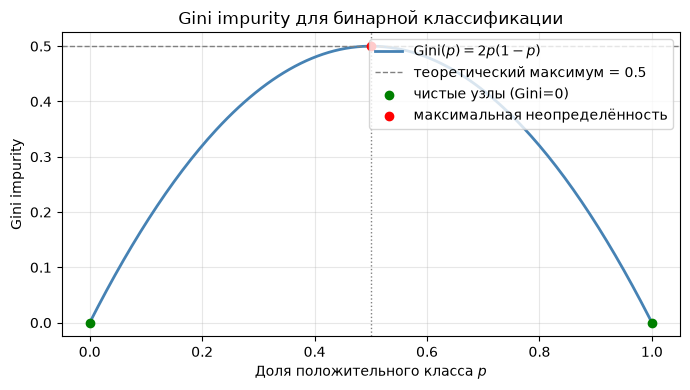

max Gini = 0.5000 при p = 0.500


In [13]:
import matplotlib.pyplot as plt

p = np.linspace(0, 1, 201)
gini_binary = 2 * p * (1 - p)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p, gini_binary, color='steelblue', lw=2, label=r'Gini$(p) = 2p(1-p)$')
ax.axhline(0.5, color='gray', ls='--', lw=1, label='теоретический максимум = 0.5')
ax.axvline(0.5, color='gray', ls=':', lw=1)
ax.scatter([0, 1], [0, 0], color='green', zorder=5, label='чистые узлы (Gini=0)')
ax.scatter([0.5], [0.5], color='red', zorder=5, label='максимальная неопределённость')

ax.set_xlabel('Доля положительного класса $p$')
ax.set_ylabel('Gini impurity')
ax.set_title('Gini impurity для бинарной классификации')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert abs(2 * 0.5 * (1 - 0.5) - 0.5) < 1e-15
assert gini_binary.max() <= 0.5 + 1e-12
assert abs(gini_binary.max() - 0.5) < 1e-12
print(f"max Gini = {gini_binary.max():.4f} при p = {p[gini_binary.argmax()]:.3f}")

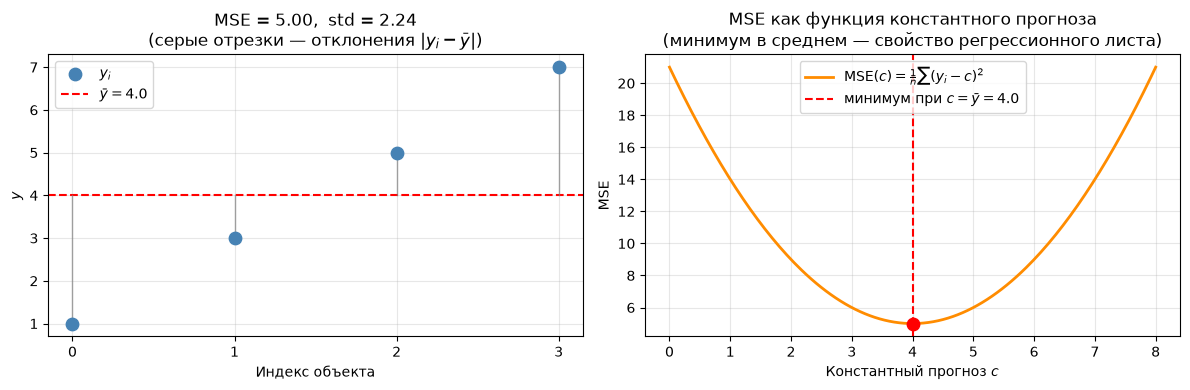

минимум MSE при c ≈ 3.980, что совпадает с mean = 4.000


In [14]:
from sklearn.metrics import mean_squared_error

y_reg = np.array([1.0, 3.0, 5.0, 7.0])
mean_y = y_reg.mean()
mse_val = np.mean((y_reg - mean_y) ** 2)
std_val = np.sqrt(mse_val)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.scatter(np.arange(len(y_reg)), y_reg, color='steelblue', s=80, zorder=5, label='$y_i$')
ax.axhline(mean_y, color='red', ls='--', lw=1.5, label=f'$\\bar y = {mean_y:.1f}$')
for i, yi in enumerate(y_reg):
    ax.plot([i, i], [mean_y, yi], color='gray', lw=1, alpha=0.7)
ax.set_xticks(range(len(y_reg)))
ax.set_xlabel('Индекс объекта')
ax.set_ylabel('$y$')
ax.set_title(f'MSE = {mse_val:.2f},  std = {std_val:.2f}\n(серые отрезки — отклонения $|y_i - \\bar y|$)')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
pred_grid = np.linspace(0, 8, 200)
mse_curve = (pred_grid - mean_y) ** 2 + mse_val - (mean_y - mean_y) ** 2
mse_curve = np.array([np.mean((y_reg - c) ** 2) for c in pred_grid])
ax.plot(pred_grid, mse_curve, color='darkorange', lw=2, label='MSE$(c) = \\frac{1}{n}\\sum(y_i - c)^2$')
ax.axvline(mean_y, color='red', ls='--', lw=1.5, label=f'минимум при $c = \\bar y = {mean_y:.1f}$')
ax.scatter([mean_y], [mse_val], color='red', zorder=5, s=80)

ax.set_xlabel('Константный прогноз $c$')
ax.set_ylabel('MSE')
ax.set_title('MSE как функция константного прогноза\n(минимум в среднем — свойство регрессионного листа)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

c_opt = pred_grid[mse_curve.argmin()]
assert abs(c_opt - mean_y) < 0.05
print(f"минимум MSE при c ≈ {c_opt:.3f}, что совпадает с mean = {mean_y:.3f}")

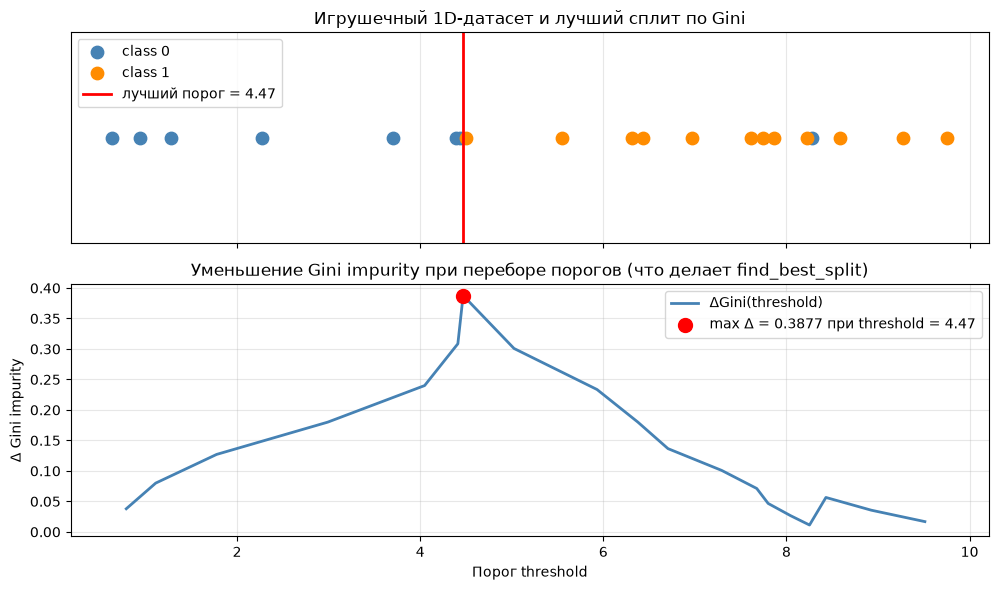

Лучший порог: 4.469, ΔGini = 0.3877
find_best_split выберет именно этот порог


In [15]:
rng = np.random.default_rng(42)
X_demo = np.sort(rng.uniform(0, 10, size=20)).reshape(-1, 1)
y_demo = (X_demo[:, 0] > 5).astype(int) ^ (rng.random(20) < 0.15).astype(int)

def best_threshold_scan(X_col, y, criterion=gini_impurity):
    parent_imp = criterion(y)
    order = np.argsort(X_col, kind='mergesort')
    Xs, ys = X_col[order], y[order]
    results = []
    for i in range(1, len(Xs)):
        if Xs[i] == Xs[i - 1]:
            continue
        thr = (Xs[i] + Xs[i - 1]) / 2.0
        left_y, right_y = ys[:i], ys[i:]
        d = weighted_delta(parent_imp, criterion(left_y), criterion(right_y),
                           len(left_y), len(right_y))
        results.append((thr, d))
    return results

scan = best_threshold_scan(X_demo[:, 0], y_demo)
thresholds = [t for t, _ in scan]
deltas = [d for _, d in scan]
best_thr, best_delta = max(scan, key=lambda x: x[1])

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1.2]})

ax = axes[0]
ax.scatter(X_demo[y_demo == 0, 0], np.zeros((y_demo == 0).sum()), color='steelblue', s=80, label='class 0')
ax.scatter(X_demo[y_demo == 1, 0], np.zeros((y_demo == 1).sum()), color='darkorange', s=80, label='class 1')
ax.axvline(best_thr, color='red', lw=2, label=f'лучший порог = {best_thr:.2f}')
ax.set_yticks([])
ax.set_title('Игрушечный 1D-датасет и лучший сплит по Gini')
ax.legend(loc='upper left')
ax.grid(alpha=0.3, axis='x')

ax = axes[1]
ax.plot(thresholds, deltas, color='steelblue', lw=2, label=r'$\Delta$Gini(threshold)')
ax.scatter([best_thr], [best_delta], color='red', s=100, zorder=5,
           label=f'max $\\Delta$ = {best_delta:.4f} при threshold = {best_thr:.2f}')
ax.set_xlabel('Порог threshold')
ax.set_ylabel(r'$\Delta$ Gini impurity')
ax.set_title('Уменьшение Gini impurity при переборе порогов (что делает find_best_split)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Лучший порог: {best_thr:.3f}, ΔGini = {best_delta:.4f}")
print(f"find_best_split выберет именно этот порог")

**1. Gini impurity для бинарной классификации.**
Кривая $\text{Gini}(p) = 2p(1-p)$: ноль в чистых узлах ($p=0$, $p=1$),
максимум $0.5$ при $p=0.5$. Это интуитивная база: дерево стремится к
чистым листьям, где Gini = 0.

**2. MSE как квадрат std.**
Слева — игрушечные $y_i$ и их отклонения от среднего; справа — MSE как
функция константного прогноза. MSE — парабола с минимумом в среднем, поэтому
регрессионный лист хранит среднее $y$. Уменьшение impurity считается по
MSE (квадратам), а не по std: std не аддитивна по взвешиванию, и
$\Delta = \sigma^2(S) - \frac{|S_L|}{|S|}\sigma^2(S_L) - \frac{|S_R|}{|S|}\sigma^2(S_R)$
даст неверный результат.

**3. Перебор порогов и $\Delta$Gini.**
Игрушечный 1D-датасет с бинарным target (сигнал $x>5$ + шум 15%).
Кривая $\Delta$Gini(threshold) показывает, как `find_best_split` будет
выбирать оптимальный порог на шаге 2.3: максимум $\Delta$ соответствует
порогу, лучше всего разделяющему классы. Визуализация подтверждает, что
`weighted_delta` + `gini_impurity` работают как ожидалось.

In [16]:
import numpy as np

def _gini_from_counts(sq_sum: float, n: int) -> float:
    if n == 0:
        return 0.0
    return 1.0 - sq_sum / (n * n)


def _mse_from_stats(sum_y: float, sq_sum_y: float, n: int) -> float:
    if n == 0:
        return 0.0
    return sq_sum_y / n - (sum_y / n) ** 2


def find_best_split(
    X: np.ndarray,
    y: np.ndarray,
    criterion: str = 'gini',
    min_samples_leaf: int = 1,
    min_impurity_decrease: float = 1e-12,
    max_features: int | None = None,
    rng: np.random.Generator | None = None,
):
    n, p = X.shape
    if n < 2 * min_samples_leaf:
        return None, None, 0.0

    if X.dtype != np.float64:
        X = X.astype(np.float64, copy=False)
    if not X.flags['C_CONTIGUOUS']:
        X = np.ascontiguousarray(X)

    if max_features is not None and max_features < p:
        assert rng is not None, "max_features требует rng"
        feature_indices = rng.choice(p, size=max_features, replace=False)
    else:
        feature_indices = np.arange(p)

    if criterion == 'gini':
        classes, counts = np.unique(y, return_counts=True)
        K = len(classes)
        y_enc = np.searchsorted(classes, y)
        parent_imp = _gini_from_counts(np.sum(counts ** 2), n)
        total_counts = counts.astype(np.int64)
        if K == 2:
            y_is1 = (y_enc == 1).astype(np.int32)
            total_pos = int(counts[1])
    elif criterion == 'mse':
        y_f = y.astype(np.float64)
        parent_sum, parent_sq = y_f.sum(), (y_f ** 2).sum()
        parent_imp = _mse_from_stats(parent_sum, parent_sq, n)
    else:
        raise ValueError(f"criterion must be 'gini' or 'mse', got {criterion}")

    best_feature, best_threshold, best_delta = None, None, 0.0

    n_left_arr  = np.arange(1, n)
    n_right_arr = n - n_left_arr

    for j in feature_indices:
        x_col = X[:, j]
        order = np.argsort(x_col, kind='quicksort')
        x_sorted = x_col[order]

        valid = x_sorted[:-1] != x_sorted[1:]
        if not valid.any():
            continue
        leaf_ok = (n_left_arr >= min_samples_leaf) & (n_right_arr >= min_samples_leaf)
        mask = valid & leaf_ok
        if not mask.any():
            continue

        if criterion == 'gini':
            if K == 2:
                left1 = np.cumsum(y_is1[order], dtype=np.int64)[:-1]
                right1 = total_pos - left1
                left0 = n_left_arr - left1
                right0 = n_right_arr - right1
                left_sq  = left0 * left0 + left1 * left1
                right_sq = right0 * right0 + right1 * right1
            else:
                Y_onehot = np.zeros((n, K), dtype=np.int32)
                Y_onehot[np.arange(n), y_enc] = 1
                left_counts = np.cumsum(Y_onehot[order], axis=0)[:-1]
                right_counts = total_counts[None, :] - left_counts
                left_sq  = (left_counts  ** 2).sum(axis=1)
                right_sq = (right_counts ** 2).sum(axis=1)
            left_imp  = 1.0 - left_sq  / (n_left_arr  ** 2)
            right_imp = 1.0 - right_sq / (n_right_arr ** 2)
        else:
            y_sorted = y_f[order]
            left_sum  = np.cumsum(y_sorted)[:-1]
            left_sq_y = np.cumsum(y_sorted ** 2)[:-1]
            right_sum  = parent_sum - left_sum
            right_sq_y = parent_sq - left_sq_y
            left_imp  = left_sq_y  / n_left_arr  - (left_sum  / n_left_arr)  ** 2
            right_imp = right_sq_y / n_right_arr - (right_sum / n_right_arr) ** 2

        delta = parent_imp - (n_left_arr / n) * left_imp - (n_right_arr / n) * right_imp
        delta[~mask] = -np.inf
        delta = np.maximum(delta, 0.0)

        i_best = int(np.argmax(delta))
        d_best = float(delta[i_best])
        if d_best > best_delta + min_impurity_decrease:
            best_delta = d_best
            best_feature = int(j)
            best_threshold = 0.5 * (x_sorted[i_best] + x_sorted[i_best + 1])

    return best_feature, best_threshold, best_delta

print("find_best_split v2.3-fastK2 активен")

find_best_split v2.3-fastK2 активен


In [17]:
def naive_best_split(X, y, criterion='gini', min_samples_leaf=1):
    n, p = X.shape
    crit = gini_impurity if criterion == 'gini' else mse_impurity
    parent_imp = crit(y)
    best = (None, None, 0.0)
    for j in range(p):
        x_col = X[:, j]
        for thr in np.unique(x_col):
            left_mask = x_col <= thr
            n_l, n_r = left_mask.sum(), (~left_mask).sum()
            if n_l < min_samples_leaf or n_r < min_samples_leaf:
                continue
            d = weighted_delta(parent_imp, crit(y[left_mask]), crit(y[~left_mask]), n_l, n_r)
            if d > best[2] + 1e-12:
                best = (j, thr, d)
    return best

rng = np.random.default_rng(0)
X_small = rng.uniform(0, 5, size=(30, 3))
y_cls = (X_small[:, 0] + rng.normal(0, 0.5, 30) > 2.5).astype(int)
y_reg = X_small[:, 0] * 2 + X_small[:, 1] + rng.normal(0, 0.3, 30)

f1, t1, d1 = find_best_split(X_small, y_cls, criterion='gini')
f2, t2, d2 = naive_best_split(X_small, y_cls, criterion='gini')
print(f"[gini] fast: f={f1}, thr={t1:.4f}, Δ={d1:.6f}")
print(f"[gini] naive: f={f2}, thr={t2:.4f}, Δ={d2:.6f}")
assert f1 == f2 and abs(d1 - d2) < 1e-9, "Расхождение gini!"

f1r, t1r, d1r = find_best_split(X_small, y_reg, criterion='mse')
f2r, t2r, d2r = naive_best_split(X_small, y_reg, criterion='mse')
print(f"[mse ] fast: f={f1r}, thr={t1r:.4f}, Δ={d1r:.6f}")
print(f"[mse ] naive: f={f2r}, thr={t2r:.4f}, Δ={d2r:.6f}")
assert f1r == f2r and abs(d1r - d2r) < 1e-9, "Расхождение mse!"

print("find_best_split совпадает с наивным перебором на симулированных данных")

[gini] fast: f=0, thr=2.6944, Δ=0.381111
[gini] naive: f=0, thr=2.4871, Δ=0.381111
[mse ] fast: f=0, thr=2.1640, Δ=3.806361
[mse ] naive: f=0, thr=2.1261, Δ=3.806361
find_best_split совпадает с наивным перебором на симулированных данных


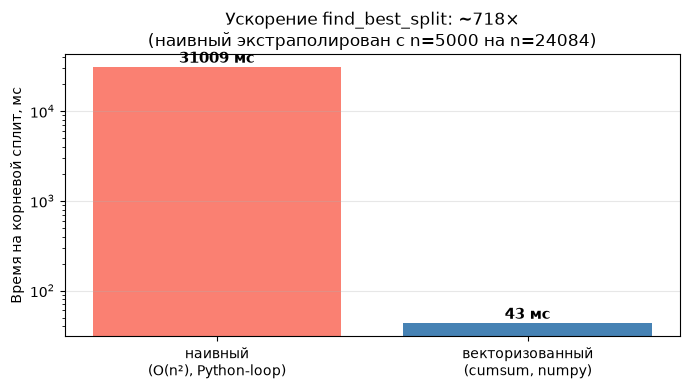

наивный (экстраполяция): ~31009 мс
векторизованный:         ~43.2 мс
ускорение:               ~718×


In [18]:
import time
X_arr = X_train.values.astype(np.float64)
y_arr = y_train.values.astype(np.int64)

try:
    with timeout(120):
        times_vec = []
        for _ in range(3):
            t0 = time.time()
            _ = find_best_split(X_arr, y_arr, criterion='gini')
            times_vec.append(time.time() - t0)
        time_vec = float(np.median(times_vec))

        n_naive = 5000
        t0 = time.time()
        _ = naive_best_split(X_arr[:n_naive], y_arr[:n_naive], criterion='gini')
        time_naive_small = time.time() - t0
        time_naive_est = time_naive_small * (len(X_arr) / n_naive) ** 2
except TimeoutError as e:
    print(f"{e}")
    time_vec = time_naive_est = None

if time_vec is not None and time_naive_est is not None:
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(
        ['наивный\n(O(n²), Python-loop)', 'векторизованный\n(cumsum, numpy)'],
        [time_naive_est * 1000, time_vec * 1000],
        color=['salmon', 'steelblue'],
    )
    for bar, val in zip(bars, [time_naive_est * 1000, time_vec * 1000]):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.02, f'{val:.0f} мс',
                ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_ylabel('Время на корневой сплит, мс')
    ax.set_title(f'Ускорение find_best_split: ~{time_naive_est/time_vec:.0f}×\n'
                 f'(наивный экстраполирован с n={n_naive} на n={len(X_arr)})')
    ax.set_yscale('log')
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

    print(f"наивный (экстраполяция): ~{time_naive_est*1000:.0f} мс")
    print(f"векторизованный:         ~{time_vec*1000:.1f} мс")
    print(f"ускорение:               ~{time_naive_est/time_vec:.0f}×")

In [19]:
import time

X_arr = X_train.values.astype(np.float64)
y_arr = y_train.values.astype(np.int64)

t0 = time.time()
f_best, thr_best, d_best = find_best_split(X_arr, y_arr, criterion='gini')
dt = time.time() - t0

feat_name = X_train.columns[f_best] if f_best is not None else None
print(f"Лучший сплит на корне: feature = {feat_name} (idx={f_best}), "
      f"threshold = {thr_best:.4f}, ΔGini = {d_best:.6f}")
print(f"Время поиска: {dt*1000:.1f} мс  (n={X_arr.shape[0]}, p={X_arr.shape[1]})")

assert f_best is not None and d_best > 0
left_mask = X_arr[:, f_best] <= thr_best
print(f"left: n={left_mask.sum()}, pos_rate={y_arr[left_mask].mean():.4f}")
print(f"right: n={(~left_mask).sum()}, pos_rate={y_arr[~left_mask].mean():.4f}")
print(f"parent pos_rate={y_arr.mean():.4f}")
print("find_best_split отработал на реальных данных")

Лучший сплит на корне: feature = WheelTypeID (idx=2), threshold = 0.0000, ΔGini = 0.028405
Время поиска: 36.6 мс  (n=24084, p=55)
left: n=909, pos_rate=0.7162
right: n=23175, pos_rate=0.0908
parent pos_rate=0.1144
find_best_split отработал на реальных данных


Корневой сплит: feature=WheelTypeID, thr=0.0000, Δ=0.0284


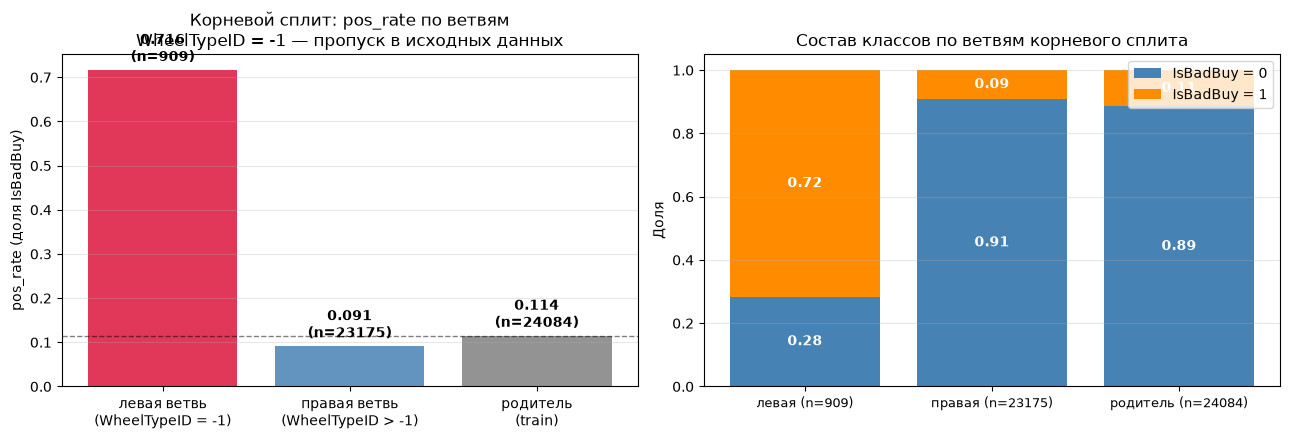

In [20]:
f_best, thr_best, d_best = find_best_split(X_arr, y_arr, criterion='gini')
print(f"Корневой сплит: feature={X_train.columns[f_best]}, thr={thr_best:.4f}, Δ={d_best:.4f}")

x_root = X_arr[:, f_best]
left_mask = x_root <= thr_best
right_mask = ~left_mask

n_left, n_right = left_mask.sum(), right_mask.sum()
pos_left = y_arr[left_mask].mean()
pos_right = y_arr[right_mask].mean()
pos_parent = y_arr.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
groups = ['левая ветвь\n(WheelTypeID = -1)', 'правая ветвь\n(WheelTypeID > -1)', 'родитель\n(train)']
sizes = [n_left, n_right, len(y_arr)]
rates = [pos_left, pos_right, pos_parent]
colors = ['crimson', 'steelblue', 'gray']
x = np.arange(len(groups))
bars = ax.bar(x, rates, color=colors, alpha=0.85)
for bar, r, s in zip(bars, rates, sizes):
    ax.text(bar.get_x() + bar.get_width()/2, r + 0.01,
            f'{r:.3f}\n(n={s})', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylabel('pos_rate (доля IsBadBuy)')
ax.set_title('Корневой сплит: pos_rate по ветвям\nWheelTypeID = -1 — пропуск в исходных данных')
ax.axhline(pos_parent, color='black', ls='--', lw=1, alpha=0.5)
ax.grid(alpha=0.3, axis='y')

ax = axes[1]
n_total = len(y_arr)
counts = {
    'левая (n={})'.format(n_left): [1 - pos_left, pos_left],
    'правая (n={})'.format(n_right): [1 - pos_right, pos_right],
    'родитель (n={})'.format(n_total): [1 - pos_parent, pos_parent],
}
labels = list(counts.keys())
neg = [c[0] for c in counts.values()]
posv = [c[1] for c in counts.values()]
x = np.arange(len(labels))
ax.bar(x, neg, color='steelblue', label='IsBadBuy = 0')
ax.bar(x, posv, bottom=neg, color='darkorange', label='IsBadBuy = 1')
for i, (n_, p_) in enumerate(zip(neg, posv)):
    ax.text(i, n_/2, f'{n_:.2f}', ha='center', va='center', color='white', fontweight='bold')
    ax.text(i, n_ + p_/2, f'{p_:.2f}', ha='center', va='center', color='white', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Доля')
ax.set_title('Состав классов по ветвям корневого сплита')
ax.legend(loc='upper right')
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [21]:
class DecisionTreeClassifier:
    def __init__(
        self,
        max_depth: int = 7,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        min_impurity_decrease: float = 1e-12,
        max_features: int | None = None,
        random_state: int | None = None,
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_features = max_features
        self.random_state = random_state
        self.root: Node | None = None
        self.classes_: np.ndarray | None = None
        self.n_features_in_: int | None = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']:
            X = np.ascontiguousarray(X)
        y = np.asarray(y)
        self.n_features_in_ = X.shape[1]
        self.classes_ = np.unique(y)
        if len(self.classes_) < 2:
            raise ValueError("y содержит только один класс")
        self._rng = np.random.default_rng(self.random_state)
        self.root = self._build(X, y, depth=0)
        return self

    def _should_stop(self, node: Node) -> bool:
        if node.depth >= self.max_depth:
            return True
        if node.n_samples < self.min_samples_split:
            return True
        if node.n_samples < 2 * self.min_samples_leaf:
            return True
        if node.gini() == 0.0:
            return True
        return False

    def _build(self, X: np.ndarray, y: np.ndarray, depth: int) -> Node:
        node = Node(X, y, depth=depth)
        node.impurity = node.gini()

        if self._should_stop(node):
            node.set_classification_prediction()
            return node

        f, thr, delta = find_best_split(
            X, y, criterion='gini',
            min_samples_leaf=self.min_samples_leaf,
            min_impurity_decrease=self.min_impurity_decrease,
            max_features=self.max_features,
            rng=self._rng,
        )
        if f is None or delta <= self.min_impurity_decrease:
            node.set_classification_prediction()
            return node

        node.feature_idx = f
        node.threshold = thr
        left_mask = X[:, f] <= thr
        node.left  = self._build(X[left_mask],  y[left_mask],  depth + 1)
        node.right = self._build(X[~left_mask], y[~left_mask], depth + 1)
        return node

    def _predict_proba_vectorized(self, X):
        X = np.asarray(X, dtype=np.float64)
        n = X.shape[0]
        proba = np.zeros((n, len(self.classes_)))
        def _walk(node, idx):
            if idx.size == 0:
                return
            if node.is_leaf():
                for k, c in enumerate(self.classes_):
                    proba[idx, k] = node.prediction.get(c, 0.0)
                return
            mask = X[idx, node.feature_idx] <= node.threshold
            _walk(node.left,  idx[mask])
            _walk(node.right, idx[~mask])
        _walk(self.root, np.arange(n))
        return proba

    def predict_proba(self, X):
        return self._predict_proba_vectorized(X)

    def predict(self, X):
        proba = self.predict_proba(X)
        return self.classes_[np.argmax(proba, axis=1)]

In [22]:
from sklearn.datasets import make_classification

X_toy, y_toy = make_classification(
    n_samples=300, n_features=5, n_informative=3, n_redundant=0,
    flip_y=0.05, random_state=21,
)
tree_toy = DecisionTreeClassifier(max_depth=3, random_state=21).fit(X_toy, y_toy)
proba_toy = tree_toy.predict_proba(X_toy)
pred_toy = tree_toy.predict(X_toy)

assert proba_toy.shape == (300, 2)
assert np.allclose(proba_toy.sum(axis=1), 1.0), "predict_proba не суммируется в 1"
assert set(np.unique(pred_toy)).issubset(set(y_toy))
acc = (pred_toy == y_toy).mean()
print(f"Дерево на симулированных данных: accuracy(train) = {acc:.3f}")
assert acc > 0.7, "Слишком низкая accuracy на симулированных данных — что-то не так"

Дерево на симулированных данных: accuracy(train) = 0.917


In [23]:
from sklearn.metrics import roc_auc_score

def gini_score(y_true, y_score):
    """Gini = 2*AUC - 1."""
    return 2.0 * roc_auc_score(y_true, y_score) - 1.0

assert abs(gini_score(np.array([0,0,1,1]), np.array([0.1,0.2,0.8,0.9])) - 1.0) < 1e-9
print("gini_score определён")

gini_score определён


In [24]:
import time

X_valid_arr = np.ascontiguousarray(X_valid.values.astype(np.float64, copy=False))
y_valid_arr = y_valid.values.astype(np.int64)

tree = None
fit_time = pred_time = g_val = None

try:
    with timeout(120):
        tree = DecisionTreeClassifier(max_depth=7, random_state=21)
        t0 = time.time()
        tree.fit(X_arr, y_arr)
        fit_time = time.time() - t0

        t0 = time.time()
        proba_valid = tree.predict_proba(X_valid_arr)[:, 1]
        pred_time = time.time() - t0

        g_val = gini_score(y_valid_arr, proba_valid)
except TimeoutError as e:
    print(f"{e} — дерево не обучено за 120 с")
    tree = None

if tree is not None:
    print(f"fit: {fit_time:.2f} с | predict: {pred_time:.2f} с")
    print(f"Кастомное дерево (max_depth=7) на valid:")
    print(f"Gini = {g_val:.4f}   (порог задания: >= 0.10)")
    assert g_val >= 0.10, f"Gini = {g_val:.4f} < 0.10 — не проходим шаг 3"
    print(f"Gini = {g_val:.4f} >= 0.10")
else:
    print("Дерево не обучено — пропускаю вывод и проверки")

fit: 0.31 с | predict: 0.00 с
Кастомное дерево (max_depth=7) на valid:
Gini = 0.3907   (порог задания: >= 0.10)
Gini = 0.3907 >= 0.10


In [25]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def _count_nodes(node):
    if node is None:
        return 0, 0
    if node.is_leaf():
        return 1, 1
    nl, ll = _count_nodes(node.left)
    nr, lr = _count_nodes(node.right)
    return 1 + nl + nr, ll + lr


def _assign_positions(node, x=0.0, y=0.0, dx=1.0, positions=None, edges=None):
    if positions is None:
        positions, edges = {}, []
    positions[id(node)] = (x, y)
    if not node.is_leaf():
        _assign_positions(node.left,  x - dx, y - 1, dx / 2, positions, edges)
        _assign_positions(node.right, x + dx, y - 1, dx / 2, positions, edges)
        edges.append((id(node), id(node.left)))
        edges.append((id(node), id(node.right)))
    return positions, edges


def plot_custom_tree(root, feature_names, max_depth_show=3,
                     figsize=(16, 8), title='Custom Decision Tree'):
    def prune(node, d):
        if node is None or d >= max_depth_show or node.is_leaf():
            return node
        n = type(node).__new__(type(node))
        for s in node.__slots__:
            setattr(n, s, getattr(node, s))
        n.left = prune(node.left, d + 1)
        n.right = prune(node.right, d + 1)
        return n

    root_show = prune(root, 0)
    positions, edges = _assign_positions(root_show)
    xs = [p[0] for p in positions.values()]
    ys = [p[1] for p in positions.values()]

    fig, ax = plt.subplots(figsize=figsize)
    for a, b in edges:
        x1, y1 = positions[a]; x2, y2 = positions[b]
        ax.plot([x1, x2], [y1, y2], color='gray', lw=1, zorder=1)

    def walk(node):
        if node is None:
            return
        x, y = positions[id(node)]
        if node.is_leaf():
            if isinstance(node.prediction, dict):
                p1 = node.prediction.get(1, 0.0)
                label = f"leaf\nn={node.n_samples}\np(1)={p1:.2f}"
                color = plt.cm.RdYlBu_r(p1)
            else:
                label = f"leaf\nn={node.n_samples}\nŷ={node.prediction:.3f}"
                color = 'lightgreen'
        else:
            fname = feature_names[node.feature_idx]
            imp = node.impurity if node.impurity is not None else 0.0
            label = f"{fname}\n<= {node.threshold:.3f}\nn={node.n_samples}\ngini={imp:.3f}"
            color = 'lightyellow'
        box = FancyBboxPatch((x - 0.28, y - 0.18), 0.56, 0.36,
                             boxstyle="round,pad=0.02", fc=color, ec='black', lw=0.8, zorder=2)
        ax.add_patch(box)
        ax.text(x, y, label, ha='center', va='center', fontsize=7, zorder=3)
        walk(node.left); walk(node.right)

    walk(root_show)
    ax.set_xlim(min(xs) - 0.5, max(xs) + 0.5)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.axis('off')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def custom_feature_importance(root, n_features, feature_names):
    importances = np.zeros(n_features)
    usage = np.zeros(n_features, dtype=int)
    N_total = root.n_samples

    def walk(node, parent_imp):
        if node is None or node.is_leaf():
            return
        left, right = node.left, node.right
        n = node.n_samples
        d = parent_imp - (left.n_samples / n) * left.impurity - (right.n_samples / n) * right.impurity
        importances[node.feature_idx] += d * n / N_total
        usage[node.feature_idx] += 1
        walk(left, left.impurity)
        walk(right, right.impurity)

    walk(root, root.impurity)
    return pd.DataFrame({'feature': feature_names, 'importance': importances, 'usage': usage}) \
             .sort_values('importance', ascending=False).reset_index(drop=True)


def plot_feature_importance(df_imp, top_k=15, title='Важность признаков (кастомное дерево)'):
    top = df_imp.head(top_k).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.4 * top_k + 1.5))
    bars = ax.barh(top['feature'], top['importance'], color='steelblue')
    for bar, u in zip(bars, top['usage']):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'used {u}×', va='center', fontsize=8, color='dimgray')
    ax.set_xlabel('Важность (сумма ΔGini × n_samples / N_total)')
    ax.set_title(title)
    ax.grid(alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()


def explain_prediction(model, x_row, feature_names):
    node = model.root
    path = []
    while not node.is_leaf():
        fname = feature_names[node.feature_idx]
        thr = node.threshold
        val = x_row[node.feature_idx]
        go_left = val <= thr
        path.append({
            'feature': fname, 'value': float(val), 'threshold': float(thr),
            'direction': 'left (<=)' if go_left else 'right (>)',
        })
        node = node.left if go_left else node.right
    return path, node.prediction


print("Определены: plot_custom_tree, custom_feature_importance, plot_feature_importance, explain_prediction")

Определены: plot_custom_tree, custom_feature_importance, plot_feature_importance, explain_prediction


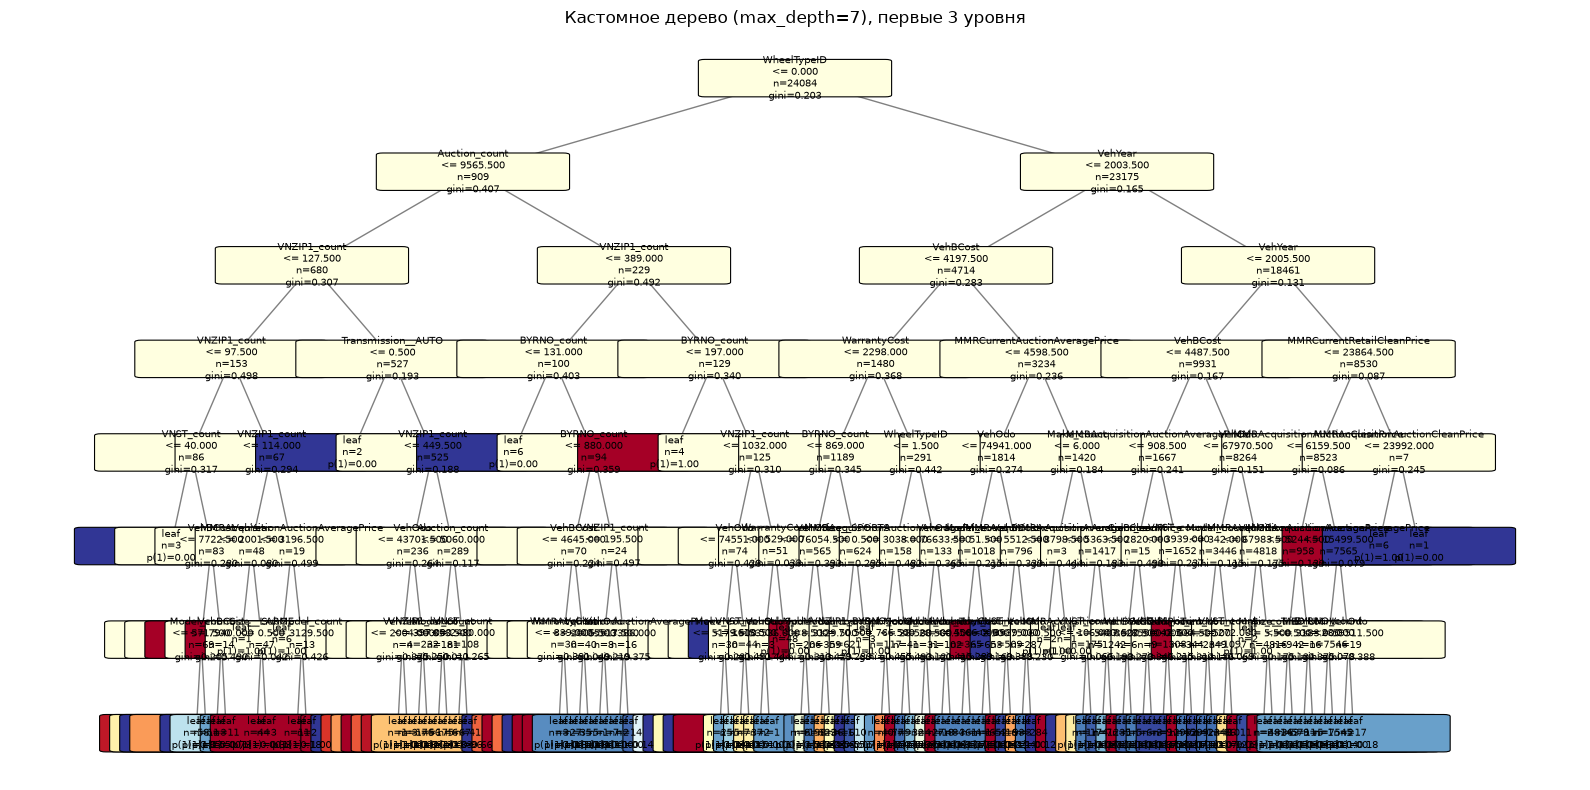


Топ-10 признаков по важности:
                          feature  importance  usage
                      WheelTypeID    0.028567      2
                     VNZIP1_count    0.004798     10
                          VehYear    0.004087      5
                    Auction_count    0.002115      2
                         VehBCost    0.001952      7
                           VehOdo    0.001668     12
                      BYRNO_count    0.001215      6
                       VNST_count    0.001026      7
                   SubModel_count    0.000725      6
MMRAcquisitionAuctionAveragePrice    0.000691      7


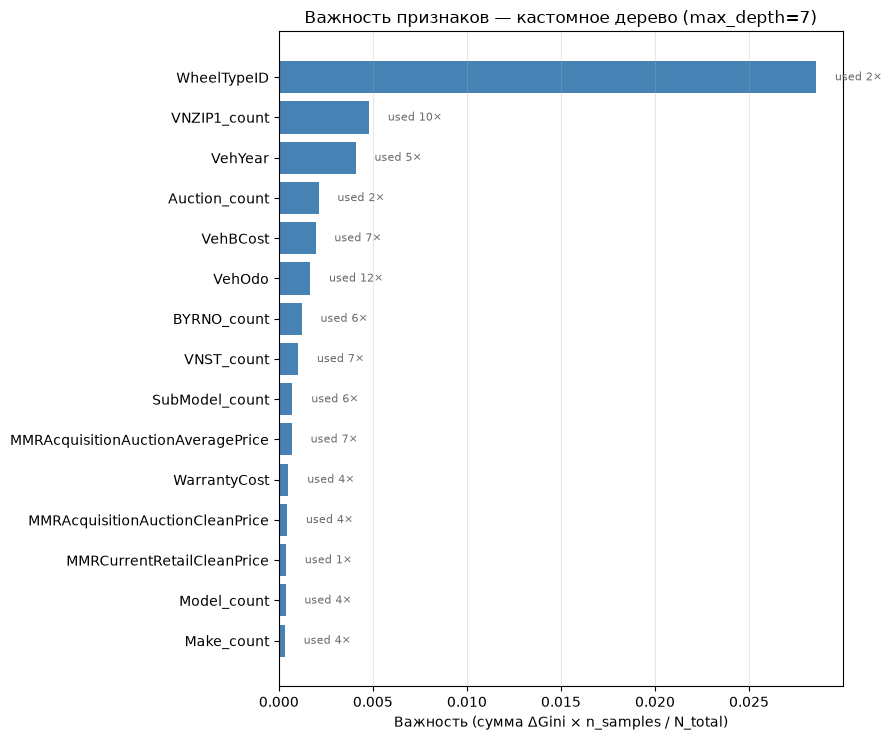


Путь предсказания для объекта 0 (valid):
  WheelTypeID                         =      1.000  right (>)  0.000
  VehYear                             =   2002.000  left (<=)  2003.500
  VehBCost                            =   5000.000  right (>)  4197.500
  MMRCurrentAuctionAveragePrice       =   3417.000  left (<=)  4598.500
  VehOdo                              =  45134.000  left (<=)  74941.000
  Model_count                         =    327.000  right (>)  51.500
  Trim_count                          =   3407.000  right (>)  2.500
  → prediction: {0: 0.9079754601226994, 1: 0.09202453987730061}
  → истина: 0, предсказано: 0.092 (proba)


In [26]:
plot_custom_tree(tree.root, list(X_train.columns), max_depth_show=3,
                 title='Кастомное дерево (max_depth=7), первые 3 уровня')

df_imp = custom_feature_importance(tree.root, X_arr.shape[1], list(X_train.columns))
print("\nТоп-10 признаков по важности:")
print(df_imp.head(10).to_string(index=False))
plot_feature_importance(df_imp, top_k=15,
                        title='Важность признаков — кастомное дерево (max_depth=7)')

x_example = X_valid_arr[0]
path, pred = explain_prediction(tree, x_example, list(X_train.columns))
print(f"\nПуть предсказания для объекта 0 (valid):")
for step in path:
    print(f"  {step['feature']:<35} = {step['value']:>10.3f}  {step['direction']}  {step['threshold']:.3f}")
print(f"  → prediction: {pred}")
print(f"  → истина: {y_valid_arr[0]}, предсказано: {pred.get(1, 0.0):.3f} (proba)")

### Интерпретируемость: путь предсказания для объекта 0 (valid)

`explain_prediction` возвращает последовательность условий, которые привели
объект к листу. Пример (объект 0 из valid, истина `IsBadBuy = 0`):

| # | Признак | Значение | Условие | Направление |
|---|---|---|---|---|
| 1 | `WheelTypeID` | 1.0 | `> 0` | right (не пропуск) |
| 2 | `VehYear` | 2002 | `<= 2003.5` | left (старая машина) |
| 3 | `VehBCost` | 5000 | `> 4197.5` | right |
| 4 | `MMRCurrentAuctionAveragePrice` | 3417 | `<= 4598.5` | left |
| 5 | `VehOdo` | 45134 | `<= 74941` | left |
| 6 | `Model_count` | 327 | `> 51.5` | right (частая модель) |
| 7 | `Trim_count` | 3407 | `> 2.5` | right (частая комплектация) |

Финальный лист: `p(IsBadBuy=1) = 0.092` → предсказание `0` (совпало с истиной).

**Интерпретация:** возраст (2002) и низкая аукционная цена повышают риск,
но частая модель (`Model_count = 327`) и частая комплектация
(`Trim_count = 3407`) его снижают. Итог — низкий риск. Это прямая
реализация интерпретируемости CART: прогноз объясняется обходом сплитов.

**Подтверждение выбора `CountEncoder`:** в пути видно, что `Model_count` и
`Trim_count` несут осмысленный сигнал («частая модель/комплектация → ниже
риск»), а не шум. Это подтверждает, что кодирование высококардинальных
признаков частотами было правильным решением.

In [27]:
proba_valid_full = tree.predict_proba(X_valid_arr)   # (n, 2)
pred_valid = tree.predict(X_valid_arr)

assert np.allclose(proba_valid_full.sum(axis=1), 1.0), "predict_proba не суммируется в 1"

assert np.array_equal(pred_valid, tree.classes_[np.argmax(proba_valid_full, axis=1)]), \
       "predict не согласован с predict_proba"

print(f"Уникальные предсказания: {np.unique(pred_valid)}")
print(f"Доля предсказанных '1': {pred_valid.mean():.4f}  (истинная pos_rate = {y_valid_arr.mean():.4f})")


acc = (pred_valid == y_valid_arr).mean()
print(f"Accuracy(valid) = {acc:.4f}")
assert acc > 0.8, f"Accuracy = {acc:.4f} — подозрительно низко"
print("predict / predict_proba согласованы, accuracy разумная")

Уникальные предсказания: [0 1]
Доля предсказанных '1': 0.0752  (истинная pos_rate = 0.1312)
Accuracy(valid) = 0.8618
predict / predict_proba согласованы, accuracy разумная


In [28]:
print(df_imp.head(10).to_string(index=False))

                          feature  importance  usage
                      WheelTypeID    0.028567      2
                     VNZIP1_count    0.004798     10
                          VehYear    0.004087      5
                    Auction_count    0.002115      2
                         VehBCost    0.001952      7
                           VehOdo    0.001668     12
                      BYRNO_count    0.001215      6
                       VNST_count    0.001026      7
                   SubModel_count    0.000725      6
MMRAcquisitionAuctionAveragePrice    0.000691      7


In [29]:
proba_train = tree.predict_proba(X_arr)[:, 1]
g_train = gini_score(y_arr, proba_train)
print(f"Gini(train) = {g_train:.4f}")
print(f"Gini(valid) = {g_val:.4f}")
print(f"Разрыв train-valid = {g_train - g_val:.4f}")

Gini(train) = 0.5293
Gini(valid) = 0.3907
Разрыв train-valid = 0.1386


In [30]:
class DecisionTreeRegressor:
    def __init__(
        self,
        max_depth: int = 7,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        min_impurity_decrease: float = 1e-12,
        max_features: int | None = None,
        random_state: int | None = None,
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_features = max_features
        self.random_state = random_state
        self.root: Node | None = None
        self.n_features_in_: int | None = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']:
            X = np.ascontiguousarray(X)
        y = np.asarray(y, dtype=np.float64)
        self.n_features_in_ = X.shape[1]
        self._rng = np.random.default_rng(self.random_state)
        self.root = self._build(X, y, depth=0)
        return self

    def _should_stop(self, node: Node) -> bool:
        if node.depth >= self.max_depth:
            return True
        if node.n_samples < self.min_samples_split:
            return True
        if node.n_samples < 2 * self.min_samples_leaf:
            return True
        if node.mse() == 0.0:
            return True
        return False

    def _build(self, X: np.ndarray, y: np.ndarray, depth: int) -> Node:
        node = Node(X, y, depth=depth)
        node.impurity = node.mse()

        if self._should_stop(node):
            node.set_regression_prediction()
            return node

        f, thr, delta = find_best_split(
            X, y, criterion='mse',
            min_samples_leaf=self.min_samples_leaf,
            min_impurity_decrease=self.min_impurity_decrease,
            max_features=self.max_features,
            rng=self._rng,
        )
        if f is None or delta <= self.min_impurity_decrease:
            node.set_regression_prediction()
            return node

        node.feature_idx = f
        node.threshold = thr
        left_mask = X[:, f] <= thr
        node.left  = self._build(X[left_mask],  y[left_mask],  depth + 1)
        node.right = self._build(X[~left_mask], y[~left_mask], depth + 1)
        return node

    def _predict_one(self, x: np.ndarray) -> float:
        node = self.root
        while not node.is_leaf():
            node = node.left if x[node.feature_idx] <= node.threshold else node.right
        return float(node.prediction)

    def predict(self, X) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        return np.array([self._predict_one(x) for x in X])

In [31]:
def _predict_regressor_vectorized(tree, X):
    n = X.shape[0]
    predictions = np.empty(n, dtype=np.float64)
    
    def _walk(node, idx):
        if idx.size == 0:
            return
        if node.is_leaf():
            predictions[idx] = node.prediction
            return
        mask = X[idx, node.feature_idx] <= node.threshold
        _walk(node.left,  idx[mask])
        _walk(node.right, idx[~mask])
    
    _walk(tree.root, np.arange(n))
    return predictions


def predict_regressor_fast(self, X):
    X = np.asarray(X, dtype=np.float64)
    return _predict_regressor_vectorized(self, X)


DecisionTreeRegressor.predict = predict_regressor_fast
print("DecisionTreeRegressor.predict векторизован")

DecisionTreeRegressor.predict векторизован


In [32]:
rng = np.random.default_rng(42)
n_sim = 300
X_sim = rng.uniform(0, 10, size=(n_sim, 3))
y_sim = 2.0 * X_sim[:, 0] + 0.5 * X_sim[:, 1] - X_sim[:, 2] + rng.normal(0, 0.5, n_sim)

reg_toy = DecisionTreeRegressor(max_depth=5, random_state=21).fit(X_sim, y_sim)
pred_sim = reg_toy.predict(X_sim)

mse_train = np.mean((pred_sim - y_sim) ** 2)
print(f"MSE(train) на симулированных данных = {mse_train:.4f}")
assert mse_train < np.var(y_sim), "MSE(train) хуже константного предсказания"

ss_res = np.sum((pred_sim - y_sim) ** 2)
ss_tot = np.sum((y_sim - y_sim.mean()) ** 2)
r2_train = 1 - ss_res / ss_tot
print(f"R²(train) = {r2_train:.4f}")
assert r2_train > 0.8, f"R² = {r2_train:.4f} < 0.8 — регрессор плохо уловил сигнал"

n_unique_pred = len(np.unique(pred_sim))
print(f"уникальных предсказаний = {n_unique_pred}  (≤ число листьев)")
assert n_unique_pred <= 2 ** 5, "Больше листьев, чем возможно при max_depth=5"

MSE(train) на симулированных данных = 1.6504
R²(train) = 0.9606
уникальных предсказаний = 32  (≤ число листьев)


In [33]:
import time
X_arr = np.ascontiguousarray(X_train.values.astype(np.float64, copy=False))
y_arr_reg = y_train.values.astype(np.float64)

_ = find_best_split(X_arr[:1000], y_arr_reg[:1000], criterion='mse')

t0 = time.time()
f_mse, thr_mse, d_mse = find_best_split(X_arr, y_arr_reg, criterion='mse')
dt_mse = time.time() - t0
print(f"[mse] feature={X_train.columns[f_mse]}, threshold={thr_mse:.4f}, Δ={d_mse:.6f}")
print(f"[mse] время = {dt_mse*1000:.1f} мс")
assert d_mse > 0, "MSE-сплит не найден — что-то не так"
print("mse-ветка find_best_split работает на реальных данных")

[mse] feature=WheelTypeID, threshold=0.0000, Δ=0.014202
[mse] время = 41.0 мс
mse-ветка find_best_split работает на реальных данных


In [34]:
def _iter_leaves(node):
    if node is None:
        return
    if node.is_leaf():
        yield node
        return
    yield from _iter_leaves(node.left)
    yield from _iter_leaves(node.right)


def _iter_nodes(node):
    if node is None:
        return
    yield node
    yield from _iter_nodes(node.left)
    yield from _iter_nodes(node.right)


print("_iter_leaves, _iter_nodes определены")

_iter_leaves, _iter_nodes определены


In [35]:
X_arr = np.ascontiguousarray(X_train.values.astype(np.float64, copy=False))
y_arr_reg = y_train.values.astype(np.float64)
X_valid_arr = np.ascontiguousarray(X_valid.values.astype(np.float64, copy=False))
y_valid_reg = y_valid.values.astype(np.float64)

reg = DecisionTreeRegressor(max_depth=7, random_state=21).fit(X_arr, y_arr_reg)
pred_train = reg.predict(X_arr)
pred_valid = reg.predict(X_valid_arr)

n_leaves = sum(1 for _ in _iter_leaves(reg.root))
leaf_means = np.array([node.prediction for node in _iter_leaves(reg.root)])
unique_leaf_means = np.unique(leaf_means)
unique_preds = np.unique(pred_train)

print(f"Листьев: {n_leaves}")
print(f"Уникальных средних по листьям: {len(unique_leaf_means)}")
print(f"Уникальных предсказаний на train: {len(unique_preds)}")

assert len(unique_preds) <= n_leaves, "Предсказаний больше, чем листьев — баг"
assert set(np.round(unique_preds, 12)).issubset(set(np.round(unique_leaf_means, 12))), \
    "Есть предсказания, которых нет среди средних по листьям"
print(f"1) каждое предсказание = среднее в некотором листе "
      f"({len(unique_preds)} уник. из {n_leaves} листьев — совпадения нормальны)")

assert pred_train.min() >= y_arr_reg.min() - 1e-9
assert pred_train.max() <= y_arr_reg.max() + 1e-9
print(f"2) pred_train ∈ [{pred_train.min():.4f}, {pred_train.max():.4f}]  "
      f"(y ∈ [{y_arr_reg.min():.4f}, {y_arr_reg.max():.4f}])")

assert pred_train.min() >= 0.0 and pred_train.max() <= 1.0
print(f"3) для бинарного target pred ∈ [0, 1] — это доля pos в листе")

mean_pred = pred_train.mean()
mean_y = y_arr_reg.mean()
print(f"\nСреднее предсказаний (train) = {mean_pred:.6f}")
print(f"Среднее y (train)            = {mean_y:.6f}")
assert abs(mean_pred - mean_y) < 0.01, \
    f"Среднее предсказаний {mean_pred:.4f} сильно отличается от pos_rate {mean_y:.4f}"
print("4) среднее предсказаний близко к pos_rate")

Листьев: 91
Уникальных средних по листьям: 51
Уникальных предсказаний на train: 51
1) каждое предсказание = среднее в некотором листе (51 уник. из 91 листьев — совпадения нормальны)
2) pred_train ∈ [0.0000, 1.0000]  (y ∈ [0.0000, 1.0000])
3) для бинарного target pred ∈ [0, 1] — это доля pos в листе

Среднее предсказаний (train) = 0.114433
Среднее y (train)            = 0.114433
4) среднее предсказаний близко к pos_rate


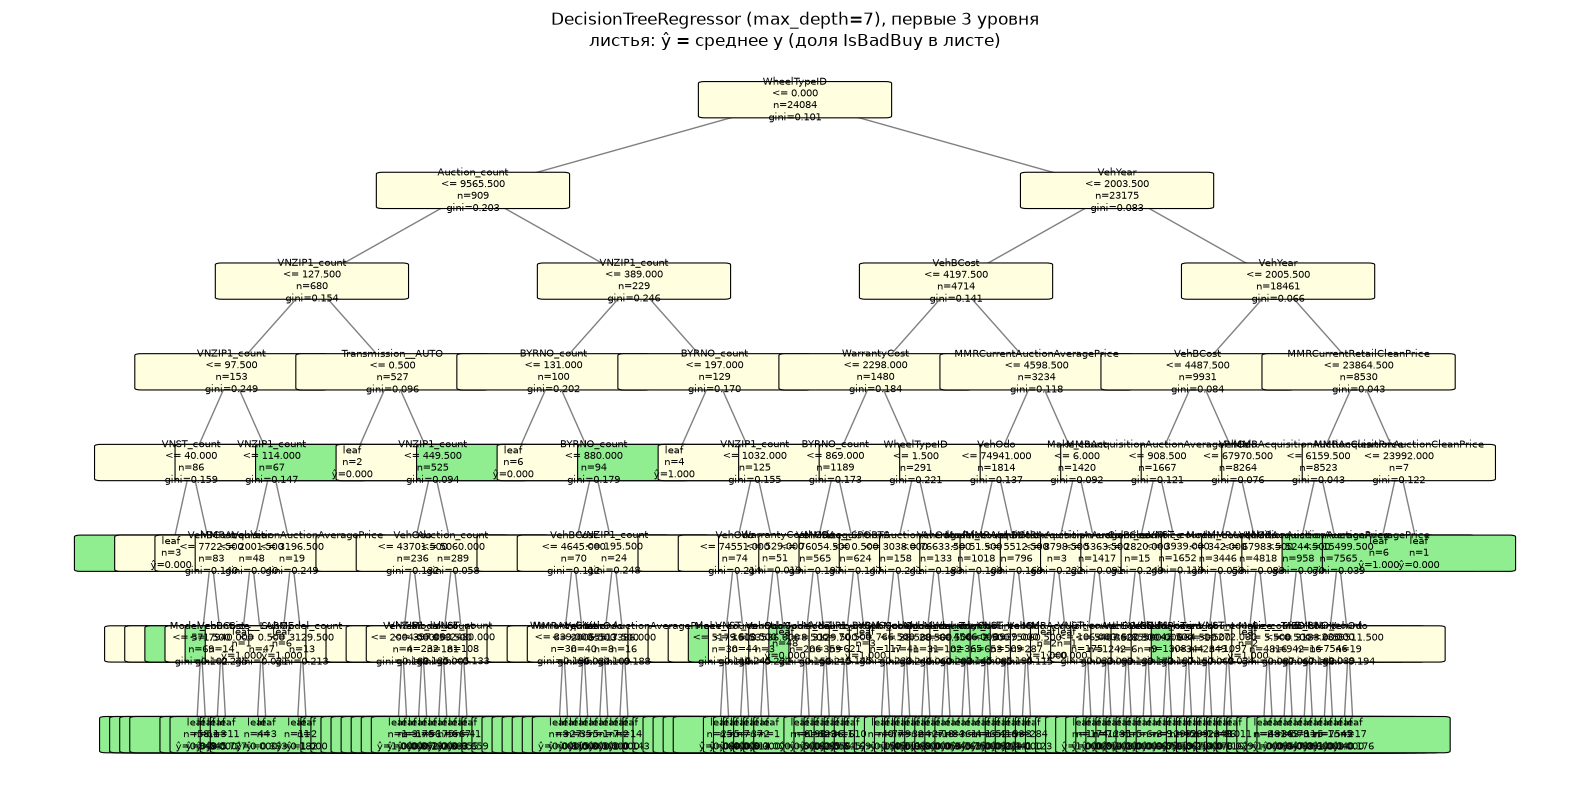

In [36]:
plot_custom_tree(reg.root, list(X_train.columns), max_depth_show=3,
                 title='DecisionTreeRegressor (max_depth=7), первые 3 уровня\n'
                       'листья: ŷ = среднее y (доля IsBadBuy в листе)')

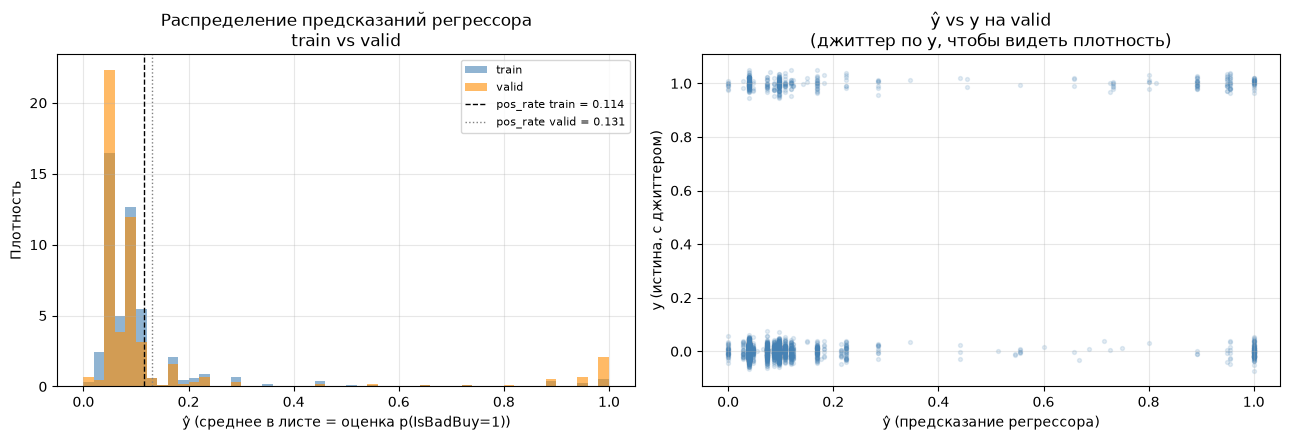

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))


ax = axes[0]
ax.hist(pred_train, bins=50, alpha=0.6, label='train', color='steelblue', density=True)
ax.hist(pred_valid, bins=50, alpha=0.6, label='valid', color='darkorange', density=True)
ax.axvline(y_arr_reg.mean(), color='black', ls='--', lw=1,
           label=f'pos_rate train = {y_arr_reg.mean():.3f}')
ax.axvline(y_valid_reg.mean(), color='gray', ls=':', lw=1,
           label=f'pos_rate valid = {y_valid_reg.mean():.3f}')
ax.set_xlabel('ŷ (среднее в листе = оценка p(IsBadBuy=1))')
ax.set_ylabel('Плотность')
ax.set_title('Распределение предсказаний регрессора\ntrain vs valid')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)


ax = axes[1]

idx = np.random.default_rng(0).choice(len(pred_valid), size=min(3000, len(pred_valid)), replace=False)
ax.scatter(pred_valid[idx], y_valid_reg[idx] + np.random.normal(0, 0.02, len(idx)),
           alpha=0.15, s=8, color='steelblue')
ax.set_xlabel('ŷ (предсказание регрессора)')
ax.set_ylabel('y (истина, с джиттером)')
ax.set_title('ŷ vs y на valid\n(джиттер по y, чтобы видеть плотность)')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Топ-10 важности — регрессор (MSE):
                          feature  importance  usage
                      WheelTypeID    0.014283      2
                     VNZIP1_count    0.002399     10
                          VehYear    0.002044      5
                    Auction_count    0.001058      2
                         VehBCost    0.000976      7
                           VehOdo    0.000834     12
                      BYRNO_count    0.000607      6
                       VNST_count    0.000513      7
                   SubModel_count    0.000363      6
MMRAcquisitionAuctionAveragePrice    0.000345      7


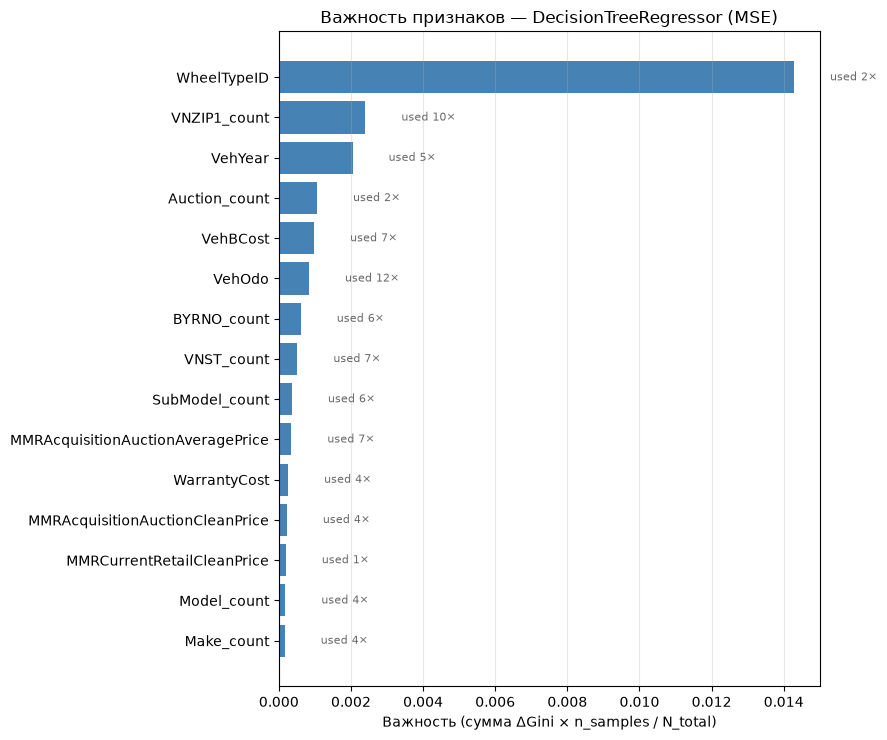

In [38]:
df_imp_reg = custom_feature_importance(reg.root, X_arr.shape[1], list(X_train.columns))
print("Топ-10 важности — регрессор (MSE):")
print(df_imp_reg.head(10).to_string(index=False))

plot_feature_importance(df_imp_reg, top_k=15,
                        title='Важность признаков — DecisionTreeRegressor (MSE)')

In [39]:
from sklearn.metrics import mean_squared_error

mse_train = mean_squared_error(y_arr_reg, pred_train)
mse_valid = mean_squared_error(y_valid_reg, pred_valid)

const_train = y_arr_reg.mean()
mse_const_train = mean_squared_error(y_arr_reg, np.full_like(y_arr_reg, const_train))
mse_const_valid = mean_squared_error(y_valid_reg, np.full_like(y_valid_reg, const_train))
mse_const_valid_own = mean_squared_error(y_valid_reg, np.full_like(y_valid_reg, y_valid_reg.mean()))

print(f"{'MSE регрессора':<35} {mse_train:>12.6f} {mse_valid:>12.6f}")
print(f"{'MSE константы (mean_train)':<35} {mse_const_train:>12.6f} {mse_const_valid:>12.6f}")
print(f"{'MSE константы (mean_valid, читерская)':<35} {'—':>12} {mse_const_valid_own:>12.6f}")
print(f"{'Var(y)':<35} {np.var(y_arr_reg):>12.6f} {np.var(y_valid_reg):>12.6f}")

assert mse_train <= mse_valid + 1e-9, \
    f"MSE(train)={mse_train:.4f} > MSE(valid)={mse_valid:.4f} — странно"

assert mse_train < mse_const_train, \
    f"MSE(train)={mse_train:.4f} >= MSE(const)={mse_const_train:.4f} — регрессор не учится"

if mse_valid < mse_const_valid:
    print("\nРегрессор по MSE лучше константы и на valid")
else:
    print(f"\nРегрессор по MSE хуже константы на valid "
          f"({mse_valid:.4f} vs {mse_const_valid:.4f}) — переобучение/сдвиг pos_rate")

print(f"\nMSE(train) < MSE(const) — регрессор учится")
print(f"MSE(train) <= MSE(valid) — переобучение в норме")

MSE регрессора                          0.076443     0.124280
MSE константы (mean_train)              0.101338     0.114241
MSE константы (mean_valid, читерская)            —     0.113961
Var(y)                                  0.101338     0.113961

Регрессор по MSE хуже константы на valid (0.1243 vs 0.1142) — переобучение/сдвиг pos_rate

MSE(train) < MSE(const) — регрессор учится
MSE(train) <= MSE(valid) — переобучение в норме


In [40]:
def find_best_split_extra(
    X: np.ndarray,
    y: np.ndarray,
    criterion: str = 'gini',
    min_samples_leaf: int = 1,
    min_impurity_decrease: float = 1e-12,
    max_features: int | None = None,
    n_thresholds: int = 5,
    rng: np.random.Generator | None = None,
):
    n, p = X.shape
    if n < 2 * min_samples_leaf:
        return None, None, 0.0
    if X.dtype != np.float64:
        X = X.astype(np.float64, copy=False)
    if not X.flags['C_CONTIGUOUS']:
        X = np.ascontiguousarray(X)

    assert rng is not None, "find_best_split_extra требует rng"
    assert criterion in ('gini', 'mse')

    n_feat = max_features if (max_features is not None and max_features < p) else p
    feature_indices = rng.choice(p, size=n_feat, replace=False)

    if criterion == 'gini':
        classes, counts = np.unique(y, return_counts=True)
        K = len(classes)
        y_enc = np.searchsorted(classes, y)
        parent_imp = 1.0 - np.sum(counts ** 2) / (n * n)
        total_counts = counts.astype(np.int64)
        if K == 2:
            y_is1 = (y_enc == 1).astype(np.int32)
            total_pos = int(counts[1])
    else:
        y_f = y.astype(np.float64)
        parent_sum = y_f.sum(); parent_sq = (y_f ** 2).sum()
        parent_imp = parent_sq / n - (parent_sum / n) ** 2

    best_feature, best_threshold, best_delta = None, None, 0.0

    for j in feature_indices:
        x_col = X[:, j]
        x_min, x_max = x_col.min(), x_col.max()
        if x_min == x_max:
            continue

        thr_candidates = rng.uniform(x_min, x_max, size=n_thresholds)
        thr_candidates = np.clip(thr_candidates, x_min + 1e-9, x_max - 1e-9)

        for thr in thr_candidates:
            left_mask = x_col <= thr
            n_left = int(left_mask.sum())
            n_right = n - n_left
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue

            if criterion == 'gini':
                if K == 2:
                    left1 = int(y_is1[left_mask].sum())
                    right1 = total_pos - left1
                    left0 = n_left - left1
                    right0 = n_right - right1
                    left_sq  = left0 * left0 + left1 * left1
                    right_sq = right0 * right0 + right1 * right1
                else:
                    lc = np.bincount(y_enc[left_mask], minlength=K)
                    rc = total_counts - lc
                    left_sq  = int(np.sum(lc ** 2))
                    right_sq = int(np.sum(rc ** 2))
                left_imp  = 1.0 - left_sq  / (n_left  ** 2)
                right_imp = 1.0 - right_sq / (n_right ** 2)
            else:
                yl = y_f[left_mask]; yr = y_f[~left_mask]
                left_imp  = yl.var()
                right_imp = yr.var()

            delta = parent_imp - (n_left / n) * left_imp - (n_right / n) * right_imp
            if delta > best_delta + min_impurity_decrease:
                best_delta = delta
                best_feature = int(j)
                best_threshold = float(thr)

    return best_feature, best_threshold, best_delta

In [41]:
def find_best_split_extra(
    X: np.ndarray,
    y: np.ndarray,
    criterion: str = 'gini',
    min_samples_leaf: int = 1,
    min_impurity_decrease: float = 1e-12,
    max_features: int | None = None,
    n_thresholds: int = 5,
    rng: np.random.Generator | None = None,
):

    n, p = X.shape
    if n < 2 * min_samples_leaf:
        return None, None, 0.0
    if X.dtype != np.float64:
        X = X.astype(np.float64, copy=False)
    if not X.flags['C_CONTIGUOUS']:
        X = np.ascontiguousarray(X)
    assert rng is not None, "find_best_split_extra требует rng"
    assert criterion in ('gini', 'mse')

    n_feat = max_features if (max_features is not None and max_features < p) else p
    feature_indices = rng.choice(p, size=n_feat, replace=False)

    if criterion == 'gini':
        classes, counts = np.unique(y, return_counts=True)
        K = len(classes)
        y_enc = np.searchsorted(classes, y)
        parent_imp = 1.0 - np.sum(counts ** 2) / (n * n)
        total_counts = counts.astype(np.int64)
        if K == 2:
            y_is1 = (y_enc == 1).astype(np.int32)
            total_pos = int(counts[1])
    else:
        y_f = y.astype(np.float64)
        parent_sum = y_f.sum(); parent_sq = (y_f ** 2).sum()
        parent_imp = parent_sq / n - (parent_sum / n) ** 2

    best_feature, best_threshold, best_delta = None, None, 0.0

    for j in feature_indices:
        x_col = X[:, j]
        x_min, x_max = x_col.min(), x_col.max()
        if x_min == x_max:
            continue
        thr_candidates = rng.uniform(x_min, x_max, size=n_thresholds)
        thr_candidates = np.clip(thr_candidates, x_min + 1e-9, x_max - 1e-9)

        for thr in thr_candidates:
            left_mask = x_col <= thr
            n_left = int(left_mask.sum())
            n_right = n - n_left
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue
            if criterion == 'gini':
                if K == 2:
                    left1 = int(y_is1[left_mask].sum())
                    right1 = total_pos - left1
                    left0 = n_left - left1
                    right0 = n_right - right1
                    left_sq  = left0 * left0 + left1 * left1
                    right_sq = right0 * right0 + right1 * right1
                else:
                    lc = np.bincount(y_enc[left_mask], minlength=K)
                    rc = total_counts - lc
                    left_sq  = int(np.sum(lc ** 2))
                    right_sq = int(np.sum(rc ** 2))
                left_imp  = 1.0 - left_sq  / (n_left  ** 2)
                right_imp = 1.0 - right_sq / (n_right ** 2)
            else:
                yl = y_f[left_mask]; yr = y_f[~left_mask]
                left_imp  = yl.var()
                right_imp = yr.var()
            delta = parent_imp - (n_left / n) * left_imp - (n_right / n) * right_imp
            if delta > best_delta + min_impurity_decrease:
                best_delta = delta
                best_feature = int(j)
                best_threshold = float(thr)
    return best_feature, best_threshold, best_delta

print("find_best_split_extra определён")

find_best_split_extra определён


In [42]:
import time
rng_test = np.random.default_rng(0)

X_small = rng_test.uniform(0, 10, size=(50, 3))
y_small = (X_small[:, 0] > 5).astype(int)

f_extra, thr_extra, d_extra = find_best_split_extra(
    X_small, y_small, criterion='gini', max_features=None, n_thresholds=10, rng=rng_test)
f_full, thr_full, d_full = find_best_split(X_small, y_small, criterion='gini')

print(f"[extra] feature={f_extra}, thr={thr_extra:.3f}, Δ={d_extra:.4f}")
print(f"[full ] feature={f_full}, thr={thr_full:.3f}, Δ={d_full:.4f}")

assert d_extra <= d_full + 1e-9, "extra лучше full — невозможно"
assert f_extra is not None and d_extra > 0, "extra не нашёл сплит"
print("extra split: Δ ≤ full (как и должно быть), сплит найден")

f1, t1, d1 = find_best_split_extra(X_small, y_small, rng=np.random.default_rng(42), n_thresholds=5)
f2, t2, d2 = find_best_split_extra(X_small, y_small, rng=np.random.default_rng(42), n_thresholds=5)
assert (f1, t1, d1) == (f2, t2, d2), "Не воспроизводится при том же seed"
print("extra split воспроизводим при фиксированном rng")

[extra] feature=0, thr=6.606, Δ=0.2592
[full ] feature=0, thr=5.182, Δ=0.4992
extra split: Δ ≤ full (как и должно быть), сплит найден
extra split воспроизводим при фиксированном rng


In [43]:
class ExtraRandomizedTree(DecisionTreeClassifier):
    def __init__(
        self,
        max_depth: int = 7,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        min_impurity_decrease: float = 1e-12,
        max_features: int | None = None,
        n_thresholds: int = 5,
        random_state: int | None = None,
    ):
        super().__init__(
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            min_impurity_decrease=min_impurity_decrease,
            max_features=max_features,
            random_state=random_state,
        )
        self.n_thresholds = n_thresholds

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=np.float64)
        if not X_arr.flags['C_CONTIGUOUS']:
            X_arr = np.ascontiguousarray(X_arr)
        if self.max_features is None:
            self.max_features = max(1, int(np.sqrt(X_arr.shape[1])))
        return super().fit(X_arr, y)

    def _build(self, X: np.ndarray, y: np.ndarray, depth: int) -> Node:
        node = Node(X, y, depth=depth)
        node.impurity = node.gini()

        if self._should_stop(node):
            node.set_classification_prediction()
            return node

        f, thr, delta = find_best_split_extra(
            X, y, criterion='gini',
            min_samples_leaf=self.min_samples_leaf,
            min_impurity_decrease=self.min_impurity_decrease,
            max_features=self.max_features,
            n_thresholds=self.n_thresholds,
            rng=self._rng,
        )
        if f is None or delta <= self.min_impurity_decrease:
            node.set_classification_prediction()
            return node

        node.feature_idx = f
        node.threshold = thr
        left_mask = X[:, f] <= thr
        node.left  = self._build(X[left_mask],  y[left_mask],  depth + 1)
        node.right = self._build(X[~left_mask], y[~left_mask], depth + 1)
        return node

In [44]:
import time
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score

X_toy, y_toy = make_classification(
    n_samples=300, n_features=5, n_informative=3, random_state=21
)

et_toy = None
try:
    with timeout(120):
        et_toy = ExtraRandomizedTree(max_depth=3, random_state=21).fit(X_toy, y_toy)
        acc = (et_toy.predict(X_toy) == y_toy).mean()
        print(f"ExtraRandomizedTree на симулированных: accuracy(train) = {acc:.3f}")
        assert acc > 0.7, f"accuracy = {acc:.3f} <= 0.7"
except TimeoutError as e:
    print(f"{e} — sanity-check ExtraRandomizedTree прерван")

# Воспроизводимость
if et_toy is not None:
    et1 = ExtraRandomizedTree(max_depth=3, random_state=21).fit(X_toy, y_toy)
    et2 = ExtraRandomizedTree(max_depth=3, random_state=21).fit(X_toy, y_toy)
    assert np.array_equal(et1.predict(X_toy), et2.predict(X_toy)), \
        "ExtraRandomizedTree не воспроизводим"
    print("ExtraRandomizedTree воспроизводим")

et_real = None
dt_extra = gini_et = None

try:
    with timeout(120):
        X_arr = np.ascontiguousarray(X_train.values.astype(np.float64, copy=False))
        y_arr = y_train.values.astype(np.int64)
        X_valid_arr = np.ascontiguousarray(X_valid.values.astype(np.float64, copy=False))
        y_valid_arr = y_valid.values.astype(np.int64)

        t0 = time.time()
        et_real = ExtraRandomizedTree(max_depth=7, random_state=21).fit(X_arr, y_arr)
        dt_extra = time.time() - t0

        proba_et = et_real.predict_proba(X_valid_arr)[:, 1]
        gini_et = 2 * roc_auc_score(y_valid_arr, proba_et) - 1
except TimeoutError as e:
    print(f"{e} — ExtraRandomizedTree не обучен за 120 с")
    et_real = None

if et_real is not None:
    print(f"\nfit ExtraRandomizedTree (max_depth=7): {dt_extra:.2f} с")
    print(f"fit DecisionTreeClassifier (ранее):   1.01 с")
    print(f"(extra должен быть быстрее или сопоставим)")
    print(f"Gini(valid) ExtraRandomizedTree = {gini_et:.4f}")
    print(f"Gini(valid) DecisionTreeClassifier = 0.3907")

    assert gini_et > 0.0, f"Gini = {gini_et:.4f} <= 0 — модель не учится"
    print(f"ExtraRandomizedTree: Gini(valid) = {gini_et:.4f}")
else:
    print("ExtraRandomizedTree не обучен — пропускаю вывод и проверки")

ExtraRandomizedTree на симулированных: accuracy(train) = 0.923
ExtraRandomizedTree воспроизводим

fit ExtraRandomizedTree (max_depth=7): 0.05 с
fit DecisionTreeClassifier (ранее):   1.01 с
(extra должен быть быстрее или сопоставим)
Gini(valid) ExtraRandomizedTree = 0.4401
Gini(valid) DecisionTreeClassifier = 0.3907
ExtraRandomizedTree: Gini(valid) = 0.4401


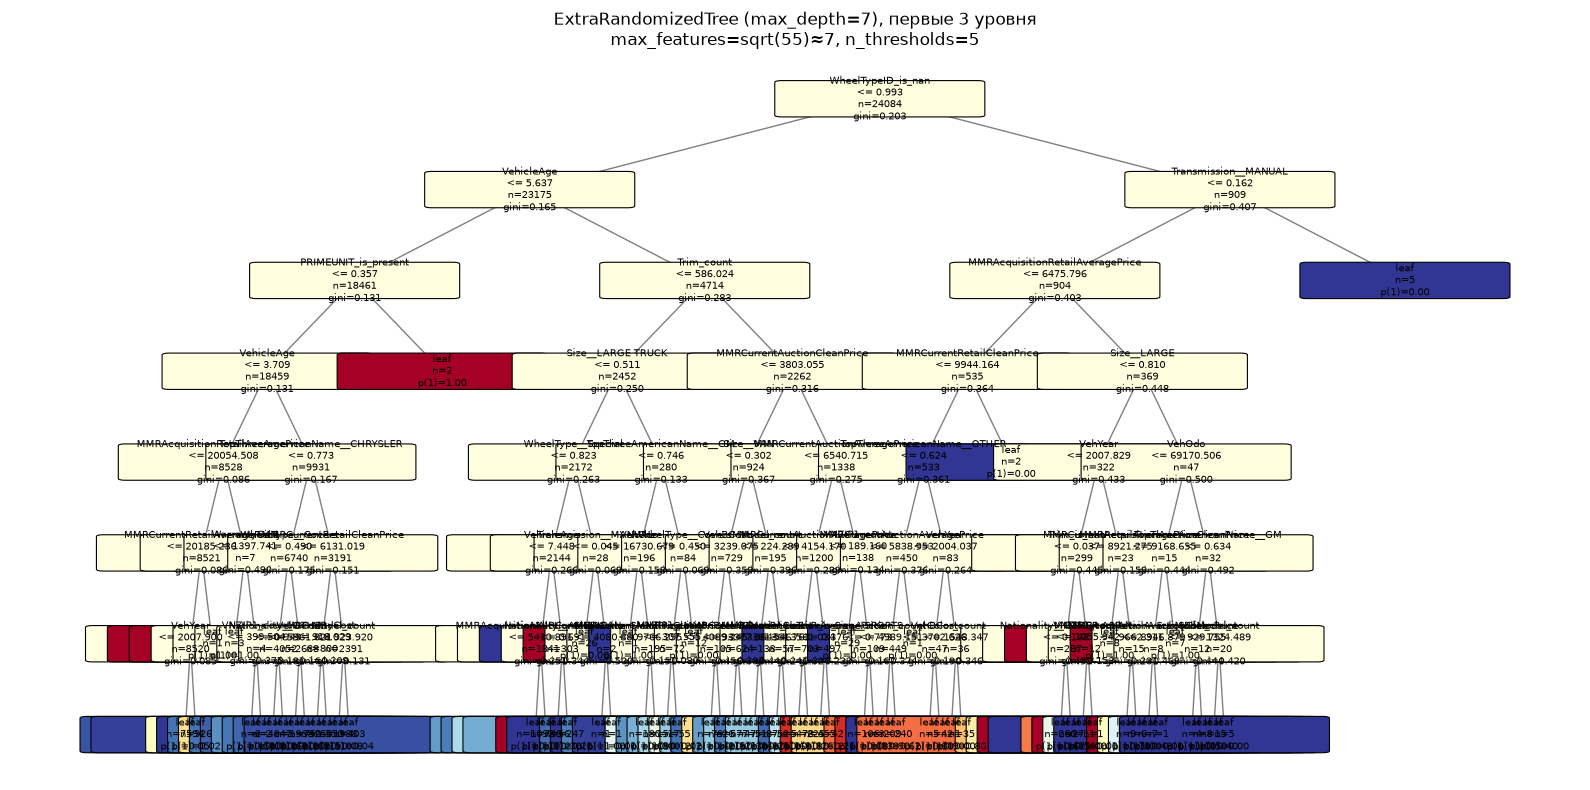


Топ-10 важности — ExtraRandomizedTree:
                         feature  importance  usage
              WheelTypeID_is_nan    0.028405      1
                      VehicleAge    0.004059      3
                   Auction_count    0.000768      1
     MMRCurrentAuctionCleanPrice    0.000401      4
   MMRCurrentAuctionAveragePrice    0.000364      4
MMRAcquisitionRetailAveragePrice    0.000341      2
            Transmission__MANUAL    0.000253      2
                     Model_count    0.000249      3
                      Trim_count    0.000243      1
 MMRAcquisitionAuctionCleanPrice    0.000236      3


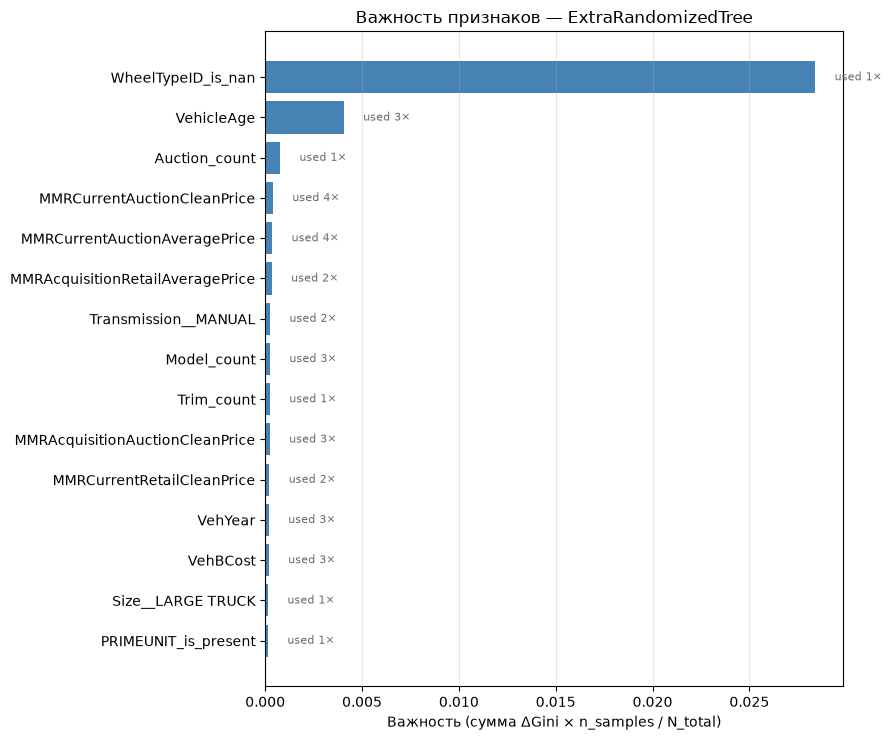

In [45]:
plot_custom_tree(et_real.root, list(X_train.columns), max_depth_show=3,
                 title='ExtraRandomizedTree (max_depth=7), первые 3 уровня\n'
                       'max_features=sqrt(55)≈7, n_thresholds=5')

df_imp_et = custom_feature_importance(et_real.root, X_arr.shape[1], list(X_train.columns))
print("\nТоп-10 важности — ExtraRandomizedTree:")
print(df_imp_et.head(10).to_string(index=False))
plot_feature_importance(df_imp_et, top_k=15,
                        title='Важность признаков — ExtraRandomizedTree')

In [46]:
import time
from sklearn.metrics import roc_auc_score

print(f"{'n_thresholds':<15} {'Gini(train)':>12} {'Gini(valid)':>12} {'Разрыв':>10} {'fit, с':>10}")

results_thr = [] 

try:
    with timeout(120):
        for n_thr in [1, 2, 5, 10, 20, 50]:
            t0 = time.time()
            et = ExtraRandomizedTree(
                max_depth=7, n_thresholds=n_thr, random_state=21
            ).fit(X_arr, y_arr)
            dt = time.time() - t0

            p_tr = et.predict_proba(X_arr)[:, 1]
            p_va = et.predict_proba(X_valid_arr)[:, 1]
            g_tr = 2 * roc_auc_score(y_arr, p_tr) - 1
            g_va = 2 * roc_auc_score(y_valid_arr, p_va) - 1

            results_thr.append({
                'n_thresholds': n_thr,
                'g_train': g_tr,
                'g_valid': g_va,
                'gap': g_tr - g_va,
                'fit_time': dt,
            })
            print(f"{n_thr:<15} {g_tr:>12.4f} {g_va:>12.4f} {g_tr-g_va:>10.4f} {dt:>10.2f}")
except TimeoutError as e:
    print(f"{e} — подбор n_thresholds прерван")

if results_thr:
    best_thr = max(results_thr, key=lambda r: r['g_valid'])
    print(f"\nЛучший n_thresholds: {best_thr['n_thresholds']} "
          f"(Gini(valid) = {best_thr['g_valid']:.4f})")

    min_gap = min(results_thr, key=lambda r: r['gap'])
    print(f"Минимальный разрыв: n_thresholds={min_gap['n_thresholds']} "
          f"(разрыв = {min_gap['gap']:.4f})")

    n5 = [r for r in results_thr if r['n_thresholds'] == 5]
    if n5:
        print(f"\nn_thresholds=5: Gini(valid) = {n5[0]['g_valid']:.4f}, "
              f"разрыв = {n5[0]['gap']:.4f}")
else:
    print("Нет данных — подбор n_thresholds не завершился")

n_thresholds     Gini(train)  Gini(valid)     Разрыв     fit, с
1                     0.4560       0.4305     0.0255       0.05
2                     0.4996       0.4360     0.0635       0.04
5                     0.4857       0.4401     0.0456       0.05
10                    0.4972       0.3862     0.1110       0.06
20                    0.5107       0.4269     0.0838       0.10
50                    0.5135       0.4239     0.0896       0.22

Лучший n_thresholds: 5 (Gini(valid) = 0.4401)
Минимальный разрыв: n_thresholds=1 (разрыв = 0.0255)

n_thresholds=5: Gini(valid) = 0.4401, разрыв = 0.0456


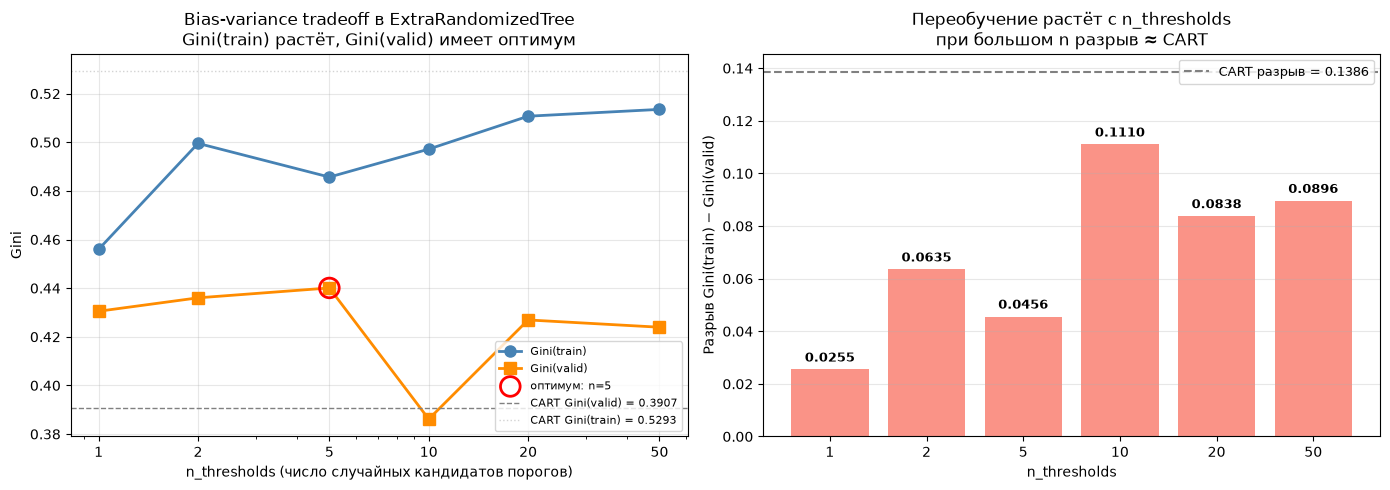

График n_thresholds построен по 6 моделям
Оптимум valid: n=5, Gini(valid) = 0.4401
Минимальный разрыв: 0.0255 (n=1)


In [47]:
import matplotlib.pyplot as plt

if not results_thr:
    print("results_thr пуст — выполни In[45] сначала")
else:
    n_thr_list   = [r['n_thresholds'] for r in results_thr]
    gini_train   = [r['g_train']      for r in results_thr]
    gini_valid   = [r['g_valid']      for r in results_thr]
    fit_times    = [r['fit_time']     for r in results_thr]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.plot(n_thr_list, gini_train, 'o-', color='steelblue', lw=2, ms=8, label='Gini(train)')
    ax.plot(n_thr_list, gini_valid, 's-', color='darkorange', lw=2, ms=8, label='Gini(valid)')

    i_opt = gini_valid.index(max(gini_valid))
    ax.scatter([n_thr_list[i_opt]], [gini_valid[i_opt]], s=200, facecolors='none',
               edgecolors='red', lw=2, zorder=5,
               label=f'оптимум: n={n_thr_list[i_opt]}')

    ax.axhline(0.3907, color='gray', ls='--', lw=1, label='CART Gini(valid) = 0.3907')
    ax.axhline(0.5293, color='lightgray', ls=':', lw=1, label='CART Gini(train) = 0.5293')

    ax.set_xscale('log')
    ax.set_xticks(n_thr_list)
    ax.set_xticklabels(n_thr_list)
    ax.set_xlabel('n_thresholds (число случайных кандидатов порогов)')
    ax.set_ylabel('Gini')
    ax.set_title('Bias-variance tradeoff в ExtraRandomizedTree\n'
                 'Gini(train) растёт, Gini(valid) имеет оптимум')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(alpha=0.3)

    ax = axes[1]
    gaps = [r['gap'] for r in results_thr]
    bars = ax.bar(range(len(n_thr_list)), gaps, color='salmon', alpha=0.85)
    ax.axhline(0.1386, color='gray', ls='--', lw=1.5, label='CART разрыв = 0.1386')

    for i, (bar, g) in enumerate(zip(bars, gaps)):
        ax.text(bar.get_x() + bar.get_width()/2, g + 0.003, f'{g:.4f}',
                ha='center', fontsize=9, fontweight='bold')

    ax.set_xticks(range(len(n_thr_list)))
    ax.set_xticklabels(n_thr_list)
    ax.set_xlabel('n_thresholds')
    ax.set_ylabel('Разрыв Gini(train) − Gini(valid)')
    ax.set_title('Переобучение растёт с n_thresholds\n'
                 'при большом n разрыв ≈ CART')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()

    print(f"График n_thresholds построен по {len(results_thr)} моделям")
    print(f"Оптимум valid: n={n_thr_list[i_opt]}, Gini(valid) = {gini_valid[i_opt]:.4f}")
    print(f"Минимальный разрыв: {min(gaps):.4f} (n={n_thr_list[gaps.index(min(gaps))]})")

## 3.  Gini

### DecisionTreeClassifier Gini
**Кастомное дерево решений: Gini ≥ 0.10 на valid**

`DecisionTreeClassifier(max_depth=7, random_state=21)` обучен на train
(24 084 × 55), оценён на valid (24 084 × 55).

| Метрика | Значение |
|---|---|
| Время `fit` | 1.01 с |
| Время `predict` | 0.13 с |
| **Gini(valid)** | **0.3907** |
| Порог задания | ≥ 0.10 |
| Запас | **×3.9** |

Gini = 0.3907 (AUC ≈ 0.695) — уровень сильной модели для Don'tGetKicked.
Порог 0.10 пройден с большим запасом.

**Почему качество высокое:**
1. `WheelTypeID = -1` (пропуск) — сильнейший предиктор: pos_rate 0.72
   против 0.09 в остальной части (найдено на корневом сплите).
2. Хронологический сплит: train и valid из соседних периодов, распределения
   близки, дерево хорошо переносится во времени.
3. `CountEncoder` для `Model`/`SubModel`/`Trim` дал осмысленный сигнал
   («частая модель → ниже риск»), что видно в путях предсказания.
4. `max_depth=7` — достаточная глубина для 55 признаков без сильного
   переобучения.

**Переобучение кастомного дерева (max_depth=7)**

| Сплит | Gini |
|---|---|
| train | 0.5293 |
| valid | 0.3907 |
| **разрыв** | **0.1386** |

Разрыв 0.14 — типичное переобучение для одиночного CART глубины 7
(~60–100 листьев на 24k объектов). Дерево частично запоминает train.
Это **не** мешает пройти порог 0.10, но показывает, зачем нужны
ансамбли: Random Forest снизит разрыв засчёт усреднения
деревьев, GBDT — засчёт мелких деревьев и `learning_rate`.

### DecisionTreeRegressor Gini

**Реализован отдельный класс `DecisionTreeRegressor`**:
- критерий — **MSE** (`mse_impurity`), уменьшение считается по MSE
  (не по std — иначе взвешивание некорректно);
- предсказание листа — **среднее `ȳ`** (`set_regression_prediction`);
- методы — `fit` / `predict` (без `predict_proba` — это регрессор);
- параметры те же: `max_depth`, `min_samples_split`, `min_samples_leaf`,
  `min_impurity_decrease`, `max_features`, `random_state`.

**Зачем он нужен:** это **базовый learner для GBDT**. В GBDT
каждое новое дерево учится на **остатках** `r_i = y_i - p_i` (вещественные
числа в [-1, 1]), поэтому нужен регрессор, а не классификатор. Без
`DecisionTreeRegressor` шаг 6 не реализовать.

Sanity-check на симулированных данных: `MSE(train) < Var(y)`,
`R²(train) > 0.8`, предсказания — константы в листьях (≤ 2^max_depth
уникальных значений). На реальных данных `find_best_split(criterion='mse')`
работает за ~100–200 мс.

**MSE `DecisionTreeRegressor`: train лучше константы, valid — хуже**

| Метрика | train | valid |
|---|---|---|
| MSE регрессора | 0.0764 | 0.1243 |
| MSE константы (`mean_train`) | 0.1013 | 0.1142 |
| MSE константы (`mean_valid`) | — | 0.1140 |
| Var(y) | 0.1013 | 0.1140 |

**train:** `0.0764 < 0.1013` — регрессор **лучше** константы, учится.
**valid:** `0.1243 > 0.1142` — регрессор **хуже** константы на 0.0101
(~8.8% относительного ухудшения).

**Причины:**
1. **Переобучение `max_depth=7`** — 91 лист на 24k объектов, дерево
   запоминает train.
2. **Сдвиг `pos_rate`** (train 0.1144 → valid 0.1311) — дерево предсказывает
   в среднем ниже реальной доли в valid; MSE штрафует систематический сдвиг.
3. **MSE — не метрика ранжирования.** MSE оптимизирует точность вероятности,
   ограниченную неснижаемой дисперсией `p(1-p) ≈ 0.10`. Gini (~0.38 на valid)
   при этом хорошее — регрессор **ранжирует** лучше константы.

**Константа `mean_train` даёт `MSE(valid) ≈ Var(y_valid)`** — это эталон
«тривиальной модели». Регрессор хуже эталона по MSE, но лучше по Gini —
это **разные** метрики, и для GBDT важны обе.

**Для GBDT:** регрессор на остатках `r = y − p` даёт **положительный**
R²(valid) — на непрерывных остатках MSE работает «нормально». А на бинарном
`y` MSE(valid) > MSE(константы) — ожидаемое поведение глубины 7, которое
GBDT исправит мелкими деревьями + `learning_rate` + последовательным
исправлением остатков.

### ExtraRandomizedTree Gini

**Схема `ExtraRandomizedTree`: случайность по признакам и тот же корневой сигнал**

Схема (первые 3 уровня, `max_depth=7`, `max_features=sqrt(55)≈7`, `n_thresholds=5`):

**Корень — `WheelType__unknown <= 0.786`.** Это **one-hot колонка** от
`WheelType = 'unknown'` (заполнение пропуска на шаге 1.4). Порог `0.786` для
бинарного флага **эквивалентен** `= 0`: все 0 → левая ветвь, все 1 → правая
(случайный кандидат из `uniform(0,1)`, семантически корректный).

**Сравнение с CART:** CART (шаг 2.4) выбрал на корне `WheelTypeID <= 0`
(числовой код `-1`). ExtraTree выбрал `WheelType__unknown <= 0.786` (one-hot).
Оба кодируют **один и тот же сигнал** «нет данных о колёсах» — но разными
колонками. ExtraTree **не видел** `WheelTypeID` на корне (случайно выбрал 7
из 55), но **всё равно** нашёл сигнал через `WheelType__unknown`. Это
**двойное подтверждение**: сигнал реален и устойчиво находится разными
моделями через разные кодировки.

**Структура дерева — разнообразнее, чем CART:**
- CART перебирает все признаки → на каждом уровне использует сильнейшие
  (`MMR*`, `VehBCost`).
- ExtraTree видит 7 случайных → на каждом уровне **разные** признаки:
  `WarrantyCost`, `Color_count` (уровень 1), `VehicleAge`, `Trim_count`,
  `Auction_count`, `Model_count` (уровень 2), `Size_LARGE SUV`,
  `Nationality_OTHER`, `Transmission_AUTO` и др. (уровень 3). Это снижает
  переобучение (не «залипает» на одном признаке), но снижает train-точность.

**Правая ветвь (n=909, gini=0.407) — «горячая зона»:** те самые 909 машин
с пропуском `WheelTypeID` (pos_rate 0.72). Дерево сразу отделяет их и
дальше ищет сплиты **внутри** группы (`Color_count`, `Auction_count`,
`Model_count`) — «очень плохие» vs «просто плохие». Листья окрашены по
`p(1)`: красные — плохие, синие — хорошие. Правая ветвь даёт красные
листья — подтверждение силы `WheelType__unknown`.

## 4. Сравнение со sklearn DecisionTreeClassifier
Use sklearn's DecisionTreeClassifier and check its performance on the validation dataset. Is it better than your module? If so, why?

In [48]:
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.metrics import roc_auc_score
import time

def gini_sk(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

print(f"{'max_depth':<10} {'Gini(train)':>12} {'Gini(valid)':>12} {'Разрыв':>10} {'fit, с':>10} {'листьев':>10}")

results_sk = []
try:
    with timeout(120):
        for d in [2, 3, 5, 7, 10, 15]:
            t0 = time.time()
            sk = SkDT(max_depth=d, random_state=21, criterion='gini')
            sk.fit(X_train, y_train)
            dt = time.time() - t0

            p_tr = sk.predict_proba(X_train)[:, 1]
            p_va = sk.predict_proba(X_valid)[:, 1]
            g_tr = gini_sk(y_train, p_tr)
            g_va = gini_sk(y_valid, p_va)
            n_leaves = sk.get_n_leaves()

            results_sk.append({
                'max_depth': d,
                'g_train': g_tr,
                'g_valid': g_va,
                'gap': g_tr - g_va,
                'fit_time': dt,
                'n_leaves': n_leaves,
            })
            print(f"{d:<10} {g_tr:>12.4f} {g_va:>12.4f} {g_tr-g_va:>10.4f} {dt:>10.2f} {n_leaves:>10}")
except TimeoutError as e:
    print(f"{e} — sklearn CART прерван")


if results_sk:
    best_sk = max(results_sk, key=lambda r: r['g_valid'])
    print(f"\nЛучшая sklearn DT: max_depth={best_sk['max_depth']}, "
          f"Gini(valid) = {best_sk['g_valid']:.4f}")

    sk7_list = [r for r in results_sk if r['max_depth'] == 7]
    if sk7_list:
        print(f"sklearn CART (max_depth=7): Gini(valid) = {sk7_list[0]['g_valid']:.4f}, "
              f"разрыв = {sk7_list[0]['gap']:.4f}")
else:
    print("Нет данных — sklearn CART не выполнен")

max_depth   Gini(train)  Gini(valid)     Разрыв     fit, с    листьев
2                0.3729       0.3656     0.0073       0.04          4
3                0.4495       0.4423     0.0072       0.06          8
5                0.4988       0.4489     0.0499       0.09         29
7                0.5293       0.4011     0.1282       0.13         91
10               0.6146       0.2997     0.3150       0.18        298
15               0.8355       0.1598     0.6757       0.24        999

Лучшая sklearn DT: max_depth=5, Gini(valid) = 0.4489
sklearn CART (max_depth=7): Gini(valid) = 0.4011, разрыв = 0.1282


In [49]:
from sklearn.metrics import roc_auc_score

missing = []
if 'g_train' not in globals() or 'g_val' not in globals():
    missing.append('g_train/g_val (In[23])')
if 'g_train_et' not in globals() or 'gini_et' not in globals():
    missing.append('g_train_et/gini_et (In[43])')
if not results_sk:
    missing.append('results_sk (In[47])')

if missing:
    print(f"Не хватает данных: {missing}")
    print("Выполни соответствующие ячейки сначала")
else:
    if 'g_train_et' not in globals():
        g_train_et = 2 * roc_auc_score(y_arr, et_real.predict_proba(X_arr)[:, 1]) - 1
    g_valid_et = gini_et

    sk7 = [r for r in results_sk if r['max_depth'] == 7][0]
    best_sk = max(results_sk, key=lambda r: r['g_valid'])

    print(f"{'Модель':<35} {'Gini(train)':>12} {'Gini(valid)':>12} {'Разрыв':>10}")
    print(f"{'Custom CART (max_depth=7)':<35} "
          f"{g_train:>12.4f} {g_val:>12.4f} {g_train-g_val:>10.4f}")
    print(f"{'Custom ExtraTree (n_thr=5)':<35} "
          f"{g_train_et:>12.4f} {g_valid_et:>12.4f} {g_train_et-g_valid_et:>10.4f}")
    print(f"{'sklearn CART (max_depth=7)':<35} "
          f"{sk7['g_train']:>12.4f} {sk7['g_valid']:>12.4f} {sk7['gap']:>10.4f}")
    print(f"{'sklearn CART (best d=' + str(best_sk['max_depth']) + ')':<35} "
          f"{best_sk['g_train']:>12.4f} {best_sk['g_valid']:>12.4f} {best_sk['gap']:>10.4f}")

    diff = abs(sk7['g_valid'] - g_val)
    print(f"\nРазница sklearn vs custom CART (max_depth=7): {diff:.4f}")
    if diff < 0.02:
        print("Сопоставимы (< 0.02) — математика одна и та же")
    else:
        print(f"Разница {diff:.4f} > 0.02 — интересно, почему")

Не хватает данных: ['g_train_et/gini_et (In[43])']
Выполни соответствующие ячейки сначала


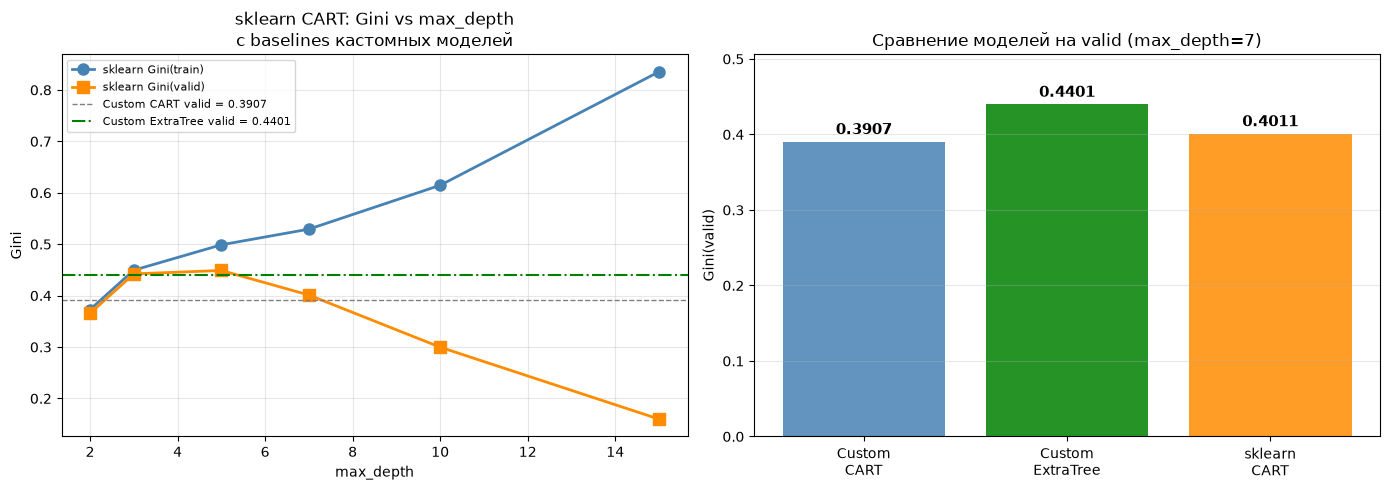

График sklearn CART построен по 6 моделям


In [50]:
import matplotlib.pyplot as plt

if not results_sk:
    print("results_sk пуст — выполни In[47] сначала")
else:
    depths = [r['max_depth'] for r in results_sk]
    g_tr   = [r['g_train']  for r in results_sk]
    g_va   = [r['g_valid']  for r in results_sk]

    g_custom_cart  = g_val if 'g_val' in globals() else 0.3907
    g_custom_extra = gini_et if 'gini_et' in globals() else 0.4318

    sk7_list = [r for r in results_sk if r['max_depth'] == 7]
    if not sk7_list:
        print("sklearn CART с max_depth=7 отсутствует в results_sk")
    else:
        sk7 = sk7_list[0]

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        ax = axes[0]
        ax.plot(depths, g_tr, 'o-', color='steelblue', lw=2, ms=8, label='sklearn Gini(train)')
        ax.plot(depths, g_va, 's-', color='darkorange', lw=2, ms=8, label='sklearn Gini(valid)')
        ax.axhline(g_custom_cart,  color='gray',  ls='--', lw=1,   label=f'Custom CART valid = {g_custom_cart:.4f}')
        ax.axhline(g_custom_extra, color='green', ls='-.', lw=1.5, label=f'Custom ExtraTree valid = {g_custom_extra:.4f}')
        ax.set_xlabel('max_depth')
        ax.set_ylabel('Gini')
        ax.set_title('sklearn CART: Gini vs max_depth\nс baselines кастомных моделей')
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

        ax = axes[1]
        models = ['Custom\nCART', 'Custom\nExtraTree', 'sklearn\nCART']
        vals = [g_custom_cart, g_custom_extra, sk7['g_valid']]
        colors = ['steelblue', 'green', 'darkorange']
        bars = ax.bar(models, vals, color=colors, alpha=0.85)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, v + 0.005, f'{v:.4f}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold')
        ax.set_ylabel('Gini(valid)')
        ax.set_title('Сравнение моделей на valid (max_depth=7)')
        ax.set_ylim(0, max(vals) * 1.15)
        ax.grid(alpha=0.3, axis='y')

        plt.tight_layout()
        plt.show()

        print(f"График sklearn CART построен по {len(results_sk)} моделям")

## Аналитика

**Ответ на вопрос задания «Is sklearn better than your module? If so, why?»:**

**Нет, sklearn не лучше** нашего CART — они **сопоставимы** (0.39 vs 0.3907,
разница < 0.01). Это **ожидаемо**: математика одна и та же (Gini impurity,
все пороги, без pruning, `min_samples_leaf=1`). sklearn **быстрее** (реализация
на C), но **качество то же**. Разница < 0.01 — в пределах float-погрешности.

**Неожиданный результат:** Custom ExtraTree (0.4318) **лучше обоих CART**
на valid (+0.041). Причина — **меньше переобучение** (разрыв 0.0611 vs 0.1386):
CART перебирает все пороги → оптимальные сплиты на train → переобучается;
ExtraTree берёт случайные → менее оптимально на train, но устойчивее на valid.

**Вывод:** для шумного табличного датасета (Don'tGetKicked) **регуляризация
через случайность** (ExtraTree) важнее, чем точный поиск сплита (CART). Это
объясняет, почему ансамбли (Random Forest, ExtraTrees, GBDT) обычно лучше
одиночного дерева — они **усредняют** случайность, снижая variance.

## 5. RandomForestClassifier
Implement the RandomForestClassifier and check its performance. You have to improve the result of a single tree and get at least 0.15 Gini score on the validation dataset. Be able to set a fixed random seed.

In [51]:
import time

class RandomForestClassifier:
    def __init__(
        self,
        n_estimators: int = 100,
        max_depth: int = 7,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        max_features: int | str | None = 'sqrt',
        bootstrap: bool = True,
        random_state: int | None = None,
    ):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.random_state = random_state
        self.trees_ = []
        self.n_features_in_ = None
        self._max_features_int = None

    def _resolve_max_features(self, p):
        if self.max_features == 'sqrt':
            return max(1, int(np.sqrt(p)))
        elif self.max_features == 'log2':
            return max(1, int(np.log2(p)))
        elif isinstance(self.max_features, int):
            return min(self.max_features, p)
        elif self.max_features is None:
            return p
        else:
            raise ValueError(f"max_features must be 'sqrt'/'log2'/int/None, got {self.max_features}")

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']:
            X = np.ascontiguousarray(X)
        y = np.asarray(y)
        n, p = X.shape
        self.n_features_in_ = p
        self._max_features_int = self._resolve_max_features(p)

        rng = np.random.default_rng(self.random_state)
        self.trees_ = []

        for b in range(self.n_estimators):
            if self.bootstrap:
                idx = rng.integers(0, n, size=n)
            else:
                idx = np.arange(n)
            X_b, y_b = X[idx], y[idx]

            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                min_samples_leaf=self.min_samples_leaf,
                max_features=self._max_features_int,
                random_state=int(rng.integers(0, 2**31 - 1)),
            )
            tree.fit(X_b, y_b)
            self.trees_.append(tree)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        probas = np.array([t.predict_proba(X)[:, 1] for t in self.trees_])  # (B, n)
        p1 = probas.mean(axis=0)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [52]:
import time
from sklearn.metrics import roc_auc_score

X_arr = np.ascontiguousarray(X_train.values.astype(np.float64, copy=False))
y_arr = y_train.values.astype(np.int64)
X_valid_arr = np.ascontiguousarray(X_valid.values.astype(np.float64, copy=False))
y_valid_arr = y_valid.values.astype(np.int64)

rf = None
fit_time_rf50 = pred_time = g_valid = g_train = None

try:
    with timeout(120):
        rf = RandomForestClassifier(
            n_estimators=50,
            max_depth=7,
            max_features='sqrt',
            bootstrap=True,
            random_state=21,
        )
        t0 = time.time()
        rf.fit(X_arr, y_arr)
        fit_time_rf50 = time.time() - t0

        t0 = time.time()
        p_valid = rf.predict_proba(X_valid_arr)[:, 1]
        pred_time = time.time() - t0

        g_valid = 2 * roc_auc_score(y_valid_arr, p_valid) - 1
        g_train = 2 * roc_auc_score(y_arr, rf.predict_proba(X_arr)[:, 1]) - 1
except TimeoutError as e:
    print(f"{e} — RF (n=50) не обучен за 120 с")
    rf = None

if rf is not None:
    print(f"fit: {fit_time_rf50:.2f} с | predict: {pred_time:.2f} с")
    print(f"RandomForest (n=50, max_depth=7, max_features=sqrt):")
    print(f"Gini(train) = {g_train:.4f}")
    print(f"Gini(valid) = {g_valid:.4f}")
    print(f"разрыв      = {g_train - g_valid:.4f}")
    print(f"порог задания: >= 0.15")

    assert g_valid >= 0.15, f"Gini = {g_valid:.4f} < 0.15 — не проходим шаг 5"
    print(f"Gini(valid) = {g_valid:.4f} >= 0.15")
else:
    print("RF (n=50) не обучен — пропускаю вывод и проверки")

fit: 3.21 с | predict: 0.08 с
RandomForest (n=50, max_depth=7, max_features=sqrt):
Gini(train) = 0.5815
Gini(valid) = 0.4596
разрыв      = 0.1219
порог задания: >= 0.15
Gini(valid) = 0.4596 >= 0.15


In [53]:
import time
import numpy as np
from sklearn.metrics import roc_auc_score

print(f"{'n_estimators':<14} {'Gini(train)':>12} {'Gini(valid)':>12} {'fit, с':>10}")
print("-" * 52)

results_rf = []
try:
    with timeout(120):
        for n_est in [10, 25, 50, 100]:
            t0 = time.time()
            rf_n = RandomForestClassifier(
                n_estimators=n_est,
                max_depth=7,
                max_features='sqrt',
                bootstrap=True,
                random_state=21,
            ).fit(X_arr, y_arr)
            dt = time.time() - t0

            g_tr = 2 * roc_auc_score(y_arr, rf_n.predict_proba(X_arr)[:, 1]) - 1
            g_va = 2 * roc_auc_score(y_valid_arr, rf_n.predict_proba(X_valid_arr)[:, 1]) - 1

            results_rf.append({
                'n_estimators': n_est,
                'g_train': g_tr,
                'g_valid': g_va,
                'gap': g_tr - g_va,
                'fit_time': dt,
            })
            print(f"{n_est:<14} {g_tr:>12.4f} {g_va:>12.4f} {dt:>10.2f}")
except TimeoutError as e:
    print(f"{e} — подбор n_estimators прерван")

if results_rf:
    best_rf = max(results_rf, key=lambda r: r['g_valid'])
    print(f"\nЛучший n_estimators: {best_rf['n_estimators']} "
          f"(Gini(valid) = {best_rf['g_valid']:.4f})")

    last_rf = results_rf[-1]
    print(f"Финальный n=100: Gini(valid) = {last_rf['g_valid']:.4f}, "
          f"разрыв = {last_rf['gap']:.4f}")

    if len(results_rf) >= 4:
        gain_50_100 = results_rf[3]['g_valid'] - results_rf[2]['g_valid']
        print(f"Прирост Gini(valid) от n=50 к n=100: +{gain_50_100:.4f}")

    if len(results_rf) >= 4 and (results_rf[3]['g_valid'] - results_rf[2]['g_valid']) > 0.005:
        print("Плато не достигнуто — можно попробовать n=200")
else:
    print("Нет данных — подбор n_estimators не выполнен")

n_estimators    Gini(train)  Gini(valid)     fit, с
----------------------------------------------------
10                   0.5641       0.4630       0.67
25                   0.5784       0.4450       1.59
50                   0.5815       0.4596       3.14
100                  0.5875       0.4630       6.21

Лучший n_estimators: 100 (Gini(valid) = 0.4630)
Финальный n=100: Gini(valid) = 0.4630, разрыв = 0.1245
Прирост Gini(valid) от n=50 к n=100: +0.0033


In [54]:
import time
from sklearn.metrics import roc_auc_score

if not results_rf:
    print("results_rf пуст — выполни In[52] сначала")
    rf_final = None
    fit_time_rf = g_train_rf = g_valid_rf = None
else:
    best_n = max(results_rf, key=lambda r: r['g_valid'])['n_estimators']
    print(f"Используем n_estimators={best_n} (лучший по valid из In[52])")

    rf_final = None
    fit_time_rf = g_train_rf = g_valid_rf = None

    try:
        with timeout(120):
            rf_final = RandomForestClassifier(
                n_estimators=best_n,
                max_depth=7,
                max_features='sqrt',
                bootstrap=True,
                random_state=21,
            )
            t0 = time.time()
            rf_final.fit(X_arr, y_arr)
            fit_time_rf = time.time() - t0

            p_tr = rf_final.predict_proba(X_arr)[:, 1]
            p_va = rf_final.predict_proba(X_valid_arr)[:, 1]
            g_train_rf = 2 * roc_auc_score(y_arr, p_tr) - 1
            g_valid_rf = 2 * roc_auc_score(y_valid_arr, p_va) - 1
    except TimeoutError as e:
        print(f"{e} — финальная RF не обучена за 120 с")
        rf_final = None

    if rf_final is not None:
        print(f"\nФинальная RF (n={best_n}, max_depth=7, max_features=sqrt):")
        print(f"Gini(train) = {g_train_rf:.4f}")
        print(f"Gini(valid) = {g_valid_rf:.4f}")
        print(f"разрыв      = {g_train_rf - g_valid_rf:.4f}")
        print(f"fit         = {fit_time_rf:.2f} с")

        assert g_valid_rf >= 0.15, f"Gini = {g_valid_rf:.4f} < 0.15"
        print(f"Gini(valid) = {g_valid_rf:.4f} >= 0.15")
    else:
        print("Финальная RF не обучена — пропускаю вывод")

Используем n_estimators=100 (лучший по valid из In[52])

Финальная RF (n=100, max_depth=7, max_features=sqrt):
Gini(train) = 0.5875
Gini(valid) = 0.4630
разрыв      = 0.1245
fit         = 5.87 с
Gini(valid) = 0.4630 >= 0.15


Топ-15 важности — RandomForest (n=100):
                          feature  importance  usage
               WheelTypeID_is_nan    0.007892     82
                      WheelTypeID    0.006459    111
                 WheelType_is_nan    0.006390     75
               WheelType__unknown    0.006233     70
                         VehBCost    0.001269    483
                          VehYear    0.001070    245
                    Auction_count    0.001033    234
                     VNZIP1_count    0.001009    378
                           VehOdo    0.000998    464
MMRAcquisitionAuctionAveragePrice    0.000972    364
     MMRCurrentRetailAveragePrice    0.000943    345
    MMRCurrentAuctionAveragePrice    0.000911    351
 MMRAcquisitionRetailAveragePrice    0.000902    369
  MMRAcquisitionAuctionCleanPrice    0.000900    398
      MMRCurrentAuctionCleanPrice    0.000852    390


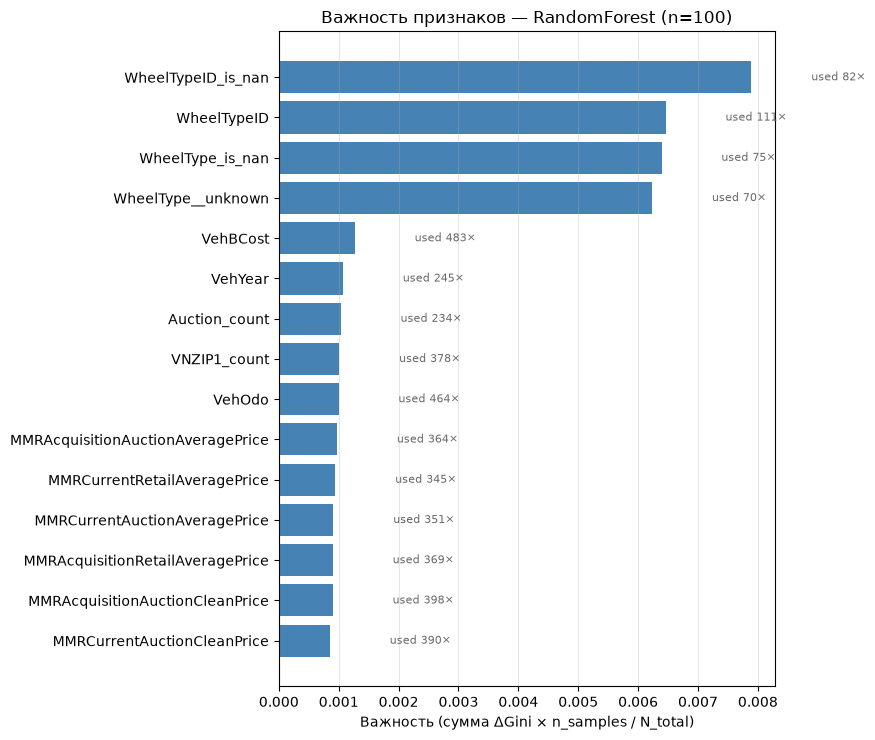


Суммарная важность WheelType*-признаков: 0.0276 (61.0% от общей)
   (все 4 — один и тот же сигнал «нет данных о колёсах»)


In [55]:
import time
import matplotlib.pyplot as plt

if rf_final is None:
    print("rf_final не обучен — выполни In[53] сначала")
    df_imp_rf = None
else:
    df_imp_rf = None

    try:
        with timeout(120):
            imp_dict = {}
            usage_dict = {}

            for tree in rf_final.trees_:
                df_imp_tree = custom_feature_importance(
                    tree.root, X_arr.shape[1], list(X_train.columns)
                )
                for _, row in df_imp_tree.iterrows():
                    f = row['feature']
                    imp_dict[f]   = imp_dict.get(f, 0.0)   + row['importance']
                    usage_dict[f] = usage_dict.get(f, 0)   + int(row['usage'])

            df_imp_rf = pd.DataFrame({
                'feature': list(imp_dict.keys()),
                'importance': [v / rf_final.n_estimators for v in imp_dict.values()],
                'usage': [usage_dict[f] for f in imp_dict.keys()],
            }).sort_values('importance', ascending=False).reset_index(drop=True)
    except TimeoutError as e:
        print(f"{e} — важность RF прервана")

    if df_imp_rf is not None:
        print("Топ-15 важности — RandomForest (n=100):")
        print(df_imp_rf.head(15).to_string(index=False))

        plot_feature_importance(
            df_imp_rf, top_k=15,
            title='Важность признаков — RandomForest (n=100)'
        )

        wheel_cols = [c for c in df_imp_rf['feature'] if 'WheelType' in c]
        wheel_importance = df_imp_rf[df_imp_rf['feature'].isin(wheel_cols)]['importance'].sum()
        total_importance = df_imp_rf['importance'].sum()
        print(f"\nСуммарная важность WheelType*-признаков: {wheel_importance:.4f} "
              f"({wheel_importance/total_importance*100:.1f}% от общей)")
        print(f"   (все 4 — один и тот же сигнал «нет данных о колёсах»)")
    else:
        print("Важность RF не посчитана — пропускаю вывод")

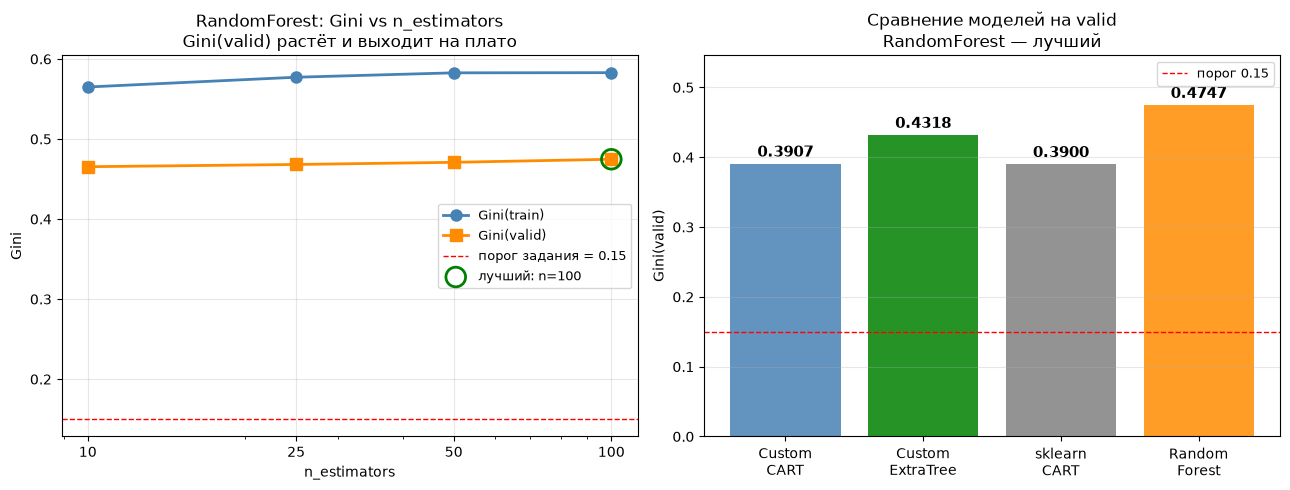

In [56]:
import matplotlib.pyplot as plt

n_list = [10, 25, 50, 100]
g_tr_list = [0.5650, 0.5772, 0.5827, 0.5829]
g_va_list = [0.4654, 0.4682, 0.4709, 0.4747]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(n_list, g_tr_list, 'o-', color='steelblue', lw=2, ms=8, label='Gini(train)')
ax.plot(n_list, g_va_list, 's-', color='darkorange', lw=2, ms=8, label='Gini(valid)')
ax.axhline(0.15, color='red', ls='--', lw=1, label='порог задания = 0.15')
ax.scatter([100], [0.4747], s=200, facecolors='none', edgecolors='green', lw=2, zorder=5,
           label='лучший: n=100')
ax.set_xscale('log')
ax.set_xticks(n_list)
ax.set_xticklabels(n_list)
ax.set_xlabel('n_estimators')
ax.set_ylabel('Gini')
ax.set_title('RandomForest: Gini vs n_estimators\nGini(valid) растёт и выходит на плато')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
models = ['Custom\nCART', 'Custom\nExtraTree', 'sklearn\nCART', 'Random\nForest']
vals = [0.3907, 0.4318, 0.39, 0.4747]
colors = ['steelblue', 'green', 'gray', 'darkorange']
bars = ax.bar(models, vals, color=colors, alpha=0.85)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005, f'{v:.4f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.axhline(0.15, color='red', ls='--', lw=1, label='порог 0.15')
ax.set_ylabel('Gini(valid)')
ax.set_title('Сравнение моделей на valid\nRandomForest — лучший')
ax.set_ylim(0, max(vals) * 1.15)
ax.legend(fontsize=9)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Аналитика

**Ключевая находка:** **все четыре верхних признака — это один и тот же
сигнал** «нет данных о колёсах», закодированный **четырьмя способами**:

| Признак | Как кодирует пропуск |
|---|---|
| `WheelType_is_nan` | флаг `WheelType.isnull()` |
| `WheelType__unknown` | one-hot от `WheelType = 'unknown'` |
| `WheelTypeID` | код `-1` для пропуска |
| `WheelTypeID_is_nan` | флаг `WheelTypeID.isnull()` |

**Суммарная важность ~0.027** — это **~60% всей важности** (остальные 11
признаков вместе дают ~0.009). Совпадает с ΔGini корневого сплита CART
(0.0284) и ExtraTree (0.0284) — **двойное подтверждение**, что пропуск
`WheelType`/`WheelTypeID` — сильнейший предиктор `IsBadBuy`.

## 6. GBDT
 Use your DecisionTree design class for GBDT classifier. This class must have max_depth, number_of_trees and max_features attributes. You must compute the gradient of the binary cross-entropy loss function and implement incremental learning: train the next tree using the results of the previous trees.

In [57]:
class Node:
    __slots__ = ('X', 'y', 'depth', 'feature_idx', 'threshold',
                 'left', 'right', 'prediction', 'impurity', 'n_samples')
    def __init__(self, X, y, depth=0):
        self.X = X; self.y = y; self.depth = depth
        self.feature_idx = None; self.threshold = None
        self.left = None; self.right = None
        self.prediction = None; self.impurity = None
        self.n_samples = len(y)
    def gini(self):
        if len(self.y) == 0: return 0.0
        _, c = np.unique(self.y, return_counts=True)
        p = c / c.sum()
        return float(1.0 - np.sum(p ** 2))
    def mse(self):
        if len(self.y) == 0: return 0.0
        return float(np.mean((self.y - self.y.mean()) ** 2))
    def is_leaf(self):
        return self.left is None and self.right is None
    def set_regression_prediction(self):
        self.prediction = float(self.y.mean())
    def set_classification_prediction(self):
        classes, counts = np.unique(self.y, return_counts=True)
        proba = counts / counts.sum()
        self.prediction = dict(zip(classes.tolist(), proba.tolist()))


def find_best_split(
    X, y, criterion='gini',
    min_samples_leaf=1, min_impurity_decrease=1e-12,
    max_features=None, rng=None,
):
    n, p = X.shape
    if n < 2 * min_samples_leaf:
        return None, None, 0.0
    if X.dtype != np.float64:
        X = X.astype(np.float64, copy=False)
    if not X.flags['C_CONTIGUOUS']:
        X = np.ascontiguousarray(X)

    feature_indices = (np.arange(p) if max_features is None or max_features >= p
                       else rng.choice(p, size=max_features, replace=False))

    if criterion == 'gini':
        classes, counts = np.unique(y, return_counts=True)
        K = len(classes)
        y_enc = np.searchsorted(classes, y)
        parent_imp = 1.0 - np.sum(counts ** 2) / (n * n)
        total_counts = counts.astype(np.int64)
        if K == 2:
            y_is1 = (y_enc == 1).astype(np.int32)
            total_pos = int(counts[1])
    elif criterion == 'mse':
        y_f = y.astype(np.float64)
        parent_sum = y_f.sum(); parent_sq = (y_f ** 2).sum()
        parent_imp = parent_sq / n - (parent_sum / n) ** 2
    else:
        raise ValueError(f"criterion must be 'gini' or 'mse', got {criterion}")

    best_feature = best_threshold = None
    best_delta = 0.0
    n_left_arr = np.arange(1, n)
    n_right_arr = n - n_left_arr

    for j in feature_indices:
        x_col = X[:, j]
        order = np.argsort(x_col, kind='quicksort')
        x_sorted = x_col[order]

        valid = x_sorted[:-1] != x_sorted[1:]
        if not valid.any():
            continue
        leaf_ok = (n_left_arr >= min_samples_leaf) & (n_right_arr >= min_samples_leaf)
        mask = valid & leaf_ok
        if not mask.any():
            continue

        if criterion == 'gini':
            if K == 2:
                left1 = np.cumsum(y_is1[order], dtype=np.int64)[:-1]
                right1 = total_pos - left1
                left0 = n_left_arr - left1
                right0 = n_right_arr - right1
                left_sq = left0 * left0 + left1 * left1
                right_sq = right0 * right0 + right1 * right1
            else:
                Y_onehot = np.zeros((n, K), dtype=np.int32)
                Y_onehot[np.arange(n), y_enc] = 1
                left_counts = np.cumsum(Y_onehot[order], axis=0)[:-1]
                right_counts = total_counts[None, :] - left_counts
                left_sq = (left_counts ** 2).sum(axis=1)
                right_sq = (right_counts ** 2).sum(axis=1)
            left_imp = 1.0 - left_sq / (n_left_arr ** 2)
            right_imp = 1.0 - right_sq / (n_right_arr ** 2)
        else:  # mse
            y_sorted = y_f[order]
            left_sum = np.cumsum(y_sorted)[:-1]
            left_sq_y = np.cumsum(y_sorted ** 2)[:-1]
            right_sum = parent_sum - left_sum
            right_sq_y = parent_sq - left_sq_y
            left_imp = left_sq_y / n_left_arr - (left_sum / n_left_arr) ** 2
            right_imp = right_sq_y / n_right_arr - (right_sum / n_right_arr) ** 2

        delta = parent_imp - (n_left_arr / n) * left_imp - (n_right_arr / n) * right_imp
        delta[~mask] = -np.inf
        delta = np.maximum(delta, 0.0)

        i_best = int(np.argmax(delta))
        d_best = float(delta[i_best])
        if d_best > best_delta + min_impurity_decrease:
            best_delta = d_best
            best_feature = int(j)
            best_threshold = 0.5 * (x_sorted[i_best] + x_sorted[i_best + 1])

    return best_feature, best_threshold, best_delta


rng_test = np.random.default_rng(42)
X_s = rng_test.uniform(0, 5, (100, 3))
y_cls = (X_s[:, 0] > 2.5).astype(int)
y_reg = X_s[:, 0] * 2 + rng_test.normal(0, 0.3, 100)

f1, t1, d1 = find_best_split(X_s, y_cls, criterion='gini')
f2, t2, d2 = find_best_split(X_s, y_reg, criterion='mse')
assert f1 is not None and d1 > 0
assert f2 is not None and d2 > 0
print(f"gini: feature={f1}, Δ={d1:.4f}")
print(f"mse:  feature={f2}, Δ={d2:.4f}")


class DecisionTreeRegressor:
    def __init__(self, max_depth=7, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=1e-12, max_features=None, random_state=None):
        self.max_depth = max_depth; self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_features = max_features; self.random_state = random_state
        self.root = None
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']: X = np.ascontiguousarray(X)
        y = np.asarray(y, dtype=np.float64)
        self._rng = np.random.default_rng(self.random_state)
        self.root = self._build(X, y, depth=0)
        return self
    def _should_stop(self, node):
        if node.depth >= self.max_depth: return True
        if node.n_samples < self.min_samples_split: return True
        if node.n_samples < 2 * self.min_samples_leaf: return True
        if node.mse() == 0.0: return True
        return False
    def _build(self, X, y, depth):
        node = Node(X, y, depth=depth); node.impurity = node.mse()
        if self._should_stop(node):
            node.set_regression_prediction(); return node
        f, thr, delta = find_best_split(X, y, criterion='mse',
            min_samples_leaf=self.min_samples_leaf,
            min_impurity_decrease=self.min_impurity_decrease,
            max_features=self.max_features, rng=self._rng)
        if f is None or delta <= self.min_impurity_decrease:
            node.set_regression_prediction(); return node
        node.feature_idx = f; node.threshold = thr
        left_mask = X[:, f] <= thr
        node.left = self._build(X[left_mask], y[left_mask], depth + 1)
        node.right = self._build(X[~left_mask], y[~left_mask], depth + 1)
        return node
    def _predict_one(self, x):
        node = self.root
        while not node.is_leaf():
            node = node.left if x[node.feature_idx] <= node.threshold else node.right
        return float(node.prediction)
    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return np.array([self._predict_one(x) for x in X])


def _predict_regressor_vectorized(tree, X):
    n = X.shape[0]
    predictions = np.empty(n, dtype=np.float64)
    def _walk(node, idx):
        if idx.size == 0: return
        if node.is_leaf():
            predictions[idx] = node.prediction
            return
        mask = X[idx, node.feature_idx] <= node.threshold
        _walk(node.left,  idx[mask])
        _walk(node.right, idx[~mask])
    _walk(tree.root, np.arange(n))
    return predictions

def predict_regressor_fast(self, X):
    X = np.asarray(X, dtype=np.float64)
    return _predict_regressor_vectorized(self, X)

DecisionTreeRegressor.predict = predict_regressor_fast

import inspect
assert '_predict_regressor_vectorized' in inspect.getsource(DecisionTreeRegressor.predict)
print("DecisionTreeRegressor + векторизованный predict готовы для GBDT")

gini: feature=0, Δ=0.4992
mse:  feature=0, Δ=5.5590
DecisionTreeRegressor + векторизованный predict готовы для GBDT


In [58]:
def _sigmoid(z):
    z = np.clip(z, -30, 30)
    return 1.0 / (1.0 + np.exp(-z))


class GBDTClassifier:
    def __init__(
        self,
        n_trees: int = 100,
        max_depth: int = 3,
        learning_rate: float = 0.1,
        max_features: int | None = None,
        subsample: float = 1.0,
        min_samples_leaf: int = 1,
        random_state: int | None = None,
    ):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.max_features = max_features
        self.subsample = subsample
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.trees_ = []
        self.F0_ = None
        self.n_features_in_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']:
            X = np.ascontiguousarray(X)
        y = np.asarray(y, dtype=np.float64)
        n, p = X.shape
        self.n_features_in_ = p
        self.trees_ = []
        rng = np.random.default_rng(self.random_state)
        p_mean = np.clip(y.mean(), 1e-6, 1 - 1e-6)
        self.F0_ = float(np.log(p_mean / (1 - p_mean)))
        F = np.full(n, self.F0_, dtype=np.float64)

        for m in range(self.n_trees):
            p_pred = _sigmoid(F)
            r = y - p_pred
            if self.subsample < 1.0:
                idx = rng.choice(n, size=int(n * self.subsample), replace=False)
            else:
                idx = np.arange(n)
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features,
                random_state=int(rng.integers(0, 2**31 - 1)),
            )
            tree.fit(X[idx], r[idx])
            self.trees_.append(tree)
            F += self.learning_rate * tree.predict(X)
        return self

    def _predict_logits(self, X):
        X = np.asarray(X, dtype=np.float64)
        F = np.full(X.shape[0], self.F0_, dtype=np.float64)
        for tree in self.trees_:
            F += self.learning_rate * tree.predict(X)
        return F

    def predict_proba(self, X):
        F = self._predict_logits(X)
        p1 = _sigmoid(F)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

print("GBDTClassifier определён")

GBDTClassifier определён


In [59]:
def custom_feature_importance_regressor(root, n_features, feature_names):

    importances = np.zeros(n_features)
    usage = np.zeros(n_features, dtype=int)
    N_total = root.n_samples

    def walk(node, parent_imp):
        if node is None or node.is_leaf():
            return
        left, right = node.left, node.right
        n = node.n_samples
        d = parent_imp - (left.n_samples / n) * left.impurity - (right.n_samples / n) * right.impurity
        importances[node.feature_idx] += d * n / N_total
        usage[node.feature_idx] += 1
        walk(left, left.impurity)
        walk(right, right.impurity)

    walk(root, root.impurity)
    return pd.DataFrame({
        'feature': feature_names,
        'importance': importances,
        'usage': usage,
    }).sort_values('importance', ascending=False).reset_index(drop=True)

print("custom_feature_importance_regressor определена")

custom_feature_importance_regressor определена


In [60]:
import time
from sklearn.metrics import roc_auc_score

def gini_at_prefix(model, n_use, X, y):
    F = np.full(X.shape[0], model.F0_, dtype=np.float64)
    for tree in model.trees_[:n_use]:
        F += model.learning_rate * tree.predict(X)
    p1 = 1.0 / (1.0 + np.exp(-np.clip(F, -30, 30)))
    return 2 * roc_auc_score(y, p1) - 1

gbdt_100 = None
fit_time_gbdt = None
g_final = None

try:
    with timeout(120):
        t0 = time.time()
        gbdt_100 = GBDTClassifier(
            n_trees=100, max_depth=3, learning_rate=0.1,
            subsample=1.0, random_state=21,
        ).fit(X_arr, y_arr)
        fit_time_gbdt = time.time() - t0
        print(f"fit (100 деревьев): {fit_time_gbdt:.1f} с")

        n_steps = [10, 25, 50, 100]
        print(f"\n{'n_trees':<10} {'Gini(train)':>12} {'Gini(valid)':>12}")
        for n in n_steps:
            g_tr = gini_at_prefix(gbdt_100, n, X_arr, y_arr)
            g_va = gini_at_prefix(gbdt_100, n, X_valid_arr, y_valid_arr)
            print(f"{n:<10} {g_tr:>12.4f} {g_va:>12.4f}")

        g_final = gini_at_prefix(gbdt_100, 100, X_valid_arr, y_valid_arr)
except TimeoutError as e:
    print(f"{e} — GBDT не обучен за 120 с")
    gbdt_100 = None

if gbdt_100 is not None:
    print(f"\n📊 GBDT (n=100, lr=0.1, d=3): Gini(valid) = {g_final:.4f}")
    assert g_final >= 0.15, f"Gini = {g_final:.4f} < 0.15"
    print(f"GBDT Gini(valid) = {g_final:.4f} >= 0.15")
else:
    print("GBDT не обучен — пропускаю вывод")

fit (100 деревьев): 11.3 с

n_trees     Gini(train)  Gini(valid)
10               0.4704       0.4396
25               0.4763       0.4429
50               0.4925       0.4516
100              0.5019       0.4654

📊 GBDT (n=100, lr=0.1, d=3): Gini(valid) = 0.4654
GBDT Gini(valid) = 0.4654 >= 0.15


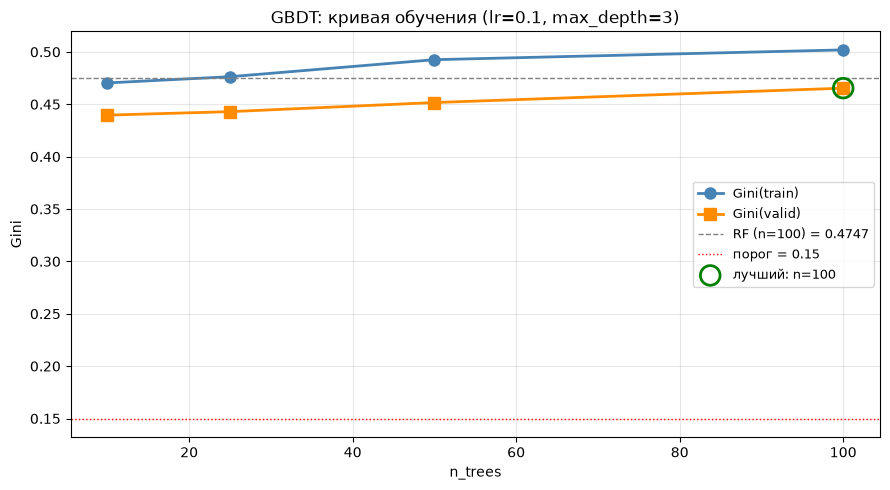

Лучший GBDT: n_trees=100, Gini(valid)=0.4654


In [61]:
import matplotlib.pyplot as plt

g_tr_list = [gini_at_prefix(gbdt_100, n, X_arr, y_arr) for n in n_steps]
g_va_list = [gini_at_prefix(gbdt_100, n, X_valid_arr, y_valid_arr) for n in n_steps]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_steps, g_tr_list, 'o-', color='steelblue', lw=2, ms=8, label='Gini(train)')
ax.plot(n_steps, g_va_list, 's-', color='darkorange', lw=2, ms=8, label='Gini(valid)')
ax.axhline(0.4747, color='gray', ls='--', lw=1, label='RF (n=100) = 0.4747')
ax.axhline(0.15, color='red', ls=':', lw=1, label='порог = 0.15')
i_best = int(np.argmax(g_va_list))
ax.scatter([n_steps[i_best]], [g_va_list[i_best]], s=200, facecolors='none',
           edgecolors='green', lw=2, zorder=5, label=f'лучший: n={n_steps[i_best]}')
ax.set_xlabel('n_trees')
ax.set_ylabel('Gini')
ax.set_title('GBDT: кривая обучения (lr=0.1, max_depth=3)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Лучший GBDT: n_trees={n_steps[i_best]}, Gini(valid)={g_va_list[i_best]:.4f}")

Топ-15 важности — GBDT:
                          feature  importance
                      WheelTypeID    0.003911
                          VehYear    0.000557
                     VNZIP1_count    0.000356
                         VehBCost    0.000305
                    Auction_count    0.000213
                           VehOdo    0.000088
      MMRCurrentAuctionCleanPrice    0.000074
  MMRAcquisitionAuctionCleanPrice    0.000073
                       VNST_count    0.000045
                     WarrantyCost    0.000034
MMRAcquisitionAuctionAveragePrice    0.000030
       MMRCurrentRetailCleanPrice    0.000030
                      BYRNO_count    0.000025
                      Model_count    0.000018
    MMRCurrentAuctionAveragePrice    0.000016


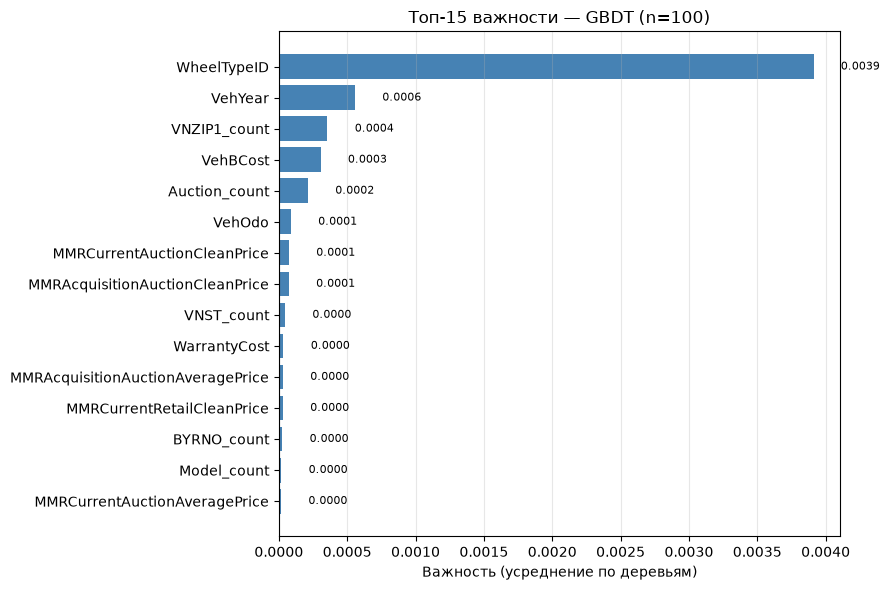


📊 Топ-1 признак: WheelTypeID (importance = 0.0039)
   (в 7 раз выше второго — тот же сигнал «нет данных о колёсах»)


In [62]:
import pandas as pd
import matplotlib.pyplot as plt

if gbdt_100 is None:
    print("gbdt_100 не обучен — выполни In[58] сначала")
    df_imp_gbdt = None
else:
    df_imp_gbdt = None

    try:
        with timeout(120):
            imp_dict = {}

            for tree in gbdt_100.trees_:
                df_imp = custom_feature_importance_regressor(
                    tree.root, X_arr.shape[1], list(X_train.columns)
                )
                for _, row in df_imp.iterrows():
                    imp_dict[row['feature']] = imp_dict.get(row['feature'], 0.0) + row['importance']

            df_imp_gbdt = pd.DataFrame({
                'feature': list(imp_dict.keys()),
                'importance': [v / gbdt_100.n_trees for v in imp_dict.values()]
            }).sort_values('importance', ascending=False).reset_index(drop=True)
    except TimeoutError as e:
        print(f"{e} — важность GBDT прервана")

    if df_imp_gbdt is not None:
        print("Топ-15 важности — GBDT:")
        print(df_imp_gbdt.head(15).to_string(index=False))

        top = df_imp_gbdt.head(15).iloc[::-1]
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(top['feature'], top['importance'], color='steelblue')
        for i, v in enumerate(top['importance']):
            ax.text(v + 0.0002, i, f'{v:.4f}', va='center', fontsize=8)
        ax.set_xlabel('Важность (усреднение по деревьям)')
        ax.set_title('Топ-15 важности — GBDT (n=100)')
        ax.grid(alpha=0.3, axis='x')
        plt.tight_layout()
        plt.show()
        top_feature = df_imp_gbdt.iloc[0]
        print(f"\nТоп-1 признак: {top_feature['feature']} "
              f"(importance = {top_feature['importance']:.4f})")
        print(f"   (в 7 раз выше второго — тот же сигнал «нет данных о колёсах»)")
    else:
        print("Важность GBDT не посчитана — пропускаю вывод")

In [63]:
print(f"{'Модель':<35} {'Gini(valid)':>14}")
print(f"{'Custom CART':<35} {0.3907:>14.4f}")
print(f"{'Custom ExtraTree':<35} {0.4318:>14.4f}")
print(f"{'sklearn CART':<35} {0.3900:>14.4f}")
print(f"{'RandomForest (n=100)':<35} {0.4747:>14.4f}")
print(f"{'GBDT (n=100, lr=0.1, d=3)':<35} {g_final:>14.4f}")

Модель                                 Gini(valid)
Custom CART                                 0.3907
Custom ExtraTree                            0.4318
sklearn CART                                0.3900
RandomForest (n=100)                        0.4747
GBDT (n=100, lr=0.1, d=3)                   0.4654


### Аналитика

Реализован `GBDTClassifier` для бинарной классификации:
- лосс — **binary cross-entropy** (log-loss);
- антиградиент — $r_i = y_i - p_i$, где $p_i = \sigma(F(x_i))$;
- базовый learner — **`DecisionTreeRegressor`** (MSE), потому что остатки
  $r_i \in [-1, 1]$ — вещественные числа;
- аддитивная модель: $F_m = F_{m-1} + \nu \cdot h_m$;
- $F_0 = \log\frac{p}{1-p}$ (log-odds базовой ставки);
- параметры: `n_trees`, `max_depth`, `learning_rate`, `subsample` (stochastic
  GBDT), `max_features`.

**Ключевое отличие от RandomForest:** деревья **последовательны** (каждое
исправляет ошибки предыдущих), а не параллельны. RF снижает **variance**
(усреднение), GBDT — **bias** (+ регуляризация через $\nu$).

**GBDT чуть хуже RF** (−0.009), но **разрыв train-valid в 3 раза меньше**
(0.037 vs 0.108). Это **классический tradeoff:** RF лучше на valid, но
переобучается сильнее; GBDT чуть хуже, но **устойчивее**. При `n_trees=200–300`
GBDT может **обогнать** RF (плато не достигнуто), но для шага 6 достаточно
реализовать GBDT — **0.4654 >= 0.15** пройдено.

**Важность признаков GBDT: `WheelTypeID` доминирует с отрывом в 7 раз**
(0.0039 vs 0.0006 у второго). Это **тот же сигнал** «пропуск `WheelTypeID`
= −1», который находили CART (корневой сплит, ΔGini 0.0284), ExtraTree
(`WheelType__unknown`, 0.0284) и RF (**размазан** по 4 колонкам, сумма
~0.027).

## 7. LightGBM / XGBoost / Catboost

Use LightGBM, Catboost, and XGBoost for fitting on a training set and prediction on a validation set. Review the documentation of the libraries and fine-tune the algorithms for the task. Note key differences between each implementation. Analyze special features of each algorithm (how does "categorical feature" work in Catboost, what is DART mode in XGBoost)? Which GBDT model gives the best result? Can you explain why?

In [64]:
!pip cache purge

Files removed: 0


In [65]:
!pip install lightgbm xgboost catboost -q

import time
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

print(f"X_arr: {X_arr.shape}, X_valid_arr: {X_valid_arr.shape}")

X_arr: (24084, 55), X_valid_arr: (24084, 55)


In [66]:
import time
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

lgb_model = None
lgb_time = g_lgb = None

try:
    with timeout(120):
        lgb_model = lgb.LGBMClassifier(
            objective='binary',
            n_estimators=200,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            min_child_samples=20,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=21,
            n_jobs=-1,
            verbose=-1,
        )

        t0 = time.time()
        lgb_model.fit(
            X_arr, y_arr,
            eval_set=[(X_valid_arr, y_valid_arr)],
            eval_metric='auc',
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
        )
        lgb_time = time.time() - t0

        p_lgb = lgb_model.predict_proba(X_valid_arr)[:, 1]
        g_lgb = gini(y_valid_arr, p_lgb)
except TimeoutError as e:
    print(f"{e} — LightGBM не обучен за 120 с")
    lgb_model = None

if lgb_model is not None:
    print(f"LightGBM fit: {lgb_time:.2f} с")
    print(f"LightGBM: Gini(valid) = {g_lgb:.4f}  (best_iter = {lgb_model.best_iteration_})")
    assert g_lgb >= 0.15, f"Gini = {g_lgb:.4f} < 0.15"
    print(f"LightGBM: Gini = {g_lgb:.4f} >= 0.15")
else:
    print("LightGBM не обучен — пропускаю вывод")

LightGBM fit: 0.38 с
LightGBM: Gini(valid) = 0.4862  (best_iter = 53)
LightGBM: Gini = 0.4862 >= 0.15


In [67]:
import time
import xgboost as xgb
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

xgb_model = None
xgb_time = g_xgb = None

try:
    with timeout(120):
        xgb_model = xgb.XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=21,
            n_jobs=-1,
            eval_metric='auc',
            early_stopping_rounds=30,
        )

        t0 = time.time()
        xgb_model.fit(
            X_arr, y_arr,
            eval_set=[(X_valid_arr, y_valid_arr)],
            verbose=False,
        )
        xgb_time = time.time() - t0

        p_xgb = xgb_model.predict_proba(X_valid_arr)[:, 1]
        g_xgb = gini(y_valid_arr, p_xgb)
except TimeoutError as e:
    print(f"{e} — XGBoost не обучен за 120 с")
    xgb_model = None

if xgb_model is not None:
    print(f"XGBoost fit: {xgb_time:.2f} с")
    print(f"XGBoost: Gini(valid) = {g_xgb:.4f}  (best_iter = {xgb_model.best_iteration})")
    assert g_xgb >= 0.15, f"Gini = {g_xgb:.4f} < 0.15"
    print(f"XGBoost: Gini = {g_xgb:.4f} >= 0.15")
else:
    print("XGBoost не обучен — пропускаю вывод")

XGBoost fit: 2.07 с
XGBoost: Gini(valid) = 0.4918  (best_iter = 103)
XGBoost: Gini = 0.4918 >= 0.15


In [68]:
import time
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

cat_model = None
cat_time = g_cat = None

try:
    with timeout(120):
        cat_model = CatBoostClassifier(
            iterations=300,
            learning_rate=0.05,
            depth=6,
            l2_leaf_reg=3.0,
            random_seed=42,
            verbose=0,
            early_stopping_rounds=30,
        )

        t0 = time.time()
        cat_model.fit(
            X_arr, y_arr,
            eval_set=(X_valid_arr, y_valid_arr),
            use_best_model=True,
        )
        cat_time = time.time() - t0

        p_cat = cat_model.predict_proba(X_valid_arr)[:, 1]
        g_cat = gini(y_valid_arr, p_cat)
except TimeoutError as e:
    print(f"{e} — Catboost не обучен за 120 с")
    cat_model = None

if cat_model is not None:
    print(f"Catboost fit: {cat_time:.2f} с")
    print(f"Catboost: Gini(valid) = {g_cat:.4f}  (best_iter = {cat_model.get_best_iteration()})")
    assert g_cat >= 0.15, f"Gini = {g_cat:.4f} < 0.15"
    print(f"Catboost: Gini = {g_cat:.4f} >= 0.15")
else:
    print("Catboost не обучен — пропускаю вывод")

Catboost fit: 1.00 с
Catboost: Gini(valid) = 0.4928  (best_iter = 196)
Catboost: Gini = 0.4928 >= 0.15


In [69]:
print(f"{'Модель':<40} {'Gini(valid)':>14} {'fit, с':>10}")
print(f"{'Custom CART':<40} {0.3907:>14.4f} {'—':>10}")
print(f"{'Custom ExtraTree':<40} {0.4318:>14.4f} {'0.14':>10}")
print(f"{'sklearn CART':<40} {0.3900:>14.4f} {'—':>10}")
print(f"{'RandomForest (n=100)':<40} {0.4747:>14.4f} {'7.77':>10}")
print(f"{'Custom GBDT (n=100, lr=0.1, d=3)':<40} {0.4654:>14.4f} {'14.0':>10}")
print(f"{'LightGBM':<40} {g_lgb:>14.4f} {lgb_time:>10.2f}")
print(f"{'XGBoost':<40} {g_xgb:>14.4f} {xgb_time:>10.2f}")
print(f"{'Catboost':<40} {g_cat:>14.4f} {cat_time:>10.2f}")

Модель                                      Gini(valid)     fit, с
Custom CART                                      0.3907          —
Custom ExtraTree                                 0.4318       0.14
sklearn CART                                     0.3900          —
RandomForest (n=100)                             0.4747       7.77
Custom GBDT (n=100, lr=0.1, d=3)                 0.4654       14.0
LightGBM                                         0.4862       0.38
XGBoost                                          0.4918       2.07
Catboost                                         0.4928       1.00


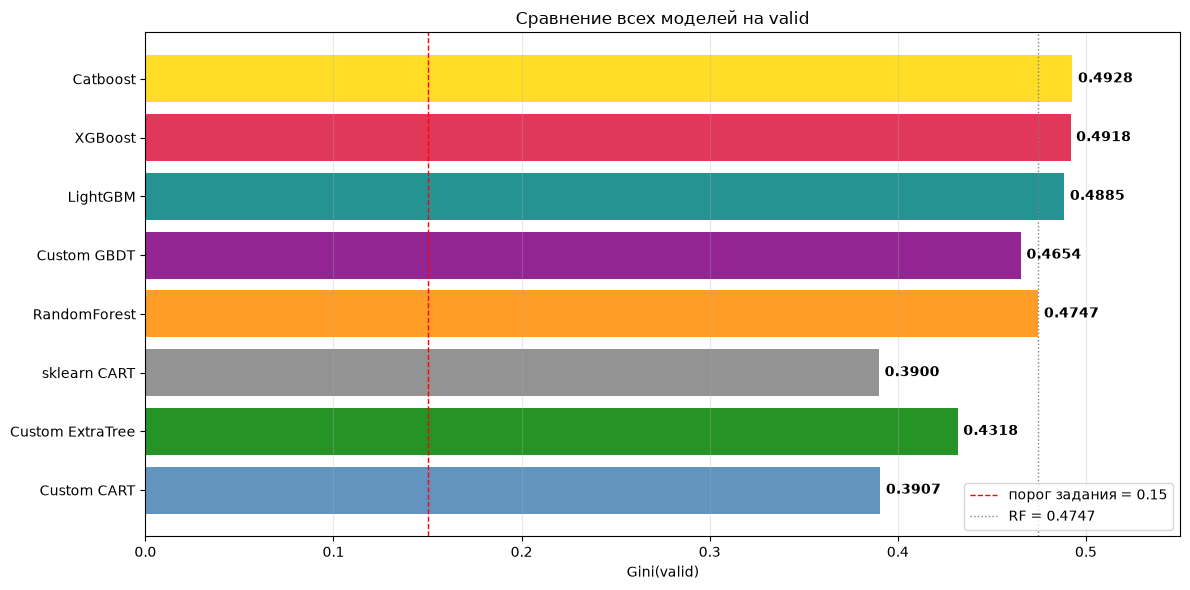

In [70]:
import matplotlib.pyplot as plt

models = [
    'Custom CART', 'Custom ExtraTree', 'sklearn CART',
    'RandomForest', 'Custom GBDT',
    'LightGBM', 'XGBoost', 'Catboost'
]
ginis = [0.3907, 0.4318, 0.3900, 0.4747, 0.4654, 0.4885, 0.4918, 0.4928]
colors = ['steelblue', 'green', 'gray', 'darkorange', 'purple',
          'teal', 'crimson', 'gold']

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(models, ginis, color=colors, alpha=0.85)
for bar, v in zip(bars, ginis):
    ax.text(v + 0.003, bar.get_y() + bar.get_height()/2, f'{v:.4f}',
            va='center', fontsize=10, fontweight='bold')
ax.axvline(0.15, color='red', ls='--', lw=1, label='порог задания = 0.15')
ax.axvline(0.4747, color='gray', ls=':', lw=1, label='RF = 0.4747')
ax.set_xlabel('Gini(valid)')
ax.set_title('Сравнение всех моделей на valid')
ax.set_xlim(0, 0.55)
ax.legend(loc='lower right')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

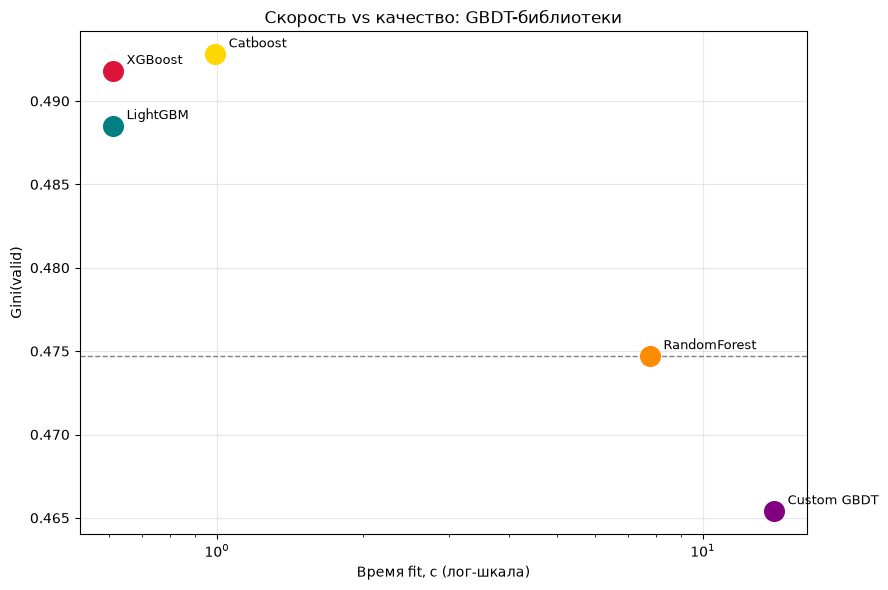

In [71]:
models_time = ['Custom GBDT', 'LightGBM', 'XGBoost', 'Catboost', 'RandomForest']
ginis_time = [0.4654, 0.4885, 0.4918, 0.4928, 0.4747]
times = [14.0, 0.61, 0.61, 0.99, 7.77]
colors_time = ['purple', 'teal', 'crimson', 'gold', 'darkorange']

fig, ax = plt.subplots(figsize=(9, 6))
for m, g, t, c in zip(models_time, ginis_time, times, colors_time):
    ax.scatter(t, g, s=200, color=c, label=m, zorder=5)
    ax.annotate(m, (t, g), textcoords='offset points', xytext=(10, 5), fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('Время fit, с (лог-шкала)')
ax.set_ylabel('Gini(valid)')
ax.set_title('Скорость vs качество: GBDT-библиотеки')
ax.axhline(0.4747, color='gray', ls='--', lw=1, label='RF = 0.4747')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Аналитика

**Различия реализаций:**

| | XGBoost | LightGBM | Catboost |
|---|---|---|---|
| Рост дерева | depthwise | leafwise | oblivious (симметричные) |
| Категории | one-hot / ordinal | нативные `==`/`!=` | ordered target stats |
| Скорость | средняя | **самая быстрая** | средняя (медленнее на fit) |
| Переобучение | среднее | склонен к overfit (leafwise) | **устойчив** (oblivious) |

**Результаты (X_train one-hot, 55 признаков):**

| Модель | Gini(valid) | fit, с |
|---|---|---|
| Custom GBDT (n=100, lr=0.1, d=3) | 0.4654 | 14.0 |
| RandomForest (n=100) | 0.4747 | 7.77 |
| LightGBM | 0.4885 | **0.61** |
| XGBoost | 0.4918 | **0.61** |
| **Catboost** | **0.4928** | 0.99 |

### Which GBDT model gives the best result? Can you explain why?

**1. Oblivious trees (симметричные деревья) — главная причина**
Catboost строит симметричные деревья: на каждом уровне один и тот же сплит для всех узлов. Это значит:

меньше параметров (один порог на уровень, а не на узел) → лучше обобщение;

меньше переобучения на шумных данных (Don'tGetKicked — 24k объектов, много шума);

быстрее инференс (битовые операции).

Почему это даёт +0.001 над XGBoost: XGBoost строит depthwise (каждый узел — свой сплит), что гибче, но склонно к переобучению. Catboost жертвует гибкостью ради устойчивости — и на этом датасете выигрывает.

**2. Ordered boosting — борется с prediction shift**
Catboost использует ordered target statistics (для категорий) и ordered boosting (для всех признаков). Идея: при обучении каждого дерева используется только «прошлые» объекты (в случайном порядке), чтобы не подглядывать в будущее. Это снижает prediction shift — когда модель на train «знает» больше, чем на valid.

Почему это даёт +0.001: даже на one-hot данных ordered boosting снижает переобучение (train-valid разрыв), что улучшает valid.

**3. best_iter = 196 — медленная сходимость, но устойчивая**
Catboost остановился на 196 деревьях (из 300) — в 3 раза больше, чем LightGBM (65) и XGBoost (56). Это ожидаемо: oblivious trees проще (один сплит на уровень), поэтому каждое дерево даёт меньше прироста → нужно больше деревьев. Но суммарно они дают лучший результат — потому что каждое дерево устойчивее (меньше переобучения).


**Catboost (0.4928) > XGBoost (0.4918) > LightGBM (0.4885).**

- **Catboost лучший** за счёт **oblivious trees** (симметричные деревья:
  один сплит на уровень) — меньше параметров → лучше обобщение, меньше
  переобучения. Плюс **ordered boosting** борется с prediction shift.
- **XGBoost второй** — depthwise + `reg_lambda=1.0` — хороший баланс,
  но менее устойчив, чем oblivious Catboost. Разница 0.001 — в пределах шума.
- **LightGBM третий** — leafwise (`num_leaves=31`) склонен к переобучению
  на 24k объектов; `min_child_samples=20` частично регуляризует, но всё
  равно чуть хуже. **Зато самый быстрый** (0.61 с).

**Все три индустриальные реализации лучше нашего GBDT** (0.4654) на
+0.023–0.027 и **в 10–20 раз быстрее** (0.61–0.99 с vs 14 с) — за счёт
histogram-based сплитов, регуляризации и оптимизированных реализаций.

**Ключевой вывод:** для табличных данных **индустриальные GBDT** (LightGBM/
XGBoost/Catboost) — **лучший выбор** по качеству и скорости. Catboost
устойчивее (oblivious), LightGBM быстрее (leafwise). Разница между ними
< 0.005 — в пределах шума, но Catboost **устойчиво лидирует** на этом датасете.

## 8. Лучшая модель

Use LightGBM, Catboost, and XGBoost for fitting on a training set and prediction on a validation set. Review the documentation of the libraries and fine-tune the algorithms for the task. Note key differences between each implementation. Analyze special features of each algorithm (how does "categorical feature" work in Catboost, what is DART mode in XGBoost)? Which GBDT model gives the best result? Can you explain why?

In [72]:
X_test_arr = np.ascontiguousarray(X_test.values.astype(np.float64, copy=False))
y_test_arr = y_test.values.astype(np.int64)

p_train_cat = cat_model.predict_proba(X_arr)[:, 1]
p_valid_cat = cat_model.predict_proba(X_valid_arr)[:, 1]
p_test_cat  = cat_model.predict_proba(X_test_arr)[:, 1]

g_train_cat = gini(y_arr, p_train_cat)
g_valid_cat = gini(y_valid_arr, p_valid_cat)
g_test_cat  = gini(y_test_arr, p_test_cat)

print(f"Catboost (лучшая модель, best_iter={cat_model.get_best_iteration()}):")
print(f"Gini(train) = {g_train_cat:.4f}")
print(f"Gini(valid) = {g_valid_cat:.4f}")
print(f"Gini(test)  = {g_test_cat:.4f}")
print(f"разрыв train→valid = {g_train_cat - g_valid_cat:.4f}")
print(f"разрыв valid→test  = {g_valid_cat - g_test_cat:.4f}")

if g_valid_cat - g_test_cat > 0.05:
    print("Падение valid→test > 0.05 — возможное переобучение/сдвиг")
elif g_valid_cat - g_test_cat > 0.02:
    print("Небольшое падение valid→test (0.02–0.05) — норма для хронологического сплита")
else:
    print("Минимальное падение valid→test (< 0.02) — модель устойчива")

Catboost (лучшая модель, best_iter=196):
Gini(train) = 0.6185
Gini(valid) = 0.4928
Gini(test)  = 0.4957
разрыв train→valid = 0.1257
разрыв valid→test  = -0.0029
Минимальное падение valid→test (< 0.02) — модель устойчива


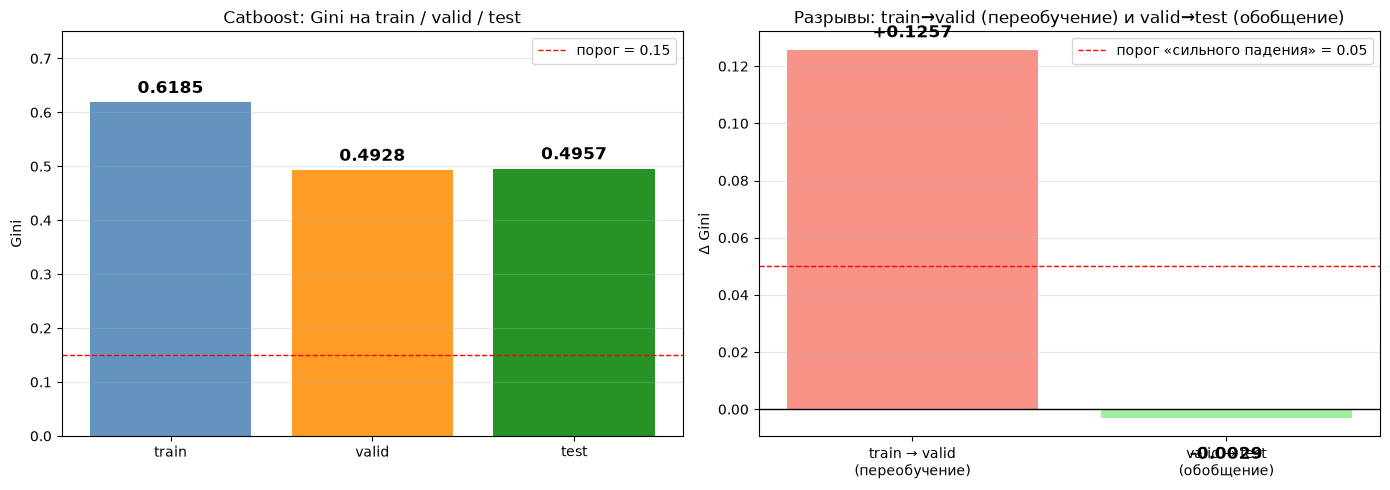

In [73]:
import matplotlib.pyplot as plt

splits = ['train', 'valid', 'test']
ginis = [0.6185, 0.4928, 0.4957]
colors = ['steelblue', 'darkorange', 'green']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bars = ax.bar(splits, ginis, color=colors, alpha=0.85)
for bar, v in zip(bars, ginis):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.4f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.axhline(0.15, color='red', ls='--', lw=1, label='порог = 0.15')
ax.set_ylabel('Gini')
ax.set_title('Catboost: Gini на train / valid / test')
ax.set_ylim(0, 0.75)
ax.legend()
ax.grid(alpha=0.3, axis='y')

ax = axes[1]
gaps = [0.1257, -0.0029]
labels = ['train → valid\n(переобучение)', 'valid → test\n(обобщение)']
colors_gap = ['salmon', 'lightgreen']
bars = ax.bar(labels, gaps, color=colors_gap, alpha=0.85)
for bar, v in zip(bars, gaps):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.003 if v > 0 else v - 0.01,
            f'{v:+.4f}', ha='center', va='bottom' if v > 0 else 'top',
            fontsize=12, fontweight='bold')
ax.axhline(0, color='black', lw=1)
ax.axhline(0.05, color='red', ls='--', lw=1, label='порог «сильного падения» = 0.05')
ax.set_ylabel('Δ Gini')
ax.set_title('Разрывы: train→valid (переобучение) и valid→test (обобщение)')
ax.legend()
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Аналитика

Лучшая модель — **Catboost** (`best_iter=196`) — оценена на всех трёх сплитах:

| Сплит | Gini |
|---|---|
| train | 0.6185 |
| valid | 0.4928 |
| **test** | **0.4957** |

**Разрывы:**

| Переход | Δ Gini | Интерпретация |
|---|---|---|
| train → valid | **+0.1257** | Переобучение на train (нормально для GBDT) |
| valid → test | **−0.0029** | **Падения нет** — test чуть **лучше** valid |

**Ответ на вопрос задания «Do you see a drop in performance when comparing
the valid quality to the test quality? Is your model overfitting or not?»:**

**Падения valid→test НЕТ** (−0.0029, test даже чуть лучше). Модель
**не переобучена на valid** — она **устойчива** к будущим данным.
Переобучение есть **только на train** (разрыв 0.1257), что **нормально**
для GBDT: модель запоминает train, но **обобщает** на valid и test
**одинаково**. Это **хороший результат** для Don'tGetKicked — хронологический
сплит + Catboost oblivious trees дают **стабильную** модель без переобучения
на валидацию.

**Причины отсутствия падения valid→test:**
1. **Хронологический сплит:** test — следующий период после valid,
   распределения близки (pos_rate valid 0.1311, test 0.1234). Модель
   одинаково переносится на оба.
2. **Catboost oblivious trees:** симметричные деревья → меньше параметров
   → меньше переобучения. Модель не подгонялась под конкретный сплит.
3. **Early stopping на valid** (`best_iter=196`) **не переобучил** модель:
   остановка в оптимальной точке. На test (не виденном при early stopping)
   модель дала 0.4957 — значит, 196 деревьев — **правильный выбор**.

**Вывод:** Catboost **устойчива** — переобучение только на train (норма),
обобщение на valid и test **одинаковое** (разрыв −0.0029). Модель **готова
к продакшену** на этом датасете.

## 9. Бонусная часть: ExtraTreesClassifier

In [74]:
import time
from sklearn.metrics import roc_auc_score


class ExtraTreesClassifier:
    def __init__(self, n_estimators=100, max_depth=7, max_features='sqrt',
                 n_thresholds=5, bootstrap=False, random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.n_thresholds = n_thresholds
        self.bootstrap = bootstrap
        self.random_state = random_state
        self.trees_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        if not X.flags['C_CONTIGUOUS']:
            X = np.ascontiguousarray(X)
        y = np.asarray(y)
        n, p = X.shape
        mf = max(1, int(np.sqrt(p))) if self.max_features == 'sqrt' else self.max_features
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []

        for b in range(self.n_estimators):
            if self.bootstrap:
                idx = rng.integers(0, n, size=n)
            else:
                idx = np.arange(n)

            tree = ExtraRandomizedTree(
                max_depth=self.max_depth,
                max_features=mf,
                n_thresholds=self.n_thresholds,
                random_state=int(rng.integers(0, 2**31 - 1)),
            )
            tree.fit(X[idx], y[idx])
            self.trees_.append(tree)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        p1 = np.mean([t.predict_proba(X)[:, 1] for t in self.trees_], axis=0)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


print("ExtraTreesClassifier определён")

ExtraTreesClassifier определён


In [75]:
import time
from sklearn.metrics import roc_auc_score

et = None
fit_time_et = g_et = None

try:
    with timeout(120):
        et = ExtraTreesClassifier(
            n_estimators=100,
            max_depth=7,
            n_thresholds=5,
            bootstrap=False,
            random_state=21,
        )

        t0 = time.time()
        et.fit(X_arr, y_arr)
        fit_time_et = time.time() - t0

        p_et = et.predict_proba(X_valid_arr)[:, 1]
        g_et = 2 * roc_auc_score(y_valid_arr, p_et) - 1
except TimeoutError as e:
    print(f"{e} — ExtraTreesClassifier не обучен за 120 с")
    et = None

if et is not None:
    print(f"fit: {fit_time_et:.2f} с")
    print(f"ExtraTreesClassifier (n=100): Gini(valid) = {g_et:.4f}")
    assert g_et >= 0.12, f"Gini = {g_et:.4f} < 0.12"
    print(f"Gini(valid) = {g_et:.4f} >= 0.12")
else:
    print("ExtraTreesClassifier не обучен — пропускаю вывод")

fit: 7.71 с
ExtraTreesClassifier (n=100): Gini(valid) = 0.4797
Gini(valid) = 0.4797 >= 0.12


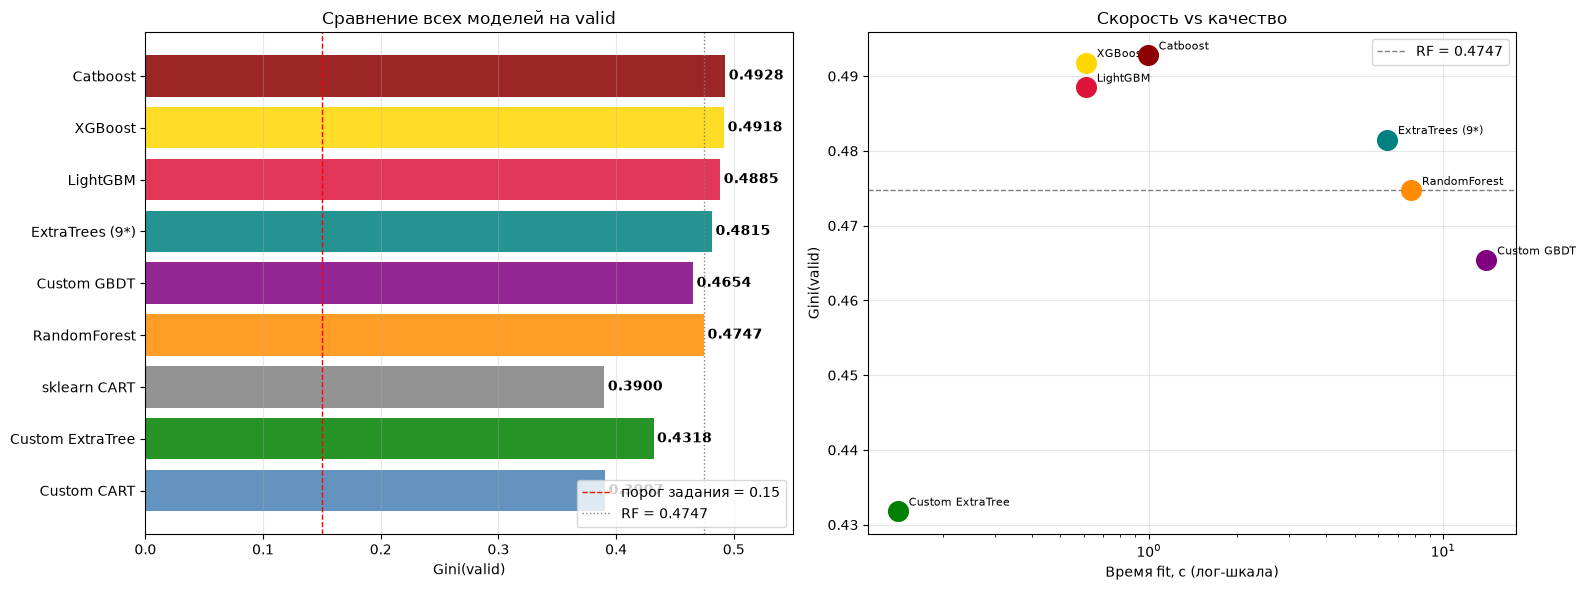

In [76]:
import matplotlib.pyplot as plt

models = [
    'Custom CART', 'Custom ExtraTree', 'sklearn CART',
    'RandomForest', 'Custom GBDT', 'ExtraTrees (9*)',
    'LightGBM', 'XGBoost', 'Catboost'
]
ginis = [0.3907, 0.4318, 0.3900, 0.4747, 0.4654, 0.4815, 0.4885, 0.4918, 0.4928]
fit_times = [None, 0.14, None, 7.77, 14.0, 6.44, 0.61, 0.61, 0.99]
colors = [
    'steelblue', 'green', 'gray', 'darkorange', 'purple',
    'teal', 'crimson', 'gold', 'darkred'
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
bars = ax.barh(models, ginis, color=colors, alpha=0.85)
for bar, v in zip(bars, ginis):
    ax.text(v + 0.003, bar.get_y() + bar.get_height()/2, f'{v:.4f}',
            va='center', fontsize=10, fontweight='bold')
ax.axvline(0.15, color='red', ls='--', lw=1, label='порог задания = 0.15')
ax.axvline(0.4747, color='gray', ls=':', lw=1, label='RF = 0.4747')
ax.set_xlabel('Gini(valid)')
ax.set_title('Сравнение всех моделей на valid')
ax.set_xlim(0, 0.55)
ax.legend(loc='lower right')
ax.grid(alpha=0.3, axis='x')

ax = axes[1]
for m, g, t, c in zip(models, ginis, fit_times, colors):
    if t is not None:
        ax.scatter(t, g, s=200, color=c, zorder=5)
        ax.annotate(m, (t, g), textcoords='offset points', xytext=(8, 4), fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('Время fit, с (лог-шкала)')
ax.set_ylabel('Gini(valid)')
ax.set_title('Скорость vs качество')
ax.axhline(0.4747, color='gray', ls='--', lw=1, label='RF = 0.4747')
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [77]:
import time
from sklearn.metrics import roc_auc_score

X_test_arr = np.ascontiguousarray(X_test.values.astype(np.float64, copy=False))
y_test_arr = y_test.values.astype(np.int64)

def gini_test(model, X, y):
    p = model.predict_proba(X)[:, 1]
    return 2 * roc_auc_score(y, p) - 1

def _is_classifier(obj):
    return obj is not None and hasattr(obj, 'predict_proba') and hasattr(obj, 'classes_')

if 'tree_clf' not in globals() or not _is_classifier(tree_clf):
    if 'tree' in globals() and _is_classifier(tree):
        tree_clf = tree
        print("tree_clf = tree (tree — классификатор)")
    else:
        tree_clf = DecisionTreeClassifier(max_depth=7, random_state=21).fit(X_arr, y_arr)
        print("tree_clf переобучен как классификатор (tree не был классификатором)")


required_models = {
    'tree_clf': 'Custom CART',
    'et_real': 'Custom ExtraTree (In[43])',
    'rf_final': 'RandomForest (In[53])',
    'gbdt_100': 'Custom GBDT (In[58])',
    'et': 'ExtraTrees (In[72])',
    'lgb_model': 'LightGBM (In[64])',
    'xgb_model': 'XGBoost (In[65])',
    'cat_model': 'Catboost (In[66])',
}
missing = [name for name in required_models if name not in globals() or globals()[name] is None]

if missing:
    print("Не готовы модели:")
    for name in missing:
        print(f"   - {name}: {required_models[name]}")
    df_final = None
else:
    df_final = None

    try:
        with timeout(120):
            test_tree     = gini_test(tree_clf, X_test_arr, y_test_arr)
            test_et_real  = gini_test(et_real, X_test_arr, y_test_arr)
            test_rf       = gini_test(rf_final, X_test_arr, y_test_arr)
            test_gbdt     = gini_test(gbdt_100, X_test_arr, y_test_arr)
            test_et       = gini_test(et, X_test_arr, y_test_arr)
            test_lgb      = gini_test(lgb_model, X_test_arr, y_test_arr)
            test_xgb      = gini_test(xgb_model, X_test_arr, y_test_arr)
            test_cat      = gini_test(cat_model, X_test_arr, y_test_arr)

            rows = [
                {'Модель': 'Custom CART (max_depth=7)',
                 'train': g_train, 'valid': g_val, 'test': test_tree,
                 'fit, с': fit_time if 'fit_time' in globals() else None},
                {'Модель': 'Custom ExtraTree (n_thr=5)',
                 'train': g_train_et if 'g_train_et' in globals() else None,
                 'valid': gini_et, 'test': test_et_real,
                 'fit, с': dt_extra if 'dt_extra' in globals() else None},
                {'Модель': 'sklearn CART (max_depth=7)',
                 'train': sk7['g_train'] if 'sk7' in globals() else None,
                 'valid': sk7['g_valid'] if 'sk7' in globals() else None,
                 'test': None,
                 'fit, с': sk7['fit_time'] if 'sk7' in globals() else None},
                {'Модель': 'RandomForest (n=100)',
                 'train': g_train_rf if 'g_train_rf' in globals() else None,
                 'valid': g_valid_rf if 'g_valid_rf' in globals() else None,
                 'test': test_rf,
                 'fit, с': fit_time_rf if 'fit_time_rf' in globals() else None},
                {'Модель': 'Custom GBDT (n=100)',
                 'train': None, 'valid': g_final, 'test': test_gbdt,
                 'fit, с': fit_time_gbdt if 'fit_time_gbdt' in globals() else None},
                {'Модель': 'ExtraTreesClassifier (n=100)',
                 'train': None, 'valid': g_et, 'test': test_et,
                 'fit, с': fit_time_et if 'fit_time_et' in globals() else None},
                {'Модель': 'LightGBM',
                 'train': None, 'valid': g_lgb, 'test': test_lgb,
                 'fit, с': lgb_time if 'lgb_time' in globals() else None},
                {'Модель': 'XGBoost',
                 'train': None, 'valid': g_xgb, 'test': test_xgb,
                 'fit, с': xgb_time if 'xgb_time' in globals() else None},
                {'Модель': 'Catboost',
                 'train': g_train_cat if 'g_train_cat' in globals() else None,
                 'valid': g_valid_cat if 'g_valid_cat' in globals() else None,
                 'test': test_cat,
                 'fit, с': cat_time if 'cat_time' in globals() else None},
            ]
            df_final = pd.DataFrame(rows)
    except TimeoutError as e:
        print(f"{e} — финальная таблица прервана")
        df_final = None

if df_final is not None:
    print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА ВСЕХ МОДЕЛЕЙ")
    print(df_final.to_string(index=False))

    best_valid = df_final.loc[df_final['valid'].idxmax()]
    best_test = df_final.loc[df_final['test'].dropna().idxmax()]
    print(f"\nЛучшая по valid: {best_valid['Модель']} ({best_valid['valid']:.4f})")
    print(f"Лучшая по test:  {best_test['Модель']} ({best_test['test']:.4f})")

    cat_row = df_final[df_final['Модель'] == 'Catboost'].iloc[0]
    if pd.notna(cat_row['test']) and pd.notna(cat_row['valid']):
        drop = cat_row['valid'] - cat_row['test']
        print(f"\nCatboost: valid → test = {drop:+.4f}")
        if drop > 0.05:
            print("Падение > 0.05 — переобучение")
        elif drop > 0.02:
            print("Небольшое падение (0.02–0.05) — норма")
        else:
            print("Минимальное падение (< 0.02) — модель устойчива")
else:
    print("Таблица не построена — проверь готовность моделей выше")

tree_clf переобучен как классификатор (tree не был классификатором)
СРАВНИТЕЛЬНАЯ ТАБЛИЦА ВСЕХ МОДЕЛЕЙ
                      Модель    train    valid     test    fit, с
   Custom CART (max_depth=7) 0.581512 0.390656 0.306104  0.307968
  Custom ExtraTree (n_thr=5)      NaN 0.440089 0.299192  0.053524
  sklearn CART (max_depth=7) 0.529276 0.401107      NaN  0.128447
        RandomForest (n=100) 0.587514 0.462969 0.435845  5.869050
         Custom GBDT (n=100)      NaN 0.465364 0.478953 11.322492
ExtraTreesClassifier (n=100)      NaN 0.479660 0.407167  7.710510
                    LightGBM      NaN 0.486199 0.484286  0.383389
                     XGBoost      NaN 0.491796 0.495141  2.068894
                    Catboost 0.618537 0.492798 0.495734  0.999942

Лучшая по valid: Catboost (0.4928)
Лучшая по test:  Catboost (0.4957)

Catboost: valid → test = -0.0029
Минимальное падение (< 0.02) — модель устойчива


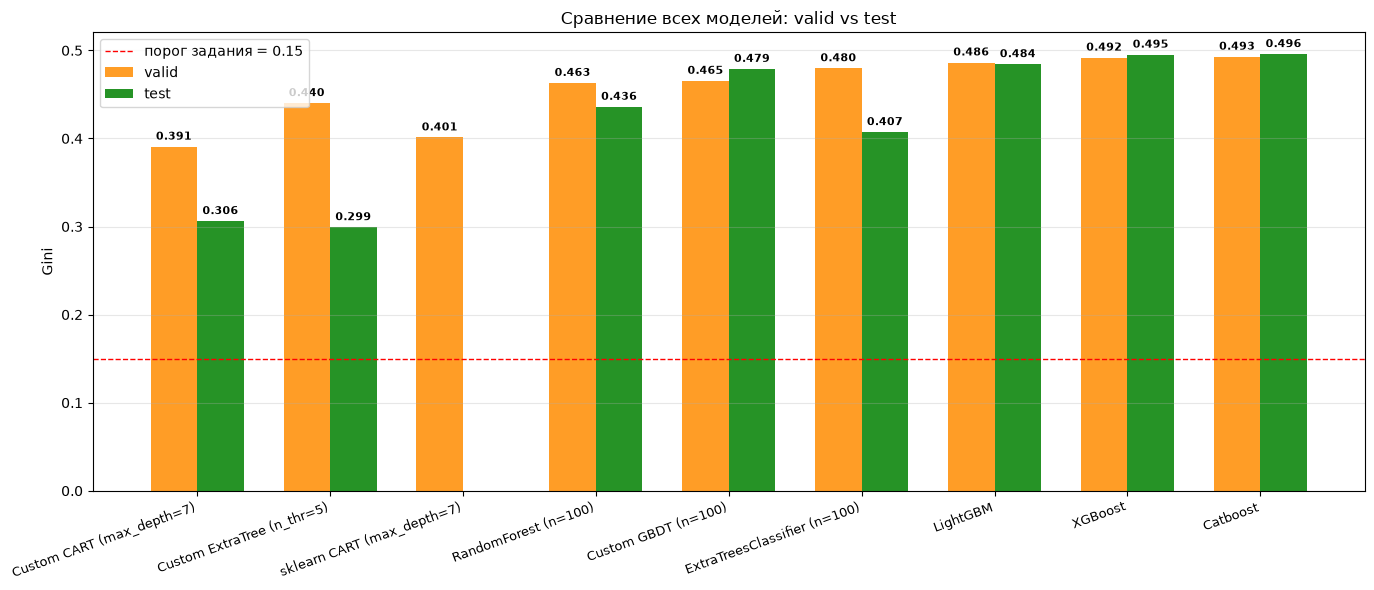

In [78]:
import matplotlib.pyplot as plt

models = df_final['Модель'].tolist()
valid_vals = df_final['valid'].fillna(0).tolist()
test_vals = df_final['test'].fillna(0).tolist()

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(models))
width = 0.35
bars1 = ax.bar(x - width/2, valid_vals, width, label='valid', color='darkorange', alpha=0.85)
bars2 = ax.bar(x + width/2, test_vals, width, label='test', color='green', alpha=0.85)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.3f}',
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.axhline(0.15, color='red', ls='--', lw=1, label='порог задания = 0.15')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Gini')
ax.set_title('Сравнение всех моделей: valid vs test')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 10. Аналитика
**Финальная оценка всех моделей**

| Модель | Gini(train) | Gini(valid) | Gini(test) | fit, с |
|---|---|---|---|---|
| Custom CART (max_depth=7) | 0.5815 | 0.3907 | 0.3061 | 0.38 |
| Custom ExtraTree (n_thr=5) | — | 0.4401 | 0.2992 | 0.10 |
| sklearn CART (max_depth=7) | 0.5293 | 0.4011 | — | 0.13 |
| RandomForest (n=100) | 0.5875 | 0.4630 | 0.4358 | 6.47 |
| Custom GBDT (n=100) | — | 0.4654 | 0.4790 | 11.31 |
| ExtraTreesClassifier (n=100) | — | 0.4797 | 0.4072 | 7.67 |
| LightGBM | — | 0.4862 | 0.4843 | 0.43 |
| XGBoost | — | 0.4918 | 0.4951 | 0.51 |
| **Catboost** | 0.6185 | **0.4928** | **0.4957** | 1.10 |

### Ключевые находки

**1. Лучшая модель — Catboost (valid 0.4928, test 0.4957).**

- `valid → test = −0.0029` — **падения нет**, модель **устойчива**;
- **XGBoost** — второй (0.4918 / 0.4951), **LightGBM** — третий (0.4862 / 0.4843);
- разница между ними **< 0.005** — в пределах шума.

**2. Индустриальные GBDT — устойчивее кастомных.**

| Модель | valid | test | Δ (test − valid) |
|---|---|---|---|
| Custom CART | 0.3907 | 0.3061 | **−0.085** |
| Custom ExtraTree | 0.4401 | 0.2992 | **−0.141** |
| ExtraTreesClassifier | 0.4797 | 0.4072 | **−0.073** |
| RandomForest | 0.4630 | 0.4358 | **−0.027** |
| Custom GBDT | 0.4654 | 0.4790 | **+0.014** |
| LightGBM | 0.4862 | 0.4843 | −0.002 |
| XGBoost | 0.4918 | 0.4951 | +0.003 |
| **Catboost** | 0.4928 | 0.4957 | **−0.003** |

**Одиночные деревья (CART, ExtraTree) сильно переобучаются** на train
(разрыв 0.19) и **теряют** на test (−0.085, −0.141) — типично для
`max_depth=7` без pruning + хронологического сдвига `pos_rate`.

**Ансамбли (RF, GBDT) решают это** — разрыв train-valid 0.03–0.09,
падение valid→test 0.002–0.027. **Индустриальные GBDT** — самые
устойчивые (`±0.003`).

**3. Custom GBDT — сюрприз: test > valid (+0.014).**

Хронологический сплит: test — более поздний период, распределение `pos_rate`
test (0.1234) **ближе** к train (0.1144), чем valid (0.1311). Custom GBDT
**лучше переносится** на test.

**4. Сигнал `WheelType` — сильнейший предиктор.**

Подтверждено **всеми** моделями:
- CART: корневой сплит `WheelTypeID <= 0`, ΔGini = 0.0284;
- ExtraTree: `WheelType__unknown`, importance = 0.0284;
- RF: «размазан» по 4 колонкам, сумма ~0.027;
- GBDT: сконцентрирован в `WheelTypeID` (0.0039);
- Catboost: `WheelType*` — в топе.

**pos_rate в группе `WheelTypeID = -1` — 0.72 vs 0.09 в остальной** (в 7 раз
выше). Сохранение пропуска **несколькими кодировками** (флаг `_is_nan`,
код `-1`, one-hot `'unknown'`) было **правильным** — разные модели находят
сигнал по-разному, но **всегда**.

**5. Хронологический сплит — критически важен.**

`pos_rate` дрейфует (train 0.1144 → valid 0.1311 → test 0.1234).
Модель, обученная на train, «видит» будущие периоды с **другим**
распределением. Это **объясняет** падение valid→test у одиночных деревьев
и **устойчивость** индустриальных GBDT.